# Projeto PjBL — Acidentes em rodovias federais (2025)

**Grupo:** Giovanna Rita Santos Daniel; João Lucas do Prado Ribeiro; Leonardo Stall; Mirella Haisi Szvarça  
**Turma:** 6A

**Problema investigado:** compreender a distribuição dos acidentes em rodovias federais brasileiras, suas características temporais e de gravidade e a participação de condutores menores de idade. A base combina informações de acidentes, pessoas, veículos, causas e tipos de ocorrência. Por isso, antes de contar eventos ou envolvidos, é necessário identificar a unidade representada por cada registro.

**Método:** leitura e exploração da fonte, diagnóstico dos problemas de qualidade, limpeza com regras explícitas, transformação das variáveis necessárias e verificação da integridade dos dados resultantes. A ingestão, a limpeza, as transformações e a simulação de streaming utilizam PySpark. No RA3, pandas e NumPy são utilizados para as análises, Matplotlib para os gráficos e scikit-learn para a classificação supervisionada.

# Organização e decisões de processamento

Os dados são mantidos em três estágios para que os resultados possam ser conferidos sem sobrescrever a fonte. `df_original` preserva os registros lidos; `df_tratado` reúne as correções de ausência, plausibilidade e tipagem; `df_transformado` acrescenta variáveis úteis à análise. Conjuntos auxiliares representam acidentes, combinações acidente–tipo e pessoas identificadas, respeitando suas diferentes granularidades.

Essa separação evita que uma correção destrua a evidência original e permite comparar a quantidade de registros, os valores alterados e os tipos dos campos entre os estágios. As cinco perguntas de pesquisa direcionam as variáveis preparadas, sem substituir a verificação da qualidade por conclusões antecipadas.

**Cuidado de interpretação:** cada linha não representa necessariamente um acidente ou uma pessoa diferente. `mortos`, `ilesos`, `feridos_leves` e `feridos_graves` são indicadores 0/1 associados à pessoa na linha, não contagens totais do acidente.


## 1. Contexto e objetivo

Os acidentes em rodovias federais envolvem fatores geográficos, temporais, ambientais, veiculares e humanos. O problema investigado é compreender como essas características se relacionam com a ocorrência e a gravidade dos acidentes registrados em 2025. Antes de fazer comparações, é necessário reconhecer que a base é **agrupada por pessoa e por múltiplas causas/tipos**: o mesmo acidente pode aparecer em várias linhas. Contar linhas como se fossem acidentes produziria resultados incorretos.

**Perguntas de pesquisa que orientam a preparação:**

1. Como a quantidade de acidentes varia entre UFs e rodovias federais no período selecionado?
2. Como as ocorrências se distribuem entre meses, dias da semana e horários?
3. Como a proporção de acidentes com vítimas fatais varia entre os tipos de acidente?
4. Como a gravidade dos acidentes registrados varia entre condições meteorológicas e fases do dia?
5. Como a participação de condutores menores de idade nos acidentes varia entre tipos de veículo e UFs?

**Objetivo desta entrega:** carregar o arquivo, compreender sua estrutura e qualidade, justificar os tratamentos aplicados e criar transformações úteis às perguntas, preservando a granularidade e distinguindo informações ausentes de atributos não aplicáveis. As respostas quantitativas às perguntas serão desenvolvidas em análises posteriores.

**Unidade de observação.** `id` identifica um acidente; `pesid` representa uma pessoa identificada, mas nem toda linha possui esse identificador; `ordem_tipo_acidente` diferencia registros de tipo no mesmo acidente. A ausência de `pesid` não justifica eliminar automaticamente informações sobre o acidente. Por isso, cada cálculo e possível deduplicação exige uma chave coerente com a unidade estudada.

## 2. Fonte e ingestão dos dados

Esta seção identifica a procedência, o formato e o significado do arquivo e demonstra uma leitura reprodutível em PySpark. A decisão de **ler inicialmente tudo como texto** é intencional: impede que a inferência automática altere identificadores, converta marcadores de ausência sem controle ou interprete de modo errado decimais escritos com vírgula. Os tipos apropriados são atribuídos após a investigação e a limpeza, na seção 4.

**Fonte e caracterização dos dados**

- **Produtor:** Polícia Rodoviária Federal (PRF), base de dados de acidentes (BAT).
- **Catálogo oficial:** https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf
- **Recurso:** Documento CSV de Acidentes 2025 — *Agrupados por pessoa (Todas as causas e tipos de acidentes)*.
- **Dicionário oficial:** https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes
- **Arquivo de trabalho:** `acidentes2025_todas_causas_tipos.csv`.
- **Referência de acesso:** portal oficial da PRF, disponível no endereço acima. A data exata do download do grupo não está comprovada pelo arquivo e, portanto, não é atribuída.
- **Formato:** CSV delimitado por `;`, codificação `ISO-8859-1`, números decimais com vírgula, cabeçalho na primeira linha.
- **Dimensão verificada no arquivo anexado:** 584.010 linhas e 37 colunas, a serem reconfirmadas em PySpark na seção 3.1.
- **Atributos principais:** `id` (acidente), `pesid` (pessoa), `id_veiculo`, `data_inversa`, `horario`, `uf`, `br`, `km`, `tipo_acidente`, `classificacao_acidente`, `condicao_metereologica`, `fase_dia`, `tipo_envolvido`, `idade` e `tipo_veiculo`.

**Justificativa da ingestão:** a leitura inicial como `StringType` evita inferências prematuras e conserva marcadores de ausência, zeros e formatos necessários à auditoria. A conversão definitiva acontece apenas após a normalização e a validação na seção 4.

### 2.1 — Leitura controlada do CSV

O código cria a sessão Spark e lê o CSV com **delimitador `;` e codificação ISO-8859-1**. `inferSchema=False` preserva os valores recebidos; a conversão é feita somente depois da inspeção.

**Pré-requisitos e instruções de execução**

1. Abra o notebook em Jupyter, VS Code com suporte a notebooks ou Google Colab, usando um ambiente Python com as bibliotecas da célula seguinte. No ambiente local, instale também um **JDK compatível com o Spark**: recomenda-se **Java 17 LTS**. O PySpark 4.0 requer Java 17 ou superior e configuração adequada de `JAVA_HOME`, conforme a [documentação oficial](https://spark.apache.org/docs/4.0.0/api/python/getting_started/install.html). No terminal, `java -version` permite conferir a versão disponível. Se necessário, defina `JAVA_HOME` com o diretório real da instalação do JDK antes de iniciar o kernel. A instalação de PySpark por `pip` não substitui a instalação do Java.
2. Execute a célula de instalação abaixo no ambiente do próprio notebook. Como alternativa, se o arquivo acompanhar a entrega, use `pip install -r requirements_ra3.txt` nesse mesmo ambiente. Reinicie o kernel ou a sessão se a instalação solicitar. No Colab, confira também a disponibilidade do Java antes de iniciar o Spark.
3. Coloque `acidentes2025_todas_causas_tipos.csv` na pasta de trabalho do notebook; no Colab, envie o arquivo para `/content`. Se o CSV estiver em outro local, defina `os.environ['CAMINHO_DADOS']` com seu caminho completo, após `import os` e antes da célula de leitura. O código procura a variável de ambiente, a pasta atual e a pasta `/content`.
4. Execute as células em ordem: **RA1 → RA2 → RA3**. O RA1 cria `df_acidentes`, `df_acidente_tipo`, `df_pessoas`, `df_transformado` e `df_sem_pesid`, necessárias ao RA3. Para repetir apenas as análises do RA3 em uma sessão nova, execute primeiro o RA1 até a seção 5.4; a simulação do RA2 não é uma dependência dos cálculos do RA3.
5. Os gráficos são exibidos no notebook e salvos na pasta relativa `figuras_ra3/`. O RA2 utiliza `ra2_streaming_acidentes/` para seus arquivos fictícios e reinicializa essa pasta ao repetir a demonstração. Utilize uma pasta de trabalho na qual tenha permissão de escrita.
6. Para conferir a execução, a extração fornecida deve resultar em **584.010 linhas e 72.529 acidentes distintos**, no período de 01/01/2025 a 31/12/2025. Se utilizar outra extração ou outras versões das bibliotecas, confira novamente as saídas e as interpretações numéricas.

As tabelas e figuras da execução estão incorporadas ao notebook para leitura. Para recalcular os resultados, são necessários o CSV e o ambiente configurado. Nenhum caminho específico de computador pessoal é necessário para a leitura dos dados.

In [1]:
%pip install "pyspark>=4.0" "pandas<3" numpy matplotlib "pyarrow>=18" scikit-learn ipykernel

In [2]:
from pathlib import Path
from pyspark.sql import SparkSession, functions as F

# Resolva o CSV sem depender de um usuário específico.
import os
candidatos = [
    Path(os.environ.get('CAMINHO_DADOS', '')) if os.environ.get('CAMINHO_DADOS') else None,
    Path.cwd() / 'acidentes2025_todas_causas_tipos.csv',
    Path('/content/acidentes2025_todas_causas_tipos.csv'),
]
candidatos = [c.resolve() for c in candidatos if c]
CAMINHO_DADOS = next((str(c) for c in candidatos if c.is_file()), None)
if CAMINHO_DADOS is None:
    raise FileNotFoundError(
        'Arquivo CSV não encontrado. Coloque acidentes2025_todas_causas_tipos.csv '
        'na pasta do notebook ou defina CAMINHO_DADOS com o caminho completo.'
    )

def percentual(parte, total):
    return round((float(parte) / total * 100), 2) if total else 0.0

spark = (
    SparkSession.builder
    .master('local[*]')
    .config('spark.ui.showConsoleProgress', 'false')
    .appName('PjBL_RA1_Acidentes_2025')
    .getOrCreate()
)

spark.sparkContext.setLogLevel('ERROR')

df_original = spark.read.options(
    header=True, sep=';', encoding='ISO-8859-1', inferSchema=False,
    quote='"', escape='"', multiLine=True, mode='FAILFAST'
).csv(CAMINHO_DADOS)

colunas_obrigatorias = {'id','pesid','data_inversa','horario','uf','br','km','tipo_acidente',
                        'classificacao_acidente','tipo_envolvido','idade','id_veiculo',
                        'tipo_veiculo','marca','ano_fabricacao_veiculo',
                        'condicao_metereologica','fase_dia'}
if (not df_original.columns or any(not coluna.strip() for coluna in df_original.columns)
        or not colunas_obrigatorias.issubset(set(df_original.columns))):
    raise ValueError('Cabeçalho incompatível com a base esperada; confira delimitador, arquivo e upload.')

print('Arquivo CSV encontrado e carregado.')
print('Sessão Spark iniciada e cabeçalho verificado.')

Arquivo CSV encontrado e carregado.
Sessão Spark iniciada e cabeçalho verificado.


### 2.2 — Dicionário de dados e relação com as perguntas

A tabela identifica **cada uma das 37 colunas originais**, apresenta seu **tipo de armazenamento pretendido após a limpeza**, explica seu significado e marca a relação direta com as perguntas P1–P5. Essa leitura permite verificar se o arquivo contém os atributos necessários e reconhecer que o **tipo físico** (por exemplo, `string`) não deve ser confundido com o significado do campo. O mapeamento não adiciona nem modifica atributos.

In [3]:
# Mapeamento dos atributos existentes: apoio conceitual, sem criar colunas no CSV.
# Perguntas P1...P5 seguem a numeração da seção 1.
mapa = {
    "P1": {"id", "uf", "br", "data_inversa"},
    "P2": {"id", "data_inversa", "dia_semana", "horario"},
    "P3": {"id", "tipo_acidente", "ordem_tipo_acidente", "classificacao_acidente", "mortos", "pesid"},
    "P4": {"id", "classificacao_acidente", "condicao_metereologica", "fase_dia"},
    "P5": {"id", "pesid", "tipo_envolvido", "idade", "tipo_veiculo", "id_veiculo", "uf"},
}
significados = {
    "id":"Identificador do acidente", "pesid":"Identificador da pessoa", "data_inversa":"Data do acidente", "dia_semana":"Dia da semana", "horario":"Hora informada", "uf":"Unidade federativa", "br":"Número da rodovia federal", "km":"Marco quilométrico", "municipio":"Município", "causa_principal":"Indicador da causa principal", "causa_acidente":"Causa registrada", "ordem_tipo_acidente":"Ordem de registro do tipo de acidente", "tipo_acidente":"Tipo do acidente", "classificacao_acidente":"Classificação de gravidade do acidente", "fase_dia":"Condição de iluminação do período", "sentido_via":"Sentido de circulação", "condicao_metereologica":"Condição meteorológica", "tipo_pista":"Tipo de pista", "tracado_via":"Características do traçado", "uso_solo":"Uso do solo", "id_veiculo":"Identificador do veículo", "tipo_veiculo":"Categoria do veículo", "marca":"Marca do veículo", "ano_fabricacao_veiculo":"Ano de fabricação", "tipo_envolvido":"Papel da pessoa envolvida", "estado_fisico":"Estado físico informado", "idade":"Idade em anos", "sexo":"Sexo informado", "ilesos":"Indicador individual de pessoa ilesa", "feridos_leves":"Indicador individual de ferimento leve", "feridos_graves":"Indicador individual de ferimento grave", "mortos":"Indicador individual de morte", "latitude":"Coordenada geográfica", "longitude":"Coordenada geográfica", "regional":"Unidade regional PRF", "delegacia":"Delegacia PRF", "uop":"Unidade operacional PRF"
}
inteiros_mapa = {"br", "ordem_tipo_acidente", "ano_fabricacao_veiculo", "idade", "ilesos", "feridos_leves", "feridos_graves", "mortos"}
decimais_mapa = {"km", "latitude", "longitude"}
def tipo_previsto(c):
    return "date" if c == "data_inversa" else "integer" if c in inteiros_mapa else "double" if c in decimais_mapa else "string"
linhas_mapa = [
    (c, tipo_previsto(c), significados.get(c, "Atributo original da PRF"), *[("Sim" if c in mapa[p] else "—") for p in ["P1", "P2", "P3", "P4", "P5"]])
    for c in df_original.columns
]
df_mapa = spark.createDataFrame(linhas_mapa, "atributo string, tipo_previsto string, significado string, P1 string, P2 string, P3 string, P4 string, P5 string")
print("Dicionário dos 37 atributos e correspondência com as cinco perguntas:")
df_mapa.show(len(linhas_mapa), truncate=False)
print("Nota: o mapa indica relevância direta, não dispensa outras colunas para verificar granularidade.")

Dicionário dos 37 atributos e correspondência com as cinco perguntas:


+----------------------+-------------+---------------------------------------+---+---+---+---+---+
|atributo              |tipo_previsto|significado                            |P1 |P2 |P3 |P4 |P5 |
+----------------------+-------------+---------------------------------------+---+---+---+---+---+
|id                    |string       |Identificador do acidente              |Sim|Sim|Sim|Sim|Sim|
|pesid                 |string       |Identificador da pessoa                |—  |—  |Sim|—  |Sim|
|data_inversa          |date         |Data do acidente                       |Sim|Sim|—  |—  |—  |
|dia_semana            |string       |Dia da semana                          |—  |Sim|—  |—  |—  |
|horario               |string       |Hora informada                         |—  |Sim|—  |—  |—  |
|uf                    |string       |Unidade federativa                     |Sim|—  |—  |—  |Sim|
|br                    |integer      |Número da rodovia federal              |Sim|—  |—  |—  |—  |
|km       

## 3. Exploração inicial dos dados

A exploração utiliza **`df_original`, sem corrigi-lo**, para documentar os problemas efetivamente encontrados e fundamentar cada decisão da seção 4. São examinados: estrutura, ausências físicas e textuais, categorias, valores numéricos suspeitos, regras de plausibilidade e repetições dos identificadores. O objetivo não é eliminar registros com aparente anomalia, mas distinguir erros verificáveis de situações legítimas da extração.

As contagens de `id`, `pesid` e dos indicadores por pessoa requerem interpretação cuidadosa: linhas repetidas por chaves parciais podem representar fatos diferentes e não devem ser removidas automaticamente.

#### 3.1 — Estrutura e duplicações exatas

**O que:** identificar as dimensões da amostra, os nomes e tipos inicialmente lidos e possíveis linhas integralmente idênticas. **Por quê:** essa é a referência para conferir, ao final, se o tratamento preservou os registros. Linhas com o mesmo `id` ou `pesid` **não são automaticamente duplicatas**: o arquivo foi disponibilizado com detalhamento por pessoa, causa e tipo. Por isso, investigamos repetições de chave separadamente na seção 3.6 e só consideraríamos excluir cópias idênticas mediante evidência de erro, que não apareceu na exploração.

In [4]:

# 3.1 — Dimensões, estrutura e duplicidades exatas
# Reutilizamos o total de registros para evitar contagens repetidas desnecessárias.
total_registros = df_original.count()
total_colunas = len(df_original.columns)

# Uma única ação para avaliar duplicatas exatas.
total_duplicados = total_registros - df_original.dropDuplicates().count()

print(f"Total de registros: {total_registros:,}")
print(f"Total de colunas: {total_colunas}")
print(f"Registros completamente duplicados: {total_duplicados:,}")
print("\nEsquema:")
df_original.printSchema()

print("\nAmostra:")
df_original.show(20, truncate=False)


26/11/18 16:44:22 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Total de registros: 584,010
Total de colunas: 37
Registros completamente duplicados: 0

Esquema:
root
 |-- id: string (nullable = true)
 |-- pesid: string (nullable = true)
 |-- data_inversa: string (nullable = true)
 |-- dia_semana: string (nullable = true)
 |-- horario: string (nullable = true)
 |-- uf: string (nullable = true)
 |-- br: string (nullable = true)
 |-- km: string (nullable = true)
 |-- municipio: string (nullable = true)
 |-- causa_principal: string (nullable = true)
 |-- causa_acidente: string (nullable = true)
 |-- ordem_tipo_acidente: string (nullable = true)
 |-- tipo_acidente: string (nullable = true)
 |-- classificacao_acidente: string (nullable = true)
 |-- fase_dia: string (nullable = true)
 |-- sentido_via: string (nullable = true)
 |-- condicao_metereologica: string (nullable = true)
 |-- tipo_pista: string (nullable = true)
 |-- tracado_via: string (nullable = true)
 |-- uso_solo: string (nullable = true)
 |-- id_veiculo: string (nullable = true)
 |-- tipo_ve

### 3.2 — Nulos físicos e marcadores textuais

**Por que avaliar os dois?** O CSV usa mais de uma representação de desconhecimento: `NULL` físico, `NA`, vazios, `Ignorado`, `Não Informado` e outras grafias. Contar apenas `isNull()` antes da normalização **subestima** o problema. O diagnóstico mantém separadas as contagens de nulos físicos e marcadores textuais para justificar a padronização da seção 4.2. Essa etapa é apenas descritiva: a função `campo_ausente()` identifica as situações, mas não altera `df_original`.

In [5]:
# 3.2 — Valores ausentes: nulos reais e marcadores textuais
# Mantemos a base original intacta. A função abaixo permite ignorar ausências
# tanto nas contagens de IDs quanto nas demais verificações.
marcadores_ausencia = [
    "", "NA", "N/A", "NULL", "NONE", "NAN", "-", "--",
    "IGNORADO", "NÃO INFORMADO", "NAO INFORMADO",
    "NA/NA", "NÃO INFORMADO/NÃO INFORMADO"
]
marcadores_normalizados = [m.upper() for m in marcadores_ausencia]

def campo_ausente(nome):
    texto = F.upper(F.trim(F.col(nome).cast("string")))
    return F.col(nome).isNull() | texto.isin(marcadores_normalizados)

# Nulos reais e marcadores textuais são reportados separadamente para não
# confundir ausência física com valores codificados como texto.
contagens_nulas = df_original.agg(*[
    F.count(F.when(F.col(c).isNull(), 1)).alias(f"n{i}")
    for i, c in enumerate(df_original.columns)
]).first()
linhas_nulos = [
    (c, int(contagens_nulas[f"n{i}" ] or 0),
     percentual(contagens_nulas[f"n{i}" ] or 0, total_registros))
    for i, c in enumerate(df_original.columns)
]
df_nulos = spark.createDataFrame(
    linhas_nulos,
    "coluna string, quantidade_nula long, percentual_nulo double"
).orderBy(F.desc("percentual_nulo"))
print("Nulos reais por coluna:")
df_nulos.show(len(df_original.columns), truncate=False)

expressoes_marcadores = []
for i, c in enumerate(df_original.columns):
    normalizado = F.upper(F.trim(F.col(c).cast("string")))
    expressoes_marcadores.append(
        F.sum(F.when(normalizado.isin(marcadores_normalizados), 1).otherwise(0)).alias(f"m{i}")
    )
contagens_marcadores = df_original.agg(*expressoes_marcadores).first()
linhas_marcadores = [
    (c, int(contagens_marcadores[f"m{i}"] or 0),
     percentual(int(contagens_marcadores[f"m{i}"] or 0), total_registros))
    for i, c in enumerate(df_original.columns)
    if int(contagens_marcadores[f"m{i}"] or 0) > 0
]
df_marcadores = spark.createDataFrame(
    linhas_marcadores,
    "coluna string, ocorrencias_marcadores long, percentual_registros double"
).orderBy(F.desc("ocorrencias_marcadores"))
print("Ocorrências de possíveis marcadores textuais de ausência (inclui strings vazias):")
df_marcadores.show(max(len(linhas_marcadores), 1), truncate=False)


Nulos reais por coluna:
+----------------------+---------------+---------------+
|coluna                |quantidade_nula|percentual_nulo|
+----------------------+---------------+---------------+
|id                    |0              |0.0            |
|tracado_via           |0              |0.0            |
|pesid                 |0              |0.0            |
|uso_solo              |0              |0.0            |
|data_inversa          |0              |0.0            |
|id_veiculo            |0              |0.0            |
|dia_semana            |0              |0.0            |
|tipo_veiculo          |0              |0.0            |
|horario               |0              |0.0            |
|marca                 |0              |0.0            |
|uf                    |0              |0.0            |
|ano_fabricacao_veiculo|0              |0.0            |
|br                    |0              |0.0            |
|tipo_envolvido        |0              |0.0            |
|km    

Ocorrências de possíveis marcadores textuais de ausência (inclui strings vazias):
+----------------------+----------------------+--------------------+
|coluna                |ocorrencias_marcadores|percentual_registros|
+----------------------+----------------------+--------------------+
|idade                 |105613                |18.08               |
|sexo                  |93055                 |15.93               |
|estado_fisico         |91884                 |15.73               |
|pesid                 |56801                 |9.73                |
|tipo_envolvido        |56801                 |9.73                |
|ilesos                |56801                 |9.73                |
|feridos_leves         |56801                 |9.73                |
|feridos_graves        |56801                 |9.73                |
|mortos                |56801                 |9.73                |
|marca                 |41721                 |7.14                |
|id_veiculo          

#### 3.3 — Categorias existentes

**O que:** mostrar as categorias mais frequentes dos atributos relevantes. **Por quê:** verificar a estrutura dos valores antes de modificá-los e identificar grafias e rótulos de desconhecimento que não representam categorias observadas. As frequências são **de linhas da extração**, não de acidentes distintos; portanto, ainda não respondem às perguntas analíticas.

In [6]:
# 3.3 — Distribuição de variáveis categóricas
# Para facilitar a leitura, exibimos as 10 categorias mais frequentes por variável.
# A distribuição completa continua disponível na variável distribuicao da iteração.
colunas_categoricas = [
    "uf", "dia_semana", "classificacao_acidente", "tipo_acidente",
    "causa_principal", "causa_acidente", "fase_dia",
    "condicao_metereologica", "tipo_pista", "sentido_via",
    "uso_solo", "tipo_veiculo", "tipo_envolvido",
    "estado_fisico", "sexo"
]
colunas_categoricas = [c for c in colunas_categoricas if c in df_original.columns]

for coluna in colunas_categoricas:
    print(f"\nDistribuição de {coluna}:")
    distribuicao = (
        df_original.groupBy(coluna)
        .count()
        .withColumn(
            "percentual_registros",
            F.round(F.col("count") / F.lit(total_registros) * 100, 2)
        )
        .orderBy(F.desc("count"))
    )
    quantidade_categorias = distribuicao.count()
    print(f"Quantidade de categorias distintas (incluindo nulos): {quantidade_categorias}")
    print("10 categorias mais frequentes:")
    distribuicao.show(10, truncate=False)

# Verificar grafias potencialmente inconsistentes em campos de texto selecionados.
# A normalização é apenas diagnóstica; os valores originais não são alterados.
# Para evitar saídas excessivas, mostramos no máximo 20 grupos de variações.
for coluna in ["marca", "municipio", "causa_acidente", "tipo_acidente"]:
    if coluna not in df_original.columns:
        continue
    valores = (
        df_original.select(F.trim(F.col(coluna)).alias("valor"))
        .filter(F.col("valor").isNotNull())
        .distinct()
    )
    chave = F.lower(F.regexp_replace(F.col("valor"), r"\s+", " "))
    variacoes = (
        valores.withColumn("chave_normalizada", chave)
        .groupBy("chave_normalizada")
        .agg(F.collect_set("valor").alias("grafias"))
        .filter(F.size("grafias") > 1)
    )
    quantidade_variacoes = variacoes.count()
    if quantidade_variacoes > 0:
        print(f"\nPossíveis variações de escrita em {coluna}: {quantidade_variacoes} grupos")
        variacoes.show(20, truncate=False)



Distribuição de uf:


Quantidade de categorias distintas (incluindo nulos): 27
10 categorias mais frequentes:


+---+-----+--------------------+
|uf |count|percentual_registros|
+---+-----+--------------------+
|MG |82397|14.11               |
|PR |70759|12.12               |
|SC |51403|8.8                 |
|RS |35952|6.16                |
|BA |33498|5.74                |
|SP |32280|5.53                |
|RJ |31474|5.39                |
|GO |30070|5.15                |
|MT |26891|4.6                 |
|PE |25046|4.29                |
+---+-----+--------------------+
only showing top 10 rows

Distribuição de dia_semana:


Quantidade de categorias distintas (incluindo nulos): 7
10 categorias mais frequentes:


+-------------+-----+--------------------+
|dia_semana   |count|percentual_registros|
+-------------+-----+--------------------+
|sábado       |93778|16.06               |
|domingo      |93672|16.04               |
|sexta-feira  |93659|16.04               |
|segunda-feira|80118|13.72               |
|quinta-feira |76512|13.1                |
|quarta-feira |73941|12.66               |
|terça-feira  |72330|12.39               |
+-------------+-----+--------------------+


Distribuição de classificacao_acidente:


Quantidade de categorias distintas (incluindo nulos): 4
10 categorias mais frequentes:


... (21 outputs left out)

Quantidade de categorias distintas (incluindo nulos): 6
10 categorias mais frequentes:


+-------------+------+--------------------+
|estado_fisico|count |percentual_registros|
+-------------+------+--------------------+
|Ileso        |218091|37.34               |
|Lesões Leves |179140|30.67               |
|Lesões Graves|66983 |11.47               |
|NA           |56801 |9.73                |
|Não Informado|35083 |6.01                |
|Óbito        |27912 |4.78                |
+-------------+------+--------------------+


Distribuição de sexo:


Quantidade de categorias distintas (incluindo nulos): 5
10 categorias mais frequentes:


+-------------+------+--------------------+
|sexo         |count |percentual_registros|
+-------------+------+--------------------+
|Masculino    |366839|62.81               |
|Feminino     |124116|21.25               |
|NA           |56801 |9.73                |
|Não Informado|35083 |6.01                |
|Ignorado     |1171  |0.2                 |
+-------------+------+--------------------+



### 3.4 — Leitura numérica para diagnóstico

Idade, quilometragem, coordenadas, ano de fabricação e indicadores de vítimas chegam inicialmente como strings. Esta célula produz conversões **auxiliares de diagnóstico** para localizar valores malformados e resumir os valores reconhecíveis. Ainda não transforma a base entregue. Os quatro campos de vítimas devem ser interpretados como indicadores **0/1 por pessoa**, e não como quantidades agregadas de mortes ou feridos no acidente.

In [7]:

# 3.4 — Conversão diagnóstica e estatísticas numéricas
# A base original permanece inalterada. As colunas *_num são criadas somente para análise.
colunas_previstas = [
    "idade", "ano_fabricacao_veiculo", "km", "br",
    "latitude", "longitude", "ilesos",
    "feridos_leves", "feridos_graves", "mortos"
]
colunas_numericas = [c for c in colunas_previstas if c in df_original.columns]

df_numerico = df_original
for coluna in colunas_numericas:
    numero = F.expr(
        f"try_cast(replace(trim(`{coluna}`), ',', '.') AS DOUBLE)"
    )
    valido = (
        numero.isNotNull()
        & ~F.isnan(numero)
        & (F.abs(numero) != float("inf"))
    )
    df_numerico = df_numerico.withColumn(
        coluna + "_num", F.when(valido, numero)
    )

# Resumo de conversões em uma única agregação.
expressoes_conversao = []
for i, coluna in enumerate(colunas_numericas):
    expressoes_conversao.extend([
        F.count(F.col(coluna)).alias(f"orig_{i}"),
        F.count(F.col(coluna + "_num")).alias(f"conv_{i}")
    ])
contagens_conv = df_numerico.agg(*expressoes_conversao).first() if expressoes_conversao else None

linhas_conv = []
for i, coluna in enumerate(colunas_numericas):
    originais = int(contagens_conv[f"orig_{i}"] or 0)
    convertidos = int(contagens_conv[f"conv_{i}"] or 0)
    falhas = originais - convertidos
    linhas_conv.append((coluna, originais, convertidos, falhas,
                        percentual(falhas, originais)))
df_conversao = spark.createDataFrame(
    linhas_conv,
    "coluna string, valores_nao_nulos long, valores_convertidos long, "
    "falhas_conversao long, percentual_falhas double"
)
print("Resumo de conversão numérica:")
df_conversao.show(max(len(linhas_conv), 1), truncate=False)

colunas_estatisticas = [
    c for c in ["idade", "ano_fabricacao_veiculo", "km", "br",
                "ilesos", "feridos_leves", "feridos_graves", "mortos"]
    if c in colunas_numericas
]
if colunas_estatisticas:
    df_numerico.select(*[
        F.col(c + "_num").alias(c) for c in colunas_estatisticas
    ]).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").show(8, truncate=False)

# Complemento solicitado: verificar se os campos que devem ser inteiros têm frações.
# A conversão e as estatísticas acima continuam iguais às da versão anterior.
colunas_inteiras_esperadas = [
    c for c in ["idade", "ano_fabricacao_veiculo", "br", "ilesos",
                "feridos_leves", "feridos_graves", "mortos"]
    if c in colunas_numericas
]

linhas_inteiros = []
for coluna in colunas_inteiras_esperadas:
    valor_num = F.col(coluna + "_num")
    fracionarios = (
        df_numerico
        .filter(valor_num.isNotNull() & (valor_num != F.floor(valor_num)))
        .count()
    )
    linhas_inteiros.append((coluna, fracionarios))

df_validacao_inteiros = spark.createDataFrame(
    linhas_inteiros,
    "coluna string, valores_com_parte_decimal long"
)
print("Verificação adicional: valores fracionários em colunas que deveriam ser inteiras:")
df_validacao_inteiros.show(max(len(linhas_inteiros), 1), truncate=False)

# Mostra exemplos de conteúdo preenchido que não pôde ser convertido em número.
# A contagem total de falhas já está apresentada no resumo df_conversao acima.
for coluna in colunas_numericas:
    if df_conversao.filter(
        (F.col("coluna") == coluna) & (F.col("falhas_conversao") > 0)
    ).count() == 0:
        continue
    exemplos = (
        df_original
        .filter(F.col(coluna).isNotNull())
        .withColumn(
            "_numero_teste",
            F.expr(f"try_cast(replace(trim(`{coluna}`), ',', '.') AS DOUBLE)")
        )
        .filter(F.col("_numero_teste").isNull())
        .groupBy(F.trim(F.col(coluna)).alias("valor_original"))
        .count()
        .orderBy(F.desc("count"))
    )
    print(f"Exemplos de valores que falharam na conversão de {coluna}:")
    exemplos.show(10, truncate=False)



Resumo de conversão numérica:
+----------------------+-----------------+-------------------+----------------+-----------------+
|coluna                |valores_nao_nulos|valores_convertidos|falhas_conversao|percentual_falhas|
+----------------------+-----------------+-------------------+----------------+-----------------+
|idade                 |584010           |478397             |105613          |18.08            |
|ano_fabricacao_veiculo|584010           |565393             |18617           |3.19             |
|km                    |584010           |582566             |1444            |0.25             |
|br                    |584010           |582566             |1444            |0.25             |
|latitude              |584010           |584010             |0               |0.0              |
|longitude             |584010           |584010             |0               |0.0              |
|ilesos                |584010           |527209             |56801           |9.73     

+-------+-----------------+----------------------+------------------+------------------+-------------------+-------------------+-------------------+-------------------+
|summary|idade            |ano_fabricacao_veiculo|km                |br                |ilesos             |feridos_leves      |feridos_graves     |mortos             |
+-------+-----------------+----------------------+------------------+------------------+-------------------+-------------------+-------------------+-------------------+
|count  |478397           |565393                |582566            |582566            |527209             |527209             |527209             |527209             |
|mean   |39.75206366260658|1908.003632871295     |277.97740565025526|217.1231757431776 |0.41367085918487734|0.33978934350513745|0.12705207991517595|0.05294295051867476|
|stddev |39.24028715260264|450.1978733481645     |236.0660143670929 |126.30829687457106|0.49249135982885195|0.4736380169032025 |0.3330316190341274 |0.22391

Verificação adicional: valores fracionários em colunas que deveriam ser inteiras:
+----------------------+-------------------------+
|coluna                |valores_com_parte_decimal|
+----------------------+-------------------------+
|idade                 |0                        |
|ano_fabricacao_veiculo|0                        |
|br                    |0                        |
|ilesos                |0                        |
|feridos_leves         |0                        |
|feridos_graves        |0                        |
|mortos                |0                        |
+----------------------+-------------------------+

Exemplos de valores que falharam na conversão de idade:


+--------------+------+
|valor_original|count |
+--------------+------+
|NA            |105613|
+--------------+------+

Exemplos de valores que falharam na conversão de ano_fabricacao_veiculo:


+--------------+-----+
|valor_original|count|
+--------------+-----+
|NA            |18617|
+--------------+-----+

Exemplos de valores que falharam na conversão de km:


+--------------+-----+
|valor_original|count|
+--------------+-----+
|NA            |1444 |
+--------------+-----+

Exemplos de valores que falharam na conversão de br:


+--------------+-----+
|valor_original|count|
+--------------+-----+
|NA            |1444 |
+--------------+-----+

Exemplos de valores que falharam na conversão de ilesos:


+--------------+-----+
|valor_original|count|
+--------------+-----+
|NA            |56801|
+--------------+-----+

Exemplos de valores que falharam na conversão de feridos_leves:


+--------------+-----+
|valor_original|count|
+--------------+-----+
|NA            |56801|
+--------------+-----+

Exemplos de valores que falharam na conversão de feridos_graves:


+--------------+-----+
|valor_original|count|
+--------------+-----+
|NA            |56801|
+--------------+-----+

Exemplos de valores que falharam na conversão de mortos:


+--------------+-----+
|valor_original|count|
+--------------+-----+
|NA            |56801|
+--------------+-----+



#### 3.5 — Valores suspeitos e verificações de domínio

**O que:** conferir idade, ano do veículo, limites numéricos, datas, horários e coordenadas. **Por quê:** valor estatisticamente incomum e valor impossível são coisas diferentes. KM alto indica uma posição na rodovia, não um acidente anormal; idade extremamente alta pode representar erro de digitação. Nesta fase só identificamos ocorrências suspeitas, sem removê-las. O tratamento justificado virá na seção 4.

In [8]:
# 3.5 — Valores suspeitos, validação de datas, KM, horários e coordenadas
criterios = []

if "idade" in colunas_numericas:
    idade = F.col("idade_num")
    criterios += [
        ("Idade negativa", idade < 0),
        ("Idade igual a zero — verificar contexto", idade == 0),
        ("Idade acima de 110 — verificar", idade > 110)
    ]

if "ano_fabricacao_veiculo" in colunas_numericas:
    ano = F.col("ano_fabricacao_veiculo_num")
    criterios += [
        ("Ano de fabricação igual a zero", ano == 0),
        ("Ano de fabricação negativo", ano < 0)
    ]
    if "data_inversa" in df_original.columns:
        data_acidente = F.expr("try_cast(trim(`data_inversa`) AS DATE)")
        criterios.append((
            "Ano de fabricação posterior ao acidente — verificar",
            data_acidente.isNotNull() & (ano > F.year(data_acidente))
        ))

if "km" in colunas_numericas:
    km = F.col("km_num")
    criterios += [
        ("Quilometragem negativa", km < 0),
        ("Quilometragem igual a zero — verificar", km == 0),
        ("Quilometragem acima de 1000 km — revisar, sem exclusão automática", km > 1000)
    ]

for coluna in ["ilesos", "feridos_leves", "feridos_graves", "mortos"]:
    if coluna in colunas_numericas:
        criterios.append((f"Valor negativo em {coluna}", F.col(coluna + "_num") < 0))

if criterios:
    contagens = df_numerico.agg(*[
        F.count(F.when(condicao, 1)).alias(f"v{i}")
        for i, (_, condicao) in enumerate(criterios)
    ]).first()
    df_dominios = spark.createDataFrame(
        [(nome, int(contagens[f"v{i}"] or 0)) for i, (nome, _) in enumerate(criterios)],
        "verificacao string, quantidade long"
    )
    print("Verificações de domínio (sinalizadores para investigação; não excluem registros):")
    df_dominios.show(len(criterios), truncate=False)

# Datas: separa ausência de valor de texto preenchido que não pôde ser convertido.
if "data_inversa" in df_original.columns:
    data_texto = F.trim(F.col("data_inversa"))
    data = F.expr("try_cast(trim(`data_inversa`) AS DATE)")
    df_original.agg(
        F.min(data).alias("primeira_data_valida"),
        F.max(data).alias("ultima_data_valida"),
        F.count(F.when(campo_ausente("data_inversa"), 1)).alias("datas_ausentes"),
        F.count(F.when(~campo_ausente("data_inversa") & data.isNull(), 1)).alias("datas_preenchidas_invalidas"),
        F.count(F.when(data.isNotNull() & (F.year(data) != 2025), 1)).alias("datas_fora_de_2025")
    ).show(1, truncate=False)

# Horários: aceita HH:mm ou HH:mm:ss, após remover espaços nas extremidades.
if "horario" in df_original.columns:
    horario_texto = F.trim(F.col("horario"))
    formato_hora = horario_texto.rlike(r"^(?:[01][0-9]|2[0-3]):[0-5][0-9](?::[0-5][0-9])?$")
    df_original.agg(
        F.count(F.when(campo_ausente("horario"), 1)).alias("horarios_ausentes"),
        F.count(F.when(~campo_ausente("horario") & ~formato_hora, 1)).alias("horarios_formato_invalido")
    ).show(1, truncate=False)

# Coordenadas: conversão numérica, ausências, limites mundiais, faixa aproximada do Brasil e zeros.
if {"latitude", "longitude"}.issubset(df_original.columns):
    coords = (
        df_original
        .withColumn("latitude_num", F.expr("try_cast(replace(trim(`latitude`), ',', '.') AS DOUBLE)"))
        .withColumn("longitude_num", F.expr("try_cast(replace(trim(`longitude`), ',', '.') AS DOUBLE)"))
    )
    lat, lon = F.col("latitude_num"), F.col("longitude_num")
    lat_ausente, lon_ausente = campo_ausente("latitude"), campo_ausente("longitude")
    par_valido = lat.isNotNull() & lon.isNotNull()
    limites_mundiais = lat.between(-90, 90) & lon.between(-180, 180)
    brasil_aprox = lat.between(-34, 6) & lon.between(-74, -28)
    coords.agg(
        F.count(F.when(lat_ausente | lon_ausente | lat.isNull() | lon.isNull(), 1)).alias("pares_ausentes_ou_invalidos"),
        F.count(F.when(par_valido & ~limites_mundiais, 1)).alias("fora_limites_mundiais"),
        F.count(F.when(par_valido & limites_mundiais & ~brasil_aprox, 1)).alias("fora_retangulo_aproximado_brasil"),
        F.count(F.when(par_valido & (lat == 0) & (lon == 0), 1)).alias("pares_iguais_a_zero")
    ).show(1, truncate=False)
    print("Observação: a faixa do Brasil é aproximada; coordenadas fora dela devem ser revisadas, não excluídas automaticamente.")


Verificações de domínio (sinalizadores para investigação; não excluem registros):
+-----------------------------------------------------------------+----------+
|verificacao                                                      |quantidade|
+-----------------------------------------------------------------+----------+
|Idade negativa                                                   |0         |
|Idade igual a zero — verificar contexto                          |603       |
|Idade acima de 110 — verificar                                   |432       |
|Ano de fabricação igual a zero                                   |29808     |
|Ano de fabricação negativo                                       |0         |
|Ano de fabricação posterior ao acidente — verificar              |0         |
|Quilometragem negativa                                           |0         |
|Quilometragem igual a zero — verificar                           |1253      |
|Quilometragem acima de 1000 km — revisar, sem ex

+--------------------+------------------+--------------+---------------------------+------------------+
|primeira_data_valida|ultima_data_valida|datas_ausentes|datas_preenchidas_invalidas|datas_fora_de_2025|
+--------------------+------------------+--------------+---------------------------+------------------+
|2025-01-01          |2025-12-31        |0             |0                          |0                 |
+--------------------+------------------+--------------+---------------------------+------------------+



+-----------------+-------------------------+
|horarios_ausentes|horarios_formato_invalido|
+-----------------+-------------------------+
|0                |0                        |
+-----------------+-------------------------+



+---------------------------+---------------------+--------------------------------+-------------------+
|pares_ausentes_ou_invalidos|fora_limites_mundiais|fora_retangulo_aproximado_brasil|pares_iguais_a_zero|
+---------------------------+---------------------+--------------------------------+-------------------+
|0                          |0                    |0                               |0                  |
+---------------------------+---------------------+--------------------------------+-------------------+

Observação: a faixa do Brasil é aproximada; coordenadas fora dela devem ser revisadas, não excluídas automaticamente.


#### 3.6 — Repetição dos identificadores

Verificamos a frequência de `id`, `pesid` e `id_veiculo`, separando os marcadores ausentes. O propósito é identificar a **granularidade** da tabela: um `id` repetido não prova duplicação incorreta. Nenhum identificador artificial é criado, e as decisões de agrupamento serão tomadas somente após verificar a consistência dos atributos.

In [9]:
# 3.6 — Identificadores e repetição de IDs
# IDs repetidos podem ser esperados quando um acidente tem várias linhas associadas.
# Valores ausentes (inclusive strings vazias) são excluídos das contagens de IDs.
for coluna in ["id", "pesid", "id_veiculo"]:
    if coluna not in df_original.columns:
        continue

    ausentes = df_original.filter(campo_ausente(coluna)).count()
    frequencias = (
        df_original.filter(~campo_ausente(coluna))
        .groupBy(F.trim(F.col(coluna).cast("string")).alias("identificador"))
        .count()
    )
    resumo_ids = frequencias.agg(
        F.count("*").alias("identificadores_distintos_validos"),
        F.count(F.when(F.col("count") > 1, 1)).alias("ids_com_mais_de_uma_linha"),
        F.max("count").alias("maximo_linhas_por_id")
    )
    print(f"\nIdentificador: {coluna}")
    print(f"Registros com identificador ausente/vazio: {ausentes:,}")
    resumo_ids.show(1, truncate=False)
    print("10 identificadores válidos com maior número de linhas (para inspeção):")
    frequencias.orderBy(F.desc("count"), F.asc("identificador")).show(10, truncate=False)

# Síntese dos principais indicadores da exploração
print("\nResumo geral da exploração:")
print(f"Registros: {total_registros:,}")
print(f"Colunas: {total_colunas}")
print(f"Duplicatas exatas: {total_duplicados:,}")
print(f"Colunas com nulos reais: {df_nulos.filter(F.col('quantidade_nula') > 0).count()}")
print(f"Colunas com falhas de conversão: {df_conversao.filter(F.col('falhas_conversao') > 0).count()}")



Identificador: id
Registros com identificador ausente/vazio: 0


+---------------------------------+-------------------------+--------------------+
|identificadores_distintos_validos|ids_com_mais_de_uma_linha|maximo_linhas_por_id|
+---------------------------------+-------------------------+--------------------+
|72529                            |65382                    |792                 |
+---------------------------------+-------------------------+--------------------+

10 identificadores válidos com maior número de linhas (para inspeção):


+-------------+-----+
|identificador|count|
+-------------+-----+
|653691       |792  |
|755105       |774  |
|691021       |630  |
|653066       |594  |
|717394       |585  |
|734818       |584  |
|661616       |576  |
|697817       |576  |
|730170       |560  |
|706383       |558  |
+-------------+-----+
only showing top 10 rows



Identificador: pesid
Registros com identificador ausente/vazio: 56,801


+---------------------------------+-------------------------+--------------------+
|identificadores_distintos_validos|ids_com_mais_de_uma_linha|maximo_linhas_por_id|
+---------------------------------+-------------------------+--------------------+
|177479                           |106340                   |57                  |
+---------------------------------+-------------------------+--------------------+

10 identificadores válidos com maior número de linhas (para inspeção):


+-------------+-----+
|identificador|count|
+-------------+-----+
|1621372      |57   |
|1621373      |57   |
|1621374      |57   |
|1631792      |56   |
|1632046      |56   |
|1632048      |56   |
|1632053      |56   |
|1632055      |56   |
|1632069      |56   |
|1536361      |48   |
+-------------+-----+
only showing top 10 rows



Identificador: id_veiculo
Registros com identificador ausente/vazio: 18,617


+---------------------------------+-------------------------+--------------------+
|identificadores_distintos_validos|ids_com_mais_de_uma_linha|maximo_linhas_por_id|
+---------------------------------+-------------------------+--------------------+
|139517                           |93645                    |792                 |
+---------------------------------+-------------------------+--------------------+

10 identificadores válidos com maior número de linhas (para inspeção):


+-------------+-----+
|identificador|count|
+-------------+-----+
|1175165      |792  |
|1349812      |774  |
|1225387      |588  |
|1174182      |558  |
|1277340      |555  |
|1255462      |504  |
|1294168      |465  |
|1309595      |464  |
|1298563      |456  |
|1238533      |432  |
+-------------+-----+
only showing top 10 rows

Resumo geral da exploração:
Registros: 584,010
Colunas: 37
Duplicatas exatas: 0
Colunas com nulos reais: 0
Colunas com falhas de conversão: 8


### 3.6.1 — Investigação das repetições do identificador de acidente

A repetição de `id` exige distinguir uma ocorrência de suas linhas associadas a pessoas, veículos, causas e tipos. O propósito é examinar a granularidade **sem excluir linhas**. Uma contagem de linhas não equivale ao número de acidentes distintos.

O diagnóstico abaixo mede quantas linhas cada `id` ocupa e se há variação nos atributos vinculados. Essas informações ajudam a decidir se uma chave composta é necessária para identificar linhas sem tratar repetições legítimas como duplicatas.

In [10]:
# 3.6.1 — Investigação aprofundada da repetição do id
# Esta célula é diagnóstica: não modifica df_original nem remove registros.

if "id" not in df_original.columns:
    print("A coluna 'id' não existe na base; não foi possível realizar a análise.")
else:
    # Excluímos IDs ausentes/vazios da análise de frequência.
    df_ids_validos = df_original.filter(~campo_ausente("id")).withColumn(
        "_id_analise", F.trim(F.col("id").cast("string"))
    )

    # Quantidade de linhas associadas a cada ID.
    por_id = df_ids_validos.groupBy("_id_analise").agg(
        F.count("*").alias("linhas_por_id")
    )

    resumo = por_id.agg(
        F.count("*").alias("ids_distintos"),
        F.sum(F.when(F.col("linhas_por_id") > 1, 1).otherwise(0)).alias("ids_com_repeticao"),
        F.max("linhas_por_id").alias("maximo_linhas_por_id")
    ).first()

    linhas_ids_repetidos = (
        por_id.filter(F.col("linhas_por_id") > 1)
        .agg(F.sum("linhas_por_id").alias("linhas_associadas_a_ids_repetidos"))
        .first()[0]
    ) or 0

    linhas_com_id_valido = df_ids_validos.count()

    print("Resumo da repetição de id")
    print(f"IDs distintos válidos: {resumo['ids_distintos']:,}")
    print(f"IDs associados a mais de uma linha: {resumo['ids_com_repeticao']:,}")
    print(f"Maior quantidade de linhas para um único ID: {resumo['maximo_linhas_por_id']:,}")
    print(
        "Linhas pertencentes a IDs repetidos: "
        f"{linhas_ids_repetidos:,} "
        f"({percentual(linhas_ids_repetidos, linhas_com_id_valido)}% das linhas com ID válido)"
    )

    print("\nDistribuição: quantos IDs aparecem 1, 2, 3... vezes")
    (
        por_id.groupBy("linhas_por_id")
        .agg(F.count("*").alias("quantidade_de_ids"))
        .orderBy("linhas_por_id")
        .show(20, truncate=False)
    )

    # Examina se os IDs mais repetidos estão associados a diferentes envolvidos,
    # veículos ou tipos de envolvido. Só utiliza colunas existentes na fonte.
    campos_contexto = [
        c for c in [
            "pesid", "id_veiculo", "tipo_envolvido",
            "data_inversa", "uf", "municipio", "tipo_acidente"
        ] if c in df_original.columns
    ]

    agregacoes = [F.count("*").alias("linhas_por_id")]
    for campo in campos_contexto:
        agregacoes.append(
            F.countDistinct(F.when(~campo_ausente(campo), F.trim(F.col(campo).cast("string"))))
             .alias(f"{campo}_distintos")
        )

    detalhe_ids = (
        df_ids_validos.groupBy("_id_analise")
        .agg(*agregacoes)
        .orderBy(F.desc("linhas_por_id"), F.asc("_id_analise"))
    )

    print("\n15 IDs com mais linhas e diversidade dos campos associados")
    detalhe_ids.show(15, truncate=False)

    # Exibe registros reais de alguns IDs mais repetidos para permitir conferência
    # dos campos disponíveis, sem imprimir todas as colunas da base.
    ids_exemplo = [
        linha["_id_analise"]
        for linha in detalhe_ids.select("_id_analise").limit(5).collect()
    ]

    colunas_exemplo = [
        c for c in [
            "id", "pesid", "id_veiculo", "tipo_envolvido",
            "data_inversa", "uf", "municipio", "tipo_acidente"
        ] if c in df_original.columns
    ]

    if ids_exemplo and colunas_exemplo:
        print("\nExemplos de registros para os 5 IDs mais repetidos")
        (
            df_ids_validos
            .filter(F.col("_id_analise").isin(ids_exemplo))
            .select(*[F.col(c) for c in colunas_exemplo])
            .orderBy(F.col("id").cast("string"))
            .show(50, truncate=False)
        )

    print(
        "\nInterpretação: a repetição de 'id' pode ser esperada quando um acidente "
        "possui várias linhas associadas. Compare a quantidade de linhas com a "
        "diversidade de envolvidos, veículos e demais campos. Não classifique "
        "esses casos como duplicatas sem verificar o significado das colunas."
    )


Resumo da repetição de id
IDs distintos válidos: 72,529
IDs associados a mais de uma linha: 65,382
Maior quantidade de linhas para um único ID: 792
Linhas pertencentes a IDs repetidos: 576,863 (98.78% das linhas com ID válido)

Distribuição: quantos IDs aparecem 1, 2, 3... vezes


+-------------+-----------------+
|linhas_por_id|quantidade_de_ids|
+-------------+-----------------+
|1            |7147             |
|2            |17143            |
|3            |6999             |
|4            |10126            |
|5            |1278             |
|6            |8458             |
|7            |287              |
|8            |3706             |
|9            |2287             |
|10           |998              |
|11           |26               |
|12           |4552             |
|13           |8                |
|14           |225              |
|15           |520              |
|16           |1040             |
|17           |6                |
|18           |2100             |
|19           |4                |
|20           |544              |
+-------------+-----------------+
only showing top 20 rows

15 IDs com mais linhas e diversidade dos campos associados


+-----------+-------------+---------------+--------------------+------------------------+----------------------+------------+-------------------+-----------------------+
|_id_analise|linhas_por_id|pesid_distintos|id_veiculo_distintos|tipo_envolvido_distintos|data_inversa_distintos|uf_distintos|municipio_distintos|tipo_acidente_distintos|
+-----------+-------------+---------------+--------------------+------------------------+----------------------+------------+-------------------+-----------------------+
|653691     |792          |44             |1                   |2                       |1                     |1           |1                  |3                      |
|755105     |774          |43             |1                   |2                       |1                     |1           |1                  |3                      |
|691021     |630          |15             |2                   |2                       |1                     |1           |1                  |5    


Exemplos de registros para os 5 IDs mais repetidos


+------+-------+----------+--------------+------------+---+---------+------------------------------+
|id    |pesid  |id_veiculo|tipo_envolvido|data_inversa|uf |municipio|tipo_acidente                 |
+------+-------+----------+--------------+------------+---+---------+------------------------------+
|653066|1471070|1174182   |Passageiro    |2025-01-04  |MG |LUZ      |Colisão lateral sentido oposto|
|653066|1471064|1174182   |Passageiro    |2025-01-04  |MG |LUZ      |Colisão lateral sentido oposto|
|653066|1471061|1174182   |Passageiro    |2025-01-04  |MG |LUZ      |Colisão lateral sentido oposto|
|653066|1471073|1174182   |Passageiro    |2025-01-04  |MG |LUZ      |Colisão lateral sentido oposto|
|653066|1471072|1174182   |Passageiro    |2025-01-04  |MG |LUZ      |Colisão lateral sentido oposto|
|653066|1470092|1174182   |Passageiro    |2025-01-04  |MG |LUZ      |Colisão lateral sentido oposto|
|653066|1471071|1174182   |Passageiro    |2025-01-04  |MG |LUZ      |Colisão lateral sentid

#### 3.6.1.1 — Diferentes tipos registrados por acidente e chave composta

A verificação conta os tipos distintos de `tipo_acidente` por `id`, observa a maior `ordem_tipo_acidente` e testa repetição de uma chave composta. A ordem indica a posição do tipo no registro, **não uma escala de gravidade**. Os resultados servem para reconhecer a granularidade; não representam número de acidentes de cada tipo nem justificam eliminar linhas. A ausência de repetições da chave examinada não prova unicidade para toda possível combinação de atributos.

In [11]:
# Diagnósticos de granularidade: não realizam deduplicação.
por_acidente = df_original.filter(~campo_ausente("id")).groupBy("id").agg(
    F.countDistinct("tipo_acidente").alias("tipos_distintos"),
    F.max(F.expr("try_cast(`ordem_tipo_acidente` AS INT)")).alias("maior_ordem_tipo")
)
res = por_acidente.agg(
    F.count("*").alias("acidentes_distintos"),
    F.sum(F.when(F.col("tipos_distintos") > 1, 1).otherwise(0)).alias("acidentes_com_multiplos_tipos"),
    F.max("maior_ordem_tipo").alias("maior_ordem_encontrada")
).first()
print("Acidentes distintos:", res["acidentes_distintos"])
print("Acidentes com mais de um tipo:", res["acidentes_com_multiplos_tipos"])
print("Maior ordem_tipo_acidente encontrada:", res["maior_ordem_encontrada"])
chave_composta = ["id", "pesid", "id_veiculo", "causa_acidente", "ordem_tipo_acidente"]
repeticoes_chave = df_original.groupBy(*chave_composta).count().filter(F.col("count") > 1).count()
print("Combinações repetidas de id+pesid+id_veiculo+causa_acidente+ordem_tipo_acidente:", repeticoes_chave)
print("Conclusão operacional: repetições de id não são, por si só, duplicatas exatas.")

Acidentes distintos: 72529
Acidentes com mais de um tipo: 33348
Maior ordem_tipo_acidente encontrada: 14


Combinações repetidas de id+pesid+id_veiculo+causa_acidente+ordem_tipo_acidente: 0
Conclusão operacional: repetições de id não são, por si só, duplicatas exatas.


#### 3.6.2 — Por que uma pessoa pode ocupar várias linhas

Analisamos as frequências de `pesid` e amostras dos registros associados a uma mesma pessoa. O objetivo é demonstrar por que **somar linhas não equivale a contar pessoas**. A investigação ajuda a decidir como construir, mais tarde, uma visão com uma linha por pessoa identificada.

In [12]:
# 3.6.2 — Investigação aprofundada da repetição do pesid
# Esta célula é diagnóstica: não modifica a base original.

if "pesid" not in df_original.columns:
    print("A coluna 'pesid' não existe na base; não foi possível realizar a análise.")

else:
    # Excluir identificadores ausentes ou vazios da análise de frequência.
    df_pesid_validos = (
        df_original
        .filter(~campo_ausente("pesid"))
        .withColumn(
            "_pesid_analise",
            F.trim(F.col("pesid").cast("string"))
        )
    )

    # Contar registros associados a cada pesid.
    frequencia_pesid = (
        df_pesid_validos
        .groupBy("_pesid_analise")
        .agg(
            F.count("*").alias("quantidade_registros")
        )
    )

    # Mostrar os 20 pesid com maior número de registros.
    print("20 pesid com maior quantidade de registros:")

    (
        frequencia_pesid
        .orderBy(
            F.desc("quantidade_registros"),
            F.asc("_pesid_analise")
        )
        .show(20, truncate=False)
    )

    # Selecionar os cinco pesid mais repetidos.
    pesid_mais_repetidos = (
        frequencia_pesid
        .orderBy(
            F.desc("quantidade_registros"),
            F.asc("_pesid_analise")
        )
        .limit(5)
        .select("_pesid_analise")
    )

    # Recuperar todas as colunas originais desses registros.
    print("\nRegistros completos dos cinco pesid mais repetidos:")

    (
        df_pesid_validos
        .join(
            pesid_mais_repetidos,
            on="_pesid_analise",
            how="inner"
        )
        .drop("_pesid_analise")
        .orderBy("pesid")
        .show(100, truncate=False)
    )

20 pesid com maior quantidade de registros:


+--------------+--------------------+
|_pesid_analise|quantidade_registros|
+--------------+--------------------+
|1621372       |57                  |
|1621373       |57                  |
|1621374       |57                  |
|1631792       |56                  |
|1632046       |56                  |
|1632048       |56                  |
|1632053       |56                  |
|1632055       |56                  |
|1632069       |56                  |
|1536361       |48                  |
|1536362       |48                  |
|1552469       |48                  |
|1552477       |48                  |
|1552478       |48                  |
|1627920       |48                  |
|1515432       |45                  |
|1517294       |45                  |
|1517296       |45                  |
|1517298       |45                  |
|1517299       |45                  |
+--------------+--------------------+
only showing top 20 rows

Registros completos dos cinco pesid mais repetidos:


+------+-------+------------+-----------+--------+---+---+----+---------------+---------------+--------------------------------------------------------------------+-------------------+-------------------------+----------------------+---------+-----------+----------------------+----------+-----------+--------+----------+------------+-----------------------+----------------------+--------------+-------------+-----+-------------+------+-------------+--------------+------+---------+----------+--------+---------+--------------+
|id    |pesid  |data_inversa|dia_semana |horario |uf |br |km  |municipio      |causa_principal|causa_acidente                                                      |ordem_tipo_acidente|tipo_acidente            |classificacao_acidente|fase_dia |sentido_via|condicao_metereologica|tipo_pista|tracado_via|uso_solo|id_veiculo|tipo_veiculo|marca                  |ano_fabricacao_veiculo|tipo_envolvido|estado_fisico|idade|sexo         |ilesos|feridos_leves|feridos_graves|morto

### 3.7 — Ausências segundo o tipo de envolvimento

A ausência de campos de pessoa e veículo pode depender do tipo de envolvimento. É importante distinguir campos não pertinentes, como informações do próprio veículo associadas a pedestres, de informações que seriam pertinentes mas estão desconhecidas. A avaliação é diagnóstica: nesta seção, nenhum campo é preenchido ou apagado.

O código calcula, para cada categoria de `tipo_envolvido`, a disponibilidade dos campos originais. A tabela integral permanece acessível como `df_ausencias_tipo_todas_colunas`; exibir apenas um resumo evita outputs extensos e repetitivos.

In [13]:
# 3.7 — Relação entre valores ausentes e tipo_envolvido: TODAS as colunas
# Calculamos ausências e preenchimentos para todas as colunas, mas exibimos
# apenas os resultados mais relevantes para facilitar a leitura do notebook.
if "tipo_envolvido" not in df_original.columns:
    print("A coluna tipo_envolvido não existe nesta versão da base; análise não executada.")
else:
    df_tipo_base = df_original.withColumn(
        "_grupo_tipo_envolvido",
        F.when(campo_ausente("tipo_envolvido"), F.lit("[AUSENTE]"))
         .otherwise(F.trim(F.col("tipo_envolvido")))
    )

    # Uma agregação por tipo_envolvido conta ausentes e preenchidos para cada coluna.
    expressoes = [F.count(F.lit(1)).alias("total_registros")]
    for i, coluna in enumerate(df_original.columns):
        expressoes.extend([
            F.sum(F.when(campo_ausente(coluna), 1).otherwise(0)).alias(f"aus_{i}"),
            F.sum(F.when(~campo_ausente(coluna), 1).otherwise(0)).alias(f"pre_{i}")
        ])
    agregados_tipo = df_tipo_base.groupBy("_grupo_tipo_envolvido").agg(*expressoes).collect()

    linhas_ausencias = []
    for registro in agregados_tipo:
        grupo = registro["_grupo_tipo_envolvido"]
        total_grupo = int(registro["total_registros"] or 0)
        for i, coluna in enumerate(df_original.columns):
            ausentes = int(registro[f"aus_{i}"] or 0)
            preenchidos = int(registro[f"pre_{i}"] or 0)
            linhas_ausencias.append((
                grupo, coluna, total_grupo, ausentes, preenchidos,
                percentual(ausentes, total_grupo)
            ))

    df_ausencias_tipo_todas_colunas = spark.createDataFrame(
        linhas_ausencias,
        "tipo_envolvido string, coluna_analisada string, total_registros long, "
        "quantidade_ausente long, quantidade_preenchida long, percentual_ausente_no_tipo double"
    )

    # Exibição resumida: 10 colunas com maior percentual de ausência em cada grupo.
    from pyspark.sql import Window
    janela_tipo = Window.partitionBy("tipo_envolvido").orderBy(
        F.desc("percentual_ausente_no_tipo"),
        F.desc("quantidade_ausente"),
        F.asc("coluna_analisada")
    )
    df_resumo_ausencias_tipo = (
        df_ausencias_tipo_todas_colunas
        .withColumn("posicao", F.row_number().over(janela_tipo))
        .filter(F.col("posicao") <= 10)
        .orderBy("tipo_envolvido", "posicao")
    )
    print("10 colunas com maior percentual de ausência em cada tipo_envolvido:")
    df_resumo_ausencias_tipo.show(max(df_resumo_ausencias_tipo.count(), 1), truncate=False)
    print("DataFrame completo disponível em: df_ausencias_tipo_todas_colunas")

    # Resumo de todas as colunas nos registros sem tipo_envolvido.
    sem_tipo = campo_ausente("tipo_envolvido")
    expressoes_sem_tipo = []
    for i, coluna in enumerate(df_original.columns):
        expressoes_sem_tipo.extend([
            F.sum(F.when(campo_ausente(coluna), 1).otherwise(0)).alias(f"aus_{i}"),
            F.sum(F.when(~campo_ausente(coluna), 1).otherwise(0)).alias(f"pre_{i}")
        ])
    registro_sem_tipo = df_original.filter(sem_tipo).agg(*expressoes_sem_tipo).first()
    total_sem_tipo = df_original.filter(sem_tipo).count()
    print(f"\nRegistros com tipo_envolvido ausente: {total_sem_tipo:,}")
    if total_sem_tipo > 0:
        linhas_sem_tipo = []
        for i, coluna in enumerate(df_original.columns):
            ausentes = int(registro_sem_tipo[f"aus_{i}"] or 0)
            preenchidos = int(registro_sem_tipo[f"pre_{i}"] or 0)
            linhas_sem_tipo.append((
                coluna, ausentes, preenchidos,
                percentual(ausentes, total_sem_tipo), percentual(preenchidos, total_sem_tipo)
            ))
        df_sem_tipo_todas_colunas = spark.createDataFrame(
            linhas_sem_tipo,
            "coluna string, ausentes long, preenchidos long, percentual_ausente double, percentual_preenchido double"
        )
        print("15 colunas com maior percentual de ausência entre registros sem tipo_envolvido:")
        df_sem_tipo_todas_colunas.orderBy(
            F.desc("percentual_ausente"), F.desc("ausentes"), F.asc("coluna")
        ).show(15, truncate=False)
        print("DataFrame completo disponível em: df_sem_tipo_todas_colunas")
    else:
        print("Não há registros com tipo_envolvido ausente; resumo específico não se aplica.")


10 colunas com maior percentual de ausência em cada tipo_envolvido:
+--------------+----------------------+---------------+------------------+---------------------+--------------------------+-------+
|tipo_envolvido|coluna_analisada      |total_registros|quantidade_ausente|quantidade_preenchida|percentual_ausente_no_tipo|posicao|
+--------------+----------------------+---------------+------------------+---------------------+--------------------------+-------+
|Cavaleiro     |ano_fabricacao_veiculo|100            |100               |0                    |100.0                     |1      |
|Cavaleiro     |id_veiculo            |100            |100               |0                    |100.0                     |2      |
|Cavaleiro     |marca                 |100            |100               |0                    |100.0                     |3      |
|Cavaleiro     |tipo_veiculo          |100            |100               |0                    |100.0                     |4      |
|Cavalei


Registros com tipo_envolvido ausente: 56,801
15 colunas com maior percentual de ausência entre registros sem tipo_envolvido:
+----------------------+--------+-----------+------------------+---------------------+
|coluna                |ausentes|preenchidos|percentual_ausente|percentual_preenchido|
+----------------------+--------+-----------+------------------+---------------------+
|estado_fisico         |56801   |0          |100.0             |0.0                  |
|feridos_graves        |56801   |0          |100.0             |0.0                  |
|feridos_leves         |56801   |0          |100.0             |0.0                  |
|idade                 |56801   |0          |100.0             |0.0                  |
|ilesos                |56801   |0          |100.0             |0.0                  |
|mortos                |56801   |0          |100.0             |0.0                  |
|pesid                 |56801   |0          |100.0             |0.0                  |
|sex

### 3.8 — Investigação de idade igual a zero

A idade igual a zero não deve ser automaticamente classificada como erro. Ela pode representar uma criança com menos de um ano de idade. Para avaliar essa hipótese, cruzamos os registros com `tipo_envolvido`, `estado_fisico` e `sexo`.

No arquivo analisado, há **603 registros com idade igual a zero**: **602 são passageiros e 1 é pedestre**; não há condutores nesse grupo. Esse padrão é compatível com a possibilidade de serem bebês, mas o valor zero, isoladamente, não comprova a idade exata nem autoriza uma correção automática.


**Detalhamento do diagnóstico de idade zero**

Verificamos os registros com `idade = 0` e sua distribuição por outros atributos. Zero pode indicar idade inferior a um ano e, por isso, **não o transformamos automaticamente em ausência**. Essa decisão evita perder informação válida ao impor uma regra incorreta de idade mínima.

In [14]:
idade_num = F.expr("try_cast(replace(trim(`idade`), ',', '.') AS DOUBLE)")
idade_zero = df_original.filter(~campo_ausente("idade") & (idade_num == 0))

print("Quantidade de registros com idade igual a zero:")
print(f"Total de registros com idade zero: {idade_zero.count():,}")

# Reutiliza a mesma lógica para manter as três distribuições completas.
def mostrar_distribuicao_idade_zero(coluna):
    agrupamento = F.when(campo_ausente(coluna), F.lit("[AUSENTE]")).otherwise(
        F.trim(F.col(coluna))
    ).alias(coluna)
    print(f"Distribuição por {coluna}:")
    distribuicao = idade_zero.groupBy(agrupamento).count().orderBy(F.desc("count"))
    distribuicao.show(max(distribuicao.count(), 1), truncate=False)

for coluna in ["tipo_envolvido", "estado_fisico", "sexo"]:
    mostrar_distribuicao_idade_zero(coluna)

print("Exemplos para inspeção contextual:")
idade_zero.select(
    "id", "tipo_envolvido", "estado_fisico", "sexo", "tipo_veiculo", "idade"
).show(20, truncate=False)


Quantidade de registros com idade igual a zero:


Total de registros com idade zero: 603
Distribuição por tipo_envolvido:


+--------------+-----+
|tipo_envolvido|count|
+--------------+-----+
|Passageiro    |602  |
|Pedestre      |1    |
+--------------+-----+

Distribuição por estado_fisico:


+-------------+-----+
|estado_fisico|count|
+-------------+-----+
|Ileso        |250  |
|Lesões Leves |204  |
|Lesões Graves|118  |
|Óbito        |31   |
+-------------+-----+

Distribuição por sexo:


+---------+-----+
|sexo     |count|
+---------+-----+
|Masculino|316  |
|Feminino |287  |
+---------+-----+

Exemplos para inspeção contextual:
+------+--------------+-------------+---------+------------+-----+
|id    |tipo_envolvido|estado_fisico|sexo     |tipo_veiculo|idade|
+------+--------------+-------------+---------+------------+-----+
|663148|Passageiro    |Lesões Graves|Feminino |Automóvel   |0    |
|663718|Passageiro    |Lesões Graves|Feminino |Caminhonete |0    |
|664797|Passageiro    |Lesões Leves |Masculino|Automóvel   |0    |
|664797|Passageiro    |Lesões Leves |Masculino|Automóvel   |0    |
|664797|Passageiro    |Lesões Leves |Feminino |Automóvel   |0    |
|666106|Passageiro    |Ileso        |Feminino |Automóvel   |0    |
|666106|Passageiro    |Ileso        |Feminino |Automóvel   |0    |
|666106|Passageiro    |Ileso        |Feminino |Automóvel   |0    |
|666106|Passageiro    |Ileso        |Feminino |Automóvel   |0    |
|666106|Passageiro    |Ileso        |Feminino |Autom

### 3.9 — Anos de fabricação inferiores a 1900

A verificação investiga registros com ano de fabricação inferior a 1900; todos esses valores são iguais a **zero**. Portanto, não se trata de uma variedade de anos antigos, mas de um valor codificado ou inválido para o significado esperado da variável.

O zero deve ser investigado como possível marcador de informação ausente ou não informada. Como não temos a regra de negócio que originou o campo, não devemos afirmar que ele significa ausência com certeza nem substituí-lo silenciosamente. Na etapa de limpeza, a equipe deverá documentar a decisão adotada.

**Inspeção dos anos de fabricação antigos**

Isolamos valores de fabricação anteriores a 1900 para verificar frequência e contexto. Um ano antigo pode ser suspeito, mas a simples antiguidade não é motivo suficiente para invalidá-lo sem outra evidência. A limpeza posterior trata explicitamente anos menores ou iguais a zero.

In [15]:

ano_fabricacao_num = F.expr(
    "try_cast(replace(trim(`ano_fabricacao_veiculo`), ',', '.') AS DOUBLE)"
)

anos_abaixo_1900 = df_original.filter(
    ~campo_ausente("ano_fabricacao_veiculo")
    & (ano_fabricacao_num < 1900)
)

print("Quantidade de anos de fabricação inferiores a 1900:")
print(f"Total de registros com ano anterior a 1900: {anos_abaixo_1900.count():,}")

print("Valores encontrados abaixo de 1900:")
distribuicao_anos_suspeitos = anos_abaixo_1900.groupBy(
    ano_fabricacao_num.alias("ano_fabricacao")
).count().orderBy("ano_fabricacao")
distribuicao_anos_suspeitos.show(max(distribuicao_anos_suspeitos.count(), 1), truncate=False)

print("Distribuição dos anos suspeitos por tipo de veículo:")
distribuicao_por_veiculo = anos_abaixo_1900.groupBy(
    F.when(campo_ausente("tipo_veiculo"), F.lit("[AUSENTE]"))
     .otherwise(F.trim(F.col("tipo_veiculo"))).alias("tipo_veiculo"),
    ano_fabricacao_num.alias("ano_fabricacao")
).count().orderBy(F.desc("count"))
distribuicao_por_veiculo.show(max(distribuicao_por_veiculo.count(), 1), truncate=False)

# Checagem explícita: existem valores abaixo de 1900 diferentes de zero?
anos_abaixo_zero = anos_abaixo_1900.filter(ano_fabricacao_num != 0)
print(
    "Registros abaixo de 1900 com valor diferente de zero:",
    anos_abaixo_zero.count()
)


Quantidade de anos de fabricação inferiores a 1900:


Total de registros com ano anterior a 1900: 29,808
Valores encontrados abaixo de 1900:


+--------------+-----+
|ano_fabricacao|count|
+--------------+-----+
|0.0           |29808|
+--------------+-----+

Distribuição dos anos suspeitos por tipo de veículo:


+-----------------+--------------+-----+
|tipo_veiculo     |ano_fabricacao|count|
+-----------------+--------------+-----+
|Motocicleta      |0.0           |7870 |
|Automóvel        |0.0           |7231 |
|Bicicleta        |0.0           |4959 |
|Caminhão         |0.0           |3311 |
|Caminhão-trator  |0.0           |1432 |
|Caminhonete      |0.0           |1136 |
|Outros           |0.0           |942  |
|Semireboque      |0.0           |842  |
|Motoneta         |0.0           |527  |
|Ciclomotor       |0.0           |314  |
|Camioneta        |0.0           |285  |
|Ônibus           |0.0           |202  |
|Reboque          |0.0           |190  |
|Carroça-charrete |0.0           |149  |
|Trator de rodas  |0.0           |138  |
|Utilitário       |0.0           |122  |
|Micro-ônibus     |0.0           |55   |
|Trator de esteira|0.0           |31   |
|Carro de mão     |0.0           |28   |
|Triciclo         |0.0           |20   |
|Quadriciclo      |0.0           |9    |
|Trator misto   

Registros abaixo de 1900 com valor diferente de zero: 0


### 3.10 — Investigação dos valores extremos

O intervalo interquartil (IQR) é empregado **como sinalizador exploratório** para idade e ano de fabricação, nunca como regra automática de exclusão. A distribuição dessas variáveis pode conter valores raros legítimos; limites estatísticos não são sinônimo de impossibilidade. Em particular, não se aplica IQR às flags binárias de vítimas nem ao `km` da rodovia: este último é a **posição quilométrica** onde ocorreu o acidente, não uma intensidade de risco ou gravidade.

A decisão final diferencia **valor implausível**, submetido a uma regra de invalidação fundamentada, de **valor extremo plausível**, mantido na base.

**Método exploratório do IQR**

O resumo identifica observações que merecem investigação, sem remover registros e sem transformar marcadores de ausência em números artificiais. O limite de 110 anos decorre da inspeção de idades incompatíveis, incluindo anos como `2024` e `1924` inseridos no campo de idade; essa regra é uma escolha conservadora e documentada.

In [16]:
# 3.10 — IQR e possíveis outliers
# Requer df_numerico e as colunas *_num criadas na seção 3.4.

variaveis_iqr = [
    "idade",
    "ano_fabricacao_veiculo",
]
variaveis_iqr = [
    c for c in variaveis_iqr
    if c in df_numerico.columns and f"{c}_num" in df_numerico.columns
]

resultados_iqr = []

for coluna in variaveis_iqr:
    coluna_num = f"{coluna}_num"
    dados_iqr = df_numerico.filter(F.col(coluna_num).isNotNull())

    # Os zeros do ano de fabricação já foram identificados como suspeitos.
    # Para calcular quartis de anos reais, consideramos apenas anos > 0.
    if coluna == "ano_fabricacao_veiculo":
        dados_iqr = dados_iqr.filter(F.col(coluna_num) > 0)

    quantidade_valida = dados_iqr.count()
    if quantidade_valida == 0:
        continue

    q1, q3 = dados_iqr.approxQuantile(coluna_num, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    condicao_outlier = (
        (F.col(coluna_num) < F.lit(limite_inferior))
        | (F.col(coluna_num) > F.lit(limite_superior))
    )

    resumo = dados_iqr.agg(
        F.count(F.when(condicao_outlier, 1)).alias("quantidade_outliers"),
        F.count(F.when(F.col(coluna_num) < limite_inferior, 1)).alias("abaixo_limite"),
        F.count(F.when(F.col(coluna_num) > limite_superior, 1)).alias("acima_limite"),
        F.min(F.when(condicao_outlier, F.col(coluna_num))).alias("menor_outlier"),
        F.max(F.when(condicao_outlier, F.col(coluna_num))).alias("maior_outlier")
    ).first()

    qtd_outliers = int(resumo["quantidade_outliers"] or 0)
    resultados_iqr.append((
        coluna,
        float(q1),
        float(q3),
        float(iqr),
        float(limite_inferior),
        float(limite_superior),
        int(quantidade_valida),
        qtd_outliers,
        round(qtd_outliers / quantidade_valida * 100, 2),
        int(resumo["abaixo_limite"] or 0),
        int(resumo["acima_limite"] or 0),
        resumo["menor_outlier"],
        resumo["maior_outlier"]
    ))

schema_iqr = """
    variavel string,
    Q1 double,
    Q3 double,
    IQR double,
    limite_inferior double,
    limite_superior double,
    quantidade_valida long,
    quantidade_outliers long,
    percentual_outliers double,
    abaixo_limite long,
    acima_limite long,
    menor_outlier double,
    maior_outlier double
"""

df_resultados_iqr = spark.createDataFrame(resultados_iqr, schema_iqr)

print("Resumo de possíveis outliers pelo método IQR:")
df_resultados_iqr.orderBy(
    F.desc("percentual_outliers")
).show(len(resultados_iqr), truncate=False)


Resumo de possíveis outliers pelo método IQR:
+----------------------+------+------+----+---------------+---------------+-----------------+-------------------+-------------------+-------------+------------+-------------+-------------+
|variavel              |Q1    |Q3    |IQR |limite_inferior|limite_superior|quantidade_valida|quantidade_outliers|percentual_outliers|abaixo_limite|acima_limite|menor_outlier|maior_outlier|
+----------------------+------+------+----+---------------+---------------+-----------------+-------------------+-------------------+-------------+------------+-------------+-------------+
|ano_fabricacao_veiculo|2010.0|2021.0|11.0|1993.5         |2037.5         |535585           |9631               |1.8                |9631         |0           |1900.0       |1993.0       |
|idade                 |28.0  |50.0  |22.0|-5.0           |83.0           |478397           |1521               |0.32               |0            |1521        |84.0         |2024.0       |
+--------

#### 3.10.1 — Exemplos que fundamentam a regra de plausibilidade etária

O limite de 110 anos não é deduzido do IQR: ele é uma **regra conservadora de plausibilidade** adotada para identificar erros evidentes de preenchimento. Valores como 125, 225, 914 e anos de calendário no campo `idade` justificam a investigação. A decisão de substituir valores superiores a 110 por `NULL` é documentada na limpeza; extremos ainda plausíveis são mantidos, sem remoção de linhas.

In [17]:
# Evidência concreta para justificar a decisão sobre idade, antes da limpeza.
idades_extremas = df_original.filter(
    ~campo_ausente("idade") &
    (F.expr("try_cast(replace(trim(`idade`), ',', '.') AS DOUBLE)") > 110)
)
print("Idades superiores a 110:", idades_extremas.count())
idades_extremas.groupBy("idade").count().orderBy(F.desc("count")).show(12, truncate=False)
print("Distribuição por tipo_envolvido:")
idades_extremas.groupBy("tipo_envolvido").count().orderBy(F.desc("count")).show(12, truncate=False)

Idades superiores a 110: 432


+-----+-----+
|idade|count|
+-----+-----+
|125  |142  |
|2024 |98   |
|914  |71   |
|225  |47   |
|1924 |35   |
|1914 |9    |
|1024 |8    |
|1025 |7    |
|1046 |4    |
|327  |4    |
|127  |2    |
|1028 |2    |
+-----+-----+
only showing top 12 rows
Distribuição por tipo_envolvido:


+--------------+-----+
|tipo_envolvido|count|
+--------------+-----+
|Passageiro    |395  |
|Condutor      |25   |
|Pedestre      |12   |
+--------------+-----+



**Decisão de tratamento de extremos.** Não se remove nenhuma linha somente por estar fora dos limites do IQR: isso descartaria acidentes reais potencialmente raros e distorceria a distribuição. Em contrapartida, idades negativas ou superiores a 110 anos são consideradas incompatíveis com a finalidade do campo. Exemplos observados no arquivo, como 125, 914, 1924 e 2024, reforçam a hipótese de erro de registro, mas não autorizam inventar uma idade substituta. O valor passa a `NULL`, e a linha é mantida. Idade igual a zero permanece válida como possível representação de pessoa com menos de um ano. Ano de fabricação igual a zero não é um ano válido e também passa a `NULL`.

#### 3.11 — Relação entre pessoas não identificadas e dados do acidente

Investigamos a coincidência entre falta de `pesid` e de `tipo_envolvido`, bem como a disponibilidade de outros dados nas mesmas linhas. Um registro sem pessoa identificada pode continuar útil para caracterizar um acidente. Não preenchemos IDs por suposição nem excluímos essas linhas; as restrições de análises por pessoa devem ser documentadas.

In [18]:
# 3.11 — Análise de registros sem identificação de pessoa

total = df_original.count()

# Identificação dos registros com informações ausentes
sem_pesid = campo_ausente("pesid")
sem_tipo = campo_ausente("tipo_envolvido")

df_sem_pesid = df_original.filter(sem_pesid)

# Contagens
qtd_sem_pesid = df_sem_pesid.count()
qtd_sem_tipo = df_original.filter(sem_tipo).count()

qtd_sem_ambos = df_original.filter(
    sem_pesid & sem_tipo
).count()

qtd_sem_pesid_com_tipo = df_original.filter(
    sem_pesid & ~sem_tipo
).count()

# Resumo
dados_resumo = [
    ("Sem pesid", qtd_sem_pesid),
    ("Sem tipo_envolvido", qtd_sem_tipo),
    ("Sem ambos", qtd_sem_ambos),
    ("Sem pesid, mas com tipo conhecido",
     qtd_sem_pesid_com_tipo)
]

df_resumo = spark.createDataFrame(
    [
        (situacao, qtd, percentual(qtd, total))
        for situacao, qtd in dados_resumo
    ],
    "situacao string, registros long, percentual double"
)

print("Ausências relacionadas à identificação de pessoas:")
df_resumo.show(truncate=False)

# Verificar quais informações permanecem disponíveis
print("\nInformações disponíveis nos registros sem pesid:")

colunas_analise = [
    "id", "data_inversa", "uf", "municipio",
    "causa_acidente", "tipo_acidente",
    "id_veiculo", "idade", "sexo", "estado_fisico"
]

expressoes = [
    F.sum(
        F.when(~campo_ausente(c), 1).otherwise(0)
    ).alias(f"c{i}")
    for i, c in enumerate(colunas_analise)
]

resultado = df_sem_pesid.agg(*expressoes).first()

dados = [
    (
        c,
        int(resultado[f"c{i}"] or 0),
        percentual(
            int(resultado[f"c{i}"] or 0),
            qtd_sem_pesid
        )
    )
    for i, c in enumerate(colunas_analise)
]

df_disponibilidade = spark.createDataFrame(
    dados,
    "coluna string, preenchidos long, percentual_preenchido double"
)

df_disponibilidade.show(truncate=False)

print("\nExemplos de registros sem pesid:")

df_sem_pesid.select(
    "id", "pesid", "tipo_envolvido",
    "idade", "sexo", "id_veiculo",
    "causa_acidente"
).show(5, truncate=False)


Ausências relacionadas à identificação de pessoas:
+---------------------------------+---------+----------+
|situacao                         |registros|percentual|
+---------------------------------+---------+----------+
|Sem pesid                        |56801    |9.73      |
|Sem tipo_envolvido               |56801    |9.73      |
|Sem ambos                        |56801    |9.73      |
|Sem pesid, mas com tipo conhecido|0        |0.0       |
+---------------------------------+---------+----------+


Informações disponíveis nos registros sem pesid:


+--------------+-----------+---------------------+
|coluna        |preenchidos|percentual_preenchido|
+--------------+-----------+---------------------+
|id            |56801      |100.0                |
|data_inversa  |56801      |100.0                |
|uf            |56801      |100.0                |
|municipio     |56801      |100.0                |
|causa_acidente|56801      |100.0                |
|tipo_acidente |56801      |100.0                |
|id_veiculo    |56801      |100.0                |
|idade         |0          |0.0                  |
|sexo          |0          |0.0                  |
|estado_fisico |0          |0.0                  |
+--------------+-----------+---------------------+


Exemplos de registros sem pesid:
+------+-----+--------------+-----+----+----------+------------------------------------+
|id    |pesid|tipo_envolvido|idade|sexo|id_veiculo|causa_acidente                      |
+------+-----+--------------+-----+----+----------+----------------------

#### 3.11.1 — Disponibilidade de idade entre registros de condutores

Para a futura pergunta sobre condutores menores de idade, calculamos a parcela de **linhas classificadas como condutor** em que a idade está ausente. Esse percentual indica cobertura do campo no conjunto de registros, **não a proporção de condutores distintos sem idade**, pois a mesma pessoa pode aparecer em mais de uma linha. Não haverá imputação de idade nem inferência de menoridade nesta etapa.

In [19]:
# Registros de condutores com idade ausente (métrica por linha).
condutores = df_original.filter(F.lower(F.trim(F.col("tipo_envolvido"))) == "condutor")
qtd_condutores = condutores.count()
qtd_sem_idade = condutores.filter(campo_ausente("idade")).count()
print(f"Registros de condutores: {qtd_condutores:,}")
print(f"Condutores sem idade informada: {qtd_sem_idade:,} ({percentual(qtd_sem_idade, qtd_condutores)}%)")
print("Não atribuímos idades nem removemos registros.")

Registros de condutores: 354,002
Condutores sem idade informada: 26,897 (7.6%)
Não atribuímos idades nem removemos registros.


### 3.12 — Cobertura da classificação do acidente

Esta verificação mede registros sem `classificacao_acidente` e mostra se há indicadores individuais de morte nas linhas afetadas. **Não se considera divergência** a coexistência de `mortos=0` e `mortos=1` em pessoas diferentes do mesmo acidente: cada indicador se refere à pessoa da própria linha. A falta de classificação pode limitar uma análise por gravidade, mas não autoriza reconstruir automaticamente o rótulo do acidente a partir de uma linha isolada. A informação permanece ausente e a limitação é documentada.

In [20]:
# 3.12 — Cobertura da classificação do acidente (indicadores por pessoa)
sem_classe = df_original.filter(campo_ausente("classificacao_acidente"))
qtd_sem_classe = sem_classe.count()
qtd_morto = sem_classe.filter(F.expr("try_cast(trim(`mortos`) AS INT)") == 1).count()
ids_afetados = sem_classe.select("id").distinct().count()
print(f"Linhas com classificacao_acidente ausente: {qtd_sem_classe:,}")
print(f"Acidentes distintos associados: {ids_afetados:,}")
print(f"Linhas de pessoas com indicador individual mortos=1: {qtd_morto:,}")
sem_classe.select("id", "pesid", "classificacao_acidente", "mortos").show(10, truncate=False)
print("Valores 0 e 1 em linhas diferentes são compatíveis com diferentes pessoas do mesmo acidente.")


Linhas com classificacao_acidente ausente: 7
Acidentes distintos associados: 1
Linhas de pessoas com indicador individual mortos=1: 1


+------+-------+----------------------+------+
|id    |pesid  |classificacao_acidente|mortos|
+------+-------+----------------------+------+
|652519|1478721|NA                    |0     |
|652519|1467833|NA                    |0     |
|652519|1467832|NA                    |1     |
|652519|1467829|NA                    |0     |
|652519|NA     |NA                    |NA    |
|652519|NA     |NA                    |NA    |
|652519|1470998|NA                    |0     |
+------+-------+----------------------+------+

Valores 0 e 1 em linhas diferentes são compatíveis com diferentes pessoas do mesmo acidente.


## 4. Limpeza e preparação dos dados

A limpeza converte os diagnósticos em regras reproduzíveis. O arquivo original permanece em `df_original`; as correções são aplicadas em `df_tratado`, mantendo todas as linhas. A ordem é importante: **primeiro** registrar quando certos atributos de veículo não se aplicam, **depois** normalizar as formas de ausência, **em seguida** invalidar valores comprovadamente incompatíveis e **finalmente** atribuir os tipos físicos corretos. Sem essa sequência, uma coluna numérica não poderia distinguir `NULL` por desconhecimento de `NULL` por não aplicabilidade.

Não há imputação artificial de `pesid`, `tipo_envolvido` ou idade. Isso evita inventar pessoas e categorias e preserva a utilidade dos registros de acidente incompletos.

### 4.1 — Registrar os casos não aplicáveis

Os quatro campos `id_veiculo`, `tipo_veiculo`, `marca` e `ano_fabricacao_veiculo` podem estar ausentes em linhas de **Pedestre, Cavaleiro ou Testemunha** porque o registro da pessoa não apresenta um veículo próprio ao qual esses atributos se apliquem. O indicador booleano é marcado como verdadeiro **somente se** o campo já estiver ausente e o tipo de envolvimento estiver nessas categorias; nunca se apaga um dado veicular conhecido. Cada atributo ganha seu próprio sinalizador porque diferentes campos podem ter motivos de ausência distintos. Isso permite excluir casos não aplicáveis dos percentuais de falta de informação sem tratar todos os `NULL` como equivalentes.

É uma regra de interpretação da estrutura dos registros, não uma afirmação de que a pessoa nunca esteve relacionada a veículo algum.

In [21]:
# 4.1 — Registrar a não aplicabilidade antes de normalizar os marcadores
# A regra é conservadora: só sinaliza campos AUSENTES para Pedestre/Cavaleiro/Testemunha.
df_tratado = df_original
campos_veiculo = ["id_veiculo", "tipo_veiculo", "marca", "ano_fabricacao_veiculo"]
tipos_sem_veiculo_proprio = ["pedestre", "cavaleiro", "testemunha"]

condicao_tipo = F.lower(F.trim(F.col("tipo_envolvido"))).isin(tipos_sem_veiculo_proprio)
for c in campos_veiculo:
    df_tratado = df_tratado.withColumn(
        f"{c}_nao_se_aplica",
        (F.coalesce(condicao_tipo, F.lit(False)) & campo_ausente(c)).cast("boolean")
    )

for c in campos_veiculo:
    assert df_tratado.filter(F.col(c + "_nao_se_aplica") & ~campo_ausente(c)).count() == 0, c

print("Indicadores booleanos criados (True = ausência classificada como não aplicável):")
df_tratado.select(*[F.sum(F.col(c + "_nao_se_aplica").cast("int")).alias(c)
                    for c in campos_veiculo]).show(truncate=False)
print("Exemplos classificados:")
df_tratado.filter(F.col("id_veiculo_nao_se_aplica")).select(
    "tipo_envolvido", "id_veiculo", "id_veiculo_nao_se_aplica",
    "ano_fabricacao_veiculo", "ano_fabricacao_veiculo_nao_se_aplica"
).show(5, truncate=False)


Indicadores booleanos criados (True = ausência classificada como não aplicável):


+----------+------------+-----+----------------------+
|id_veiculo|tipo_veiculo|marca|ano_fabricacao_veiculo|
+----------+------------+-----+----------------------+
|18617     |18617       |18617|18617                 |
+----------+------------+-----+----------------------+

Exemplos classificados:
+--------------+----------+------------------------+----------------------+------------------------------------+
|tipo_envolvido|id_veiculo|id_veiculo_nao_se_aplica|ano_fabricacao_veiculo|ano_fabricacao_veiculo_nao_se_aplica|
+--------------+----------+------------------------+----------------------+------------------------------------+
|Testemunha    |NA        |true                    |NA                    |true                                |
|Testemunha    |NA        |true                    |NA                    |true                                |
|Testemunha    |NA        |true                    |NA                    |true                                |
|Testemunha    |NA    

### 4.2 — Normalizar os marcadores de ausência para `NULL`

A exploração 3.2 mostrou que ausências aparecem com representações diferentes. Esta célula padroniza `NA`, strings vazias, `Ignorado`, `Não Informado` e variantes reconhecidas para o **`NULL` nativo do Spark**. Essa opção torna contagens e conversões consistentes e evita que as expressões tentem converter essas palavras para números. A informação **“não se aplica”** não se perde: já foi registrada nos indicadores da 4.1. Nenhuma categoria informativa é recodificada, e `tracado_via` permanece exatamente como está na fonte (à exceção da limpeza geral de espaços e marcadores ausentes).

In [22]:
# 4.2 — Substituir TODOS os marcadores de ausência por NULL real
# O motivo 'não se aplica' permanece somente nas colunas booleanas criadas em 4.1.
colunas_originais = list(df_original.columns)
expressoes = [F.sum(F.when(campo_ausente(c), 1).otherwise(0)).alias(f"n{i}")
              for i, c in enumerate(colunas_originais)]
antes = df_tratado.agg(*expressoes).first()

for c in colunas_originais:
    df_tratado = df_tratado.withColumn(
        c, F.when(campo_ausente(c), F.lit(None).cast("string"))
             .otherwise(F.trim(F.col(c).cast("string")))
    )

resumo = [(c, int(antes[f"n{i}"] or 0)) for i, c in enumerate(colunas_originais)]
spark.createDataFrame(resumo, "coluna string, marcadores_convertidos_para_null long")    .orderBy(F.desc("marcadores_convertidos_para_null")).show(len(resumo), False)
print("Exemplos após a normalização:")
df_tratado.filter(F.col("pesid").isNull()).select(
    "id", "pesid", "tipo_envolvido", "idade", "id_veiculo_nao_se_aplica"
).show(5, truncate=False)


+----------------------+--------------------------------+
|coluna                |marcadores_convertidos_para_null|
+----------------------+--------------------------------+
|idade                 |105613                          |
|sexo                  |93055                           |
|estado_fisico         |91884                           |
|pesid                 |56801                           |
|tipo_envolvido        |56801                           |
|ilesos                |56801                           |
|feridos_leves         |56801                           |
|feridos_graves        |56801                           |
|mortos                |56801                           |
|marca                 |41721                           |
|id_veiculo            |18617                           |
|tipo_veiculo          |18617                           |
|ano_fabricacao_veiculo|18617                           |
|condicao_metereologica|7130                            |
|br           

### 4.3 — Tratar valores manifestamente inválidos

A análise inicial encontrou idades superiores a 110 anos, incluindo registros como 125, 914, 1924 e 2024. O corte adotado é uma **regra conservadora e explícita de plausibilidade**, não um limite extraído do IQR. Valores abaixo de zero e acima de 110 tornam-se `NULL`; **idade zero é preservada**, pois pode corresponder a uma criança com menos de um ano. Para `ano_fabricacao_veiculo`, zero ou valores negativos não correspondem a um ano de fabricação e tornam-se `NULL`. Não se corrige automaticamente um número para outro, porque o valor verdadeiro é desconhecido. Cada transformação apresenta a quantidade afetada e mantém a linha original.

In [23]:
# 4.3 — Invalidar valores sem plausibilidade, mantendo NULL e registrando a regra
# Idade 0 é válida; ano de fabricação 0 é ausente/inválido.
def duplo(c):
    return F.expr(f"try_cast(replace(trim(`{c}`), ',', '.') AS DOUBLE)")

regras = {
    "idade": (duplo("idade") < 0) | (duplo("idade") > 110),
    "ano_fabricacao_veiculo": duplo("ano_fabricacao_veiculo") <= 0
}
for c, regra in regras.items():
    total = df_tratado.filter(regra).count()
    print(f"{c}: {total:,} valores inválidos convertidos em NULL")
    print("Exemplos antes:")
    df_tratado.filter(regra).select("id", c).show(3, False)
    df_tratado = df_tratado.withColumn(
        c, F.when(regra, F.lit(None).cast("string")).otherwise(F.col(c))
    )
    print("Verificação: quantidade total de NULL agora:", df_tratado.filter(F.col(c).isNull()).count())

idade: 432 valores inválidos convertidos em NULL
Exemplos antes:
+------+-----+
|id    |idade|
+------+-----+
|653206|2024 |
|653206|2024 |
|653211|2024 |
+------+-----+
only showing top 3 rows


Verificação: quantidade total de NULL agora: 106045


ano_fabricacao_veiculo: 29,808 valores inválidos convertidos em NULL
Exemplos antes:
+------+----------------------+
|id    |ano_fabricacao_veiculo|
+------+----------------------+
|652492|0                     |
|652492|0                     |
|652493|0                     |
+------+----------------------+
only showing top 3 rows


Verificação: quantidade total de NULL agora: 48425


### 4.4 — Diagnóstico preliminar das ausências

Após as substituições e regras de plausibilidade, o código separa **nulos físicos**, **nulos por não aplicabilidade** e **ausências em campos aplicáveis**. A taxa é calculada como `ausências aplicáveis / registros aplicáveis`, isto é, excluindo os não aplicáveis tanto do numerador quanto do denominador. Esse diagnóstico intermediário permite observar o efeito inicial da limpeza; o cálculo **definitivo** é repetido na 4.6, depois da conversão dos tipos, quando eventuais valores malformados também terão sido identificados.

In [24]:
# 4.4 — Nulos REAIS, não aplicáveis e percentual entre registros aplicáveis
# Os indicadores não são contabilizados como ausência.
total_tratado = df_tratado.count()
expressoes = [F.sum(F.col(c).isNull().cast("int")).alias(f"n{i}")
              for i, c in enumerate(colunas_originais)]
res = df_tratado.agg(*expressoes).first()
na = df_tratado.agg(*[
    F.sum(F.col(c + "_nao_se_aplica").cast("int")).alias(c)
    for c in campos_veiculo
]).first()
linhas = []
for i, c in enumerate(colunas_originais):
    nulos = int(res[f"n{i}"] or 0)
    nao_aplica = int(na[c] or 0) if c in campos_veiculo else 0
    assert nao_aplica <= nulos, f"Aplicabilidade inconsistente em {c}"
    nao_informados = nulos - nao_aplica
    aplicaveis = total_tratado - nao_aplica
    linhas.append((c, nulos, nao_informados, nao_aplica, aplicaveis,
                   round(100 * nao_informados / aplicaveis, 2) if aplicaveis else None))

df_resumo_ausencias = spark.createDataFrame(linhas,
    "coluna string, nulos_reais long, nao_informados long, nao_se_aplica long, registros_aplicaveis long, percentual_ausencia double")
print("Diagnóstico preliminar de ausência, antes da tipagem:")
df_resumo_ausencias.orderBy(F.desc_nulls_last("percentual_ausencia")).show(10, False)
print("Importante: NULL e 'não se aplica' não são conceitos equivalentes.")

Diagnóstico preliminar de ausência, antes da tipagem:
+----------------------+-----------+--------------+-------------+--------------------+-------------------+
|coluna                |nulos_reais|nao_informados|nao_se_aplica|registros_aplicaveis|percentual_ausencia|
+----------------------+-----------+--------------+-------------+--------------------+-------------------+
|idade                 |106045     |106045        |0            |584010              |18.16              |
|sexo                  |93055      |93055         |0            |584010              |15.93              |
|estado_fisico         |91884      |91884         |0            |584010              |15.73              |
|pesid                 |56801      |56801         |0            |584010              |9.73               |
|tipo_envolvido        |56801      |56801         |0            |584010              |9.73               |
|ilesos                |56801      |56801         |0            |584010              |9.73

### 4.5 — Atribuição dos tipos e auditoria de conversões

A tipagem só ocorre depois de substituir marcadores textuais por `NULL`. Idade, ano de fabricação, rodovia e flags individuais são convertidos para inteiro; coordenadas e quilometragem, para decimal; a data, para `DateType`. Identificadores (`id`, `pesid`, `id_veiculo`) permanecem strings para não alterar seu papel de chaves. `horario` é mantido como texto validado `HH:mm:ss`.

O uso de `try_cast` evita falha do processamento diante de valores malformados, **mas exige auditoria**: a célula conta e exibe os valores incompatíveis antes de convertê-los em `NULL`, compara a cobertura de valores conhecidos antes/depois e registra datas e horários inválidos. Assim, uma conversão silenciosa não é confundida com perda aceitável de dados.

In [25]:
# 4.5 — Converter tipos corretos sem introduzir texto em colunas numéricas
# try_cast não falha no modo ANSI; NULL continua NULL.
inteiros = ["idade", "ano_fabricacao_veiculo", "br", "ordem_tipo_acidente",
            "ilesos", "feridos_leves", "feridos_graves", "mortos"]
decimais = ["km", "latitude", "longitude"]

# Antes de converter, verificar valores conhecidos que não respeitam o tipo esperado.
problemas = []
for c in inteiros + decimais:
    n = duplo(c)
    invalido = (F.col(c).isNotNull() & (
        n.isNull() | F.isnan(n) | (F.abs(n) == float("inf"))
    ))
    if c in inteiros:
        invalido = invalido | (n.isNotNull() & (
            (n != F.floor(n)) | (n < -2147483648) | (n > 2147483647)))
    qtd = df_tratado.filter(invalido).count()
    problemas.append((c, qtd))
    if qtd:
        print(f"{c}: {qtd} valores incompatíveis, exemplos:")
        df_tratado.filter(invalido).select("id", c).show(3, False)
        # Valores malformados são inválidos, nunca 'não se aplica' automaticamente.
        df_tratado = df_tratado.withColumn(c, F.when(invalido, F.lit(None)).otherwise(F.col(c)))

for c in inteiros:
    antes_validos = df_tratado.filter(F.col(c).isNotNull()).count()
    df_tratado = df_tratado.withColumn(c, F.expr(
        f"try_cast(try_cast(replace(trim(`{c}`), ',', '.') AS DOUBLE) AS INT)"))
    depois_validos = df_tratado.filter(F.col(c).isNotNull()).count()
    assert antes_validos == depois_validos, f"Conversão INT gerou NULL não auditado em {c}"
for c in decimais:
    antes_validos = df_tratado.filter(F.col(c).isNotNull()).count()
    df_tratado = df_tratado.withColumn(c, F.expr(
        f"try_cast(replace(trim(`{c}`), ',', '.') AS DOUBLE)"))
    depois_validos = df_tratado.filter(F.col(c).isNotNull()).count()
    assert antes_validos == depois_validos, f"Conversão DOUBLE gerou NULL não auditado em {c}"

# Data no tipo DATE; horário mantido STRING ('HH:mm:ss') pela natureza do dado.
data_convertida = F.expr("try_cast(trim(`data_inversa`) AS DATE)")
qtd_data = df_tratado.filter(F.col("data_inversa").isNotNull() & data_convertida.isNull()).count()
df_tratado = df_tratado.withColumn("data_inversa", data_convertida)

h = F.trim(F.col("horario"))
valido_h = h.rlike(r"^(?:[01][0-9]|2[0-3]):[0-5][0-9](?::[0-5][0-9])?$")
qtd_horario = df_tratado.filter(h.isNotNull() & ~valido_h).count()
df_tratado = df_tratado.withColumn(
    "horario", F.when(h.isNull(), F.lit(None).cast("string"))
                 .when(~valido_h, F.lit(None).cast("string"))
                 .when(F.length(h) == 5, F.concat(h, F.lit(":00")))
                 .otherwise(h)
)
print("Falhas numéricas por coluna (convertidas em NULL):", problemas)
print("Datas inválidas:", qtd_data, "| Horários inválidos:", qtd_horario)
df_tratado.select("idade", "ano_fabricacao_veiculo", "km", "data_inversa", "horario").show(8, False)
df_tratado.printSchema()


Falhas numéricas por coluna (convertidas em NULL): [('idade', 0), ('ano_fabricacao_veiculo', 0), ('br', 0), ('ordem_tipo_acidente', 0), ('ilesos', 0), ('feridos_leves', 0), ('feridos_graves', 0), ('mortos', 0), ('km', 0), ('latitude', 0), ('longitude', 0)]
Datas inválidas: 0 | Horários inválidos: 0
+-----+----------------------+-----+------------+--------+
|idade|ano_fabricacao_veiculo|km   |data_inversa|horario |
+-----+----------------------+-----+------------+--------+
|NULL |2018                  |89.5 |2025-01-01  |00:30:00|
|28   |2009                  |89.5 |2025-01-01  |00:30:00|
|29   |2009                  |89.5 |2025-01-01  |00:30:00|
|NULL |NULL                  |89.5 |2025-01-01  |00:30:00|
|24   |2016                  |120.0|2025-01-01  |00:50:00|
|26   |2016                  |120.0|2025-01-01  |00:50:00|
|57   |2012                  |414.0|2025-01-01  |01:15:00|
|8    |2012                  |414.0|2025-01-01  |01:15:00|
+-----+----------------------+-----+------------+--

### 4.6 — Resultado final da limpeza

Esta é a conferência definitiva, feita **após todas as conversões**. O código testa a preservação do número de linhas, a presença das 37 colunas de origem e quatro sinalizadores, os tipos do esquema, a coerência dos indicadores (nenhum campo preenchido pode estar marcado como não aplicável) e o percentual final de ausência entre registros aos quais cada atributo se aplica. Os testes interrompem a execução diante de contradições; a tabela completa é mostrada uma única vez nesta etapa para evitar repetir uma saída extensa.

In [26]:
# 4.6 — Verificar integridade, tipos e percentuais FINAIS de ausência
from pyspark.sql.types import IntegerType, DoubleType, DateType, BooleanType, StringType

total_final = df_tratado.count()
assert total_final == df_original.count(), "Linhas foram perdidas"
assert df_tratado.columns[:len(colunas_originais)] == colunas_originais
assert len(df_tratado.columns) == len(colunas_originais) + len(campos_veiculo)
for c in inteiros:
    assert isinstance(df_tratado.schema[c].dataType, IntegerType), c
for c in decimais:
    assert isinstance(df_tratado.schema[c].dataType, DoubleType), c
assert isinstance(df_tratado.schema["data_inversa"].dataType, DateType)
for c in ["id", "pesid", "id_veiculo"]:
    assert isinstance(df_tratado.schema[c].dataType, StringType), c
for c in campos_veiculo:
    indicador = f"{c}_nao_se_aplica"
    assert isinstance(df_tratado.schema[indicador].dataType, BooleanType), indicador
    assert df_tratado.filter(F.col(indicador).isNull()).count() == 0, indicador
    assert df_tratado.filter(F.col(indicador) & F.col(c).isNotNull()).count() == 0, c

res_nulos = df_tratado.agg(*[
    F.sum(F.col(c).isNull().cast("int")).alias(f"n{i}")
    for i, c in enumerate(colunas_originais)
]).first()
res_na = df_tratado.agg(*[
    F.sum(F.col(f"{c}_nao_se_aplica").cast("int")).alias(c)
    for c in campos_veiculo
]).first()
linhas = []
for i, c in enumerate(colunas_originais):
    nulos = int(res_nulos[f"n{i}"] or 0)
    nao_aplica = int(res_na[c] or 0) if c in campos_veiculo else 0
    assert nao_aplica <= nulos, c
    faltantes = nulos - nao_aplica
    aplicaveis = total_final - nao_aplica
    linhas.append((c, nulos, nao_aplica, faltantes, aplicaveis,
                   percentual(faltantes, aplicaveis) if aplicaveis else None))
df_resumo_ausencias_final = spark.createDataFrame(linhas,
    "coluna string, nulos_fisicos long, nao_se_aplica long, ausencias_aplicaveis long, registros_aplicaveis long, percentual_ausencia double")
print("Ausências FINAIS, inclusive as criadas por regras de invalidez/conversão:")
df_resumo_ausencias_final.orderBy(F.desc_nulls_last("percentual_ausencia")).show(len(linhas), False)
print("Registros:", total_final, "| Colunas:", len(df_tratado.columns))
print("Esquema após a tipagem:")
df_tratado.printSchema()
df_tratado.select("id", "pesid", "idade", "id_veiculo", "id_veiculo_nao_se_aplica",
                  "ano_fabricacao_veiculo", "ano_fabricacao_veiculo_nao_se_aplica").show(10, False)


Ausências FINAIS, inclusive as criadas por regras de invalidez/conversão:
+----------------------+-------------+-------------+--------------------+--------------------+-------------------+
|coluna                |nulos_fisicos|nao_se_aplica|ausencias_aplicaveis|registros_aplicaveis|percentual_ausencia|
+----------------------+-------------+-------------+--------------------+--------------------+-------------------+
|idade                 |106045       |0            |106045              |584010              |18.16              |
|sexo                  |93055        |0            |93055               |584010              |15.93              |
|estado_fisico         |91884        |0            |91884               |584010              |15.73              |
|pesid                 |56801        |0            |56801               |584010              |9.73               |
|tipo_envolvido        |56801        |0            |56801               |584010              |9.73               |
|ileso

**Resposta do grupo — limpeza e preparação.** A limpeza não exclui linhas nem preenche atributos pessoais por estimativa. Marcadores textuais de ausência tornam-se `NULL`; quatro indicadores preservam os casos de não aplicabilidade dos campos de veículo; valores incompatíveis de idade e ano de fabricação são invalidados com justificativa; os valores conhecidos são convertidos para tipos apropriados com auditoria. Foram preservadas idades iguais a zero e observações extremas plausíveis. Não se usou IQR para excluir dados: ele apenas orientou a inspeção, pois outlier estatístico não comprova erro. Também não se padronizou a ordem dos componentes de `tracado_via`, porque uma diferença de sequência não constitui, isoladamente, inconsistência comprovada.

Os percentuais finais são calculados **sobre atributos aplicáveis**, não sobre todos os `NULL` indistintamente. Essa escolha mantém a interpretação do desconhecimento e possibilita cálculos corretos posteriormente.

## 5. Transformação dos dados

Depois da limpeza, `df_tratado` já possui tipos adequados para idade, fabricação, coordenadas e datas, além dos indicadores que distinguem ausência de informação de não aplicabilidade. Não repetimos essas conversões: usamos seus resultados para derivar variáveis que serão necessárias às comparações temporais e às análises de acidentes e condutores.

As novas variáveis são criadas em `df_transformado`, mantendo `df_tratado` inalterado. `mes` e `hora` permitem segmentar ocorrências no tempo; os indicadores derivados tornam explícitas as regras de identificação de acidente fatal e condutor menor. Conjuntos auxiliares organizam registros pelas chaves apropriadas para que uma mesma ocorrência ou pessoa não seja contada repetidamente.

Um indicador só é atribuído quando os campos de origem sustentam a classificação. Caso a informação seja desconhecida, o resultado também permanece desconhecido, sem presumir que ocorreu ou não ocorreu o evento. Quando um indicador não é pertinente ao registro, a não aplicabilidade é representada de modo distinto.


### 5.1 — Enriquecimento temporal

**O que será criado:** `mes` a partir de `data_inversa` e `hora` a partir de `horario`, ambos inteiros. O dia da semana já existe no CSV e, portanto, **não será recriado**. Essas duas colunas dão suporte à segunda pergunta sem alterar a data e o horário originais. Se a data ou o horário não tiver valor válido, o derivado será `NULL`, em vez de inventar um período.

**Por que esta opção:** manter os campos originais e acrescentar duas variáveis simples facilita agrupamentos futuros e permite auditar a origem de cada resultado.

In [27]:
# 5.1 — Variáveis temporais, sem substituir data e horário existentes
df_transformado = (
    df_tratado
    .withColumn("mes", F.month(F.col("data_inversa")).cast("int"))
    .withColumn("hora", F.when(F.col("horario").isNotNull(),
                            F.substring(F.col("horario"), 1, 2).cast("int"))
                        .otherwise(F.lit(None).cast("int")))
)

assert df_transformado.count() == df_tratado.count(), "Perda de linhas no enriquecimento temporal"
assert df_transformado.filter(F.col("mes").isNotNull() & ~F.col("mes").between(1, 12)).count() == 0
assert df_transformado.filter(F.col("hora").isNotNull() & ~F.col("hora").between(0, 23)).count() == 0
print("Colunas derivadas: mes e hora. Dia da semana original preservado.")
df_transformado.select("id", "data_inversa", "mes", "dia_semana", "horario", "hora").show(8, False)

Colunas derivadas: mes e hora. Dia da semana original preservado.
+------+------------+---+------------+--------+----+
|id    |data_inversa|mes|dia_semana  |horario |hora|
+------+------------+---+------------+--------+----+
|652468|2025-01-01  |1  |quarta-feira|00:30:00|0   |
|652468|2025-01-01  |1  |quarta-feira|00:30:00|0   |
|652468|2025-01-01  |1  |quarta-feira|00:30:00|0   |
|652468|2025-01-01  |1  |quarta-feira|00:30:00|0   |
|652469|2025-01-01  |1  |quarta-feira|00:50:00|0   |
|652469|2025-01-01  |1  |quarta-feira|00:50:00|0   |
|652470|2025-01-01  |1  |quarta-feira|01:15:00|1   |
|652470|2025-01-01  |1  |quarta-feira|01:15:00|1   |
+------+------------+---+------------+--------+----+
only showing top 8 rows


### 5.2 — Indicadores derivados com semântica explícita

**Fatalidade:** `acidente_fatal` deriva da **classificação do acidente**, e não da soma das flags individuais `mortos`. Os valores serão `Sim`, `Não` ou `Não informado` conforme as categorias efetivamente existentes; não se infere uma classificação ausente a partir de um único indicador pessoal. A coluna serve como base para a terceira pergunta, respeitando que o acidente pode aparecer em mais de uma linha.

**Condutor menor de idade:** `condutor_menor` será `Sim` para condutor com idade válida inferior a 18, `Não` para condutor com 18 anos ou mais, `Não informado` quando falta idade ou tipo de envolvimento, e `Não se aplica` para pessoas comprovadamente de outra categoria. Essa distinção é importante na quinta pergunta: desconhecer a idade de um condutor não é o mesmo que afirmar que ele não é menor.

**Por que manter os indicadores como texto:** são categorias interpretáveis, não totais de acidentes nem números de vítimas. Os 0/1 originais de vítima continuam intactos, pois descrevem cada pessoa.

In [28]:
# 5.2 — Categorias derivadas sem sobrescrever dados tratados
classe = F.lower(F.trim(F.col("classificacao_acidente")))
papel = F.lower(F.trim(F.col("tipo_envolvido")))

df_transformado = (
    df_transformado
    .withColumn(
        "acidente_fatal",
        F.when(F.col("classificacao_acidente").isNull(), F.lit("Não informado"))
         .when(classe == "com vítimas fatais", F.lit("Sim"))
         .when(classe.isin("com vítimas feridas", "sem vítimas"), F.lit("Não"))
         .otherwise(F.lit("Não informado"))
    )
    .withColumn(
        "condutor_menor",
        F.when(F.col("tipo_envolvido").isNull(), F.lit("Não informado"))
         .when(papel != "condutor", F.lit("Não se aplica"))
         .when(F.col("idade").isNull(), F.lit("Não informado"))
         .when(F.col("idade") < 18, F.lit("Sim"))
         .otherwise(F.lit("Não"))
    )
)
print("Classes existentes no campo original de classificação:")
df_tratado.groupBy("classificacao_acidente").count().show(20, False)
print("Distribuição dos indicadores derivados por linha (não por acidente distinto):")
df_transformado.groupBy("acidente_fatal").count().show(truncate=False)
df_transformado.groupBy("condutor_menor").count().show(truncate=False)
print("Exemplos por registro:")
df_transformado.select("id", "classificacao_acidente", "acidente_fatal", "pesid", "tipo_envolvido", "idade", "condutor_menor").show(10, False)

Classes existentes no campo original de classificação:


+----------------------+------+
|classificacao_acidente|count |
+----------------------+------+
|Sem Vítimas           |54778 |
|Com Vítimas Feridas   |435193|
|Com Vítimas Fatais    |94032 |
|NULL                  |7     |
+----------------------+------+

Distribuição dos indicadores derivados por linha (não por acidente distinto):


+--------------+------+
|acidente_fatal|count |
+--------------+------+
|Sim           |94032 |
|Não informado |7     |
|Não           |489971|
+--------------+------+



+--------------+------+
|condutor_menor|count |
+--------------+------+
|Não informado |83723 |
|Sim           |1336  |
|Não           |325744|
|Não se aplica |173207|
+--------------+------+

Exemplos por registro:
+------+----------------------+--------------+-------+--------------+-----+--------------+
|id    |classificacao_acidente|acidente_fatal|pesid  |tipo_envolvido|idade|condutor_menor|
+------+----------------------+--------------+-------+--------------+-----+--------------+
|652468|Com Vítimas Feridas   |Não           |1467636|Condutor      |NULL |Não informado |
|652468|Com Vítimas Feridas   |Não           |1467635|Passageiro    |28   |Não se aplica |
|652468|Com Vítimas Feridas   |Não           |1467634|Condutor      |29   |Não           |
|652468|Com Vítimas Feridas   |Não           |1467637|Testemunha    |NULL |Não se aplica |
|652469|Com Vítimas Feridas   |Não           |1467628|Passageiro    |24   |Não se aplica |
|652469|Com Vítimas Feridas   |Não           |1467627|Co

### 5.3 — Preparação das unidades de observação

O CSV possui repetições legítimas de `id`, `pesid` e `tipo_acidente`. Um agrupamento indiscriminado por `id` descartaria os diferentes tipos de uma ocorrência; uma contagem de linhas poderia superestimar pessoas ou acidentes. Por isso, serão construídos **conjuntos auxiliares separados**, sem excluir nada do `df_transformado`:

- `df_acidentes`: uma linha por `id` conhecido, com características próprias da ocorrência. A unicidade das informações selecionadas é validada antes da redução; se existir conflito, o código interrompe a operação em vez de escolher um valor arbitrário.
- `df_acidente_tipo`: uma linha para cada par conhecido `id`–`tipo_acidente`. Preserva os vários tipos de um mesmo acidente, necessários à pergunta 3.
- `df_pessoas`: uma linha por `pesid` conhecido, com os atributos relevantes a pessoa e veículo. Registros sem `pesid` ficam no `df_sem_pesid`, evitando inventar identidades ou descartar linhas da origem.

**Por que essa separação:** cada pergunta usa uma unidade diferente. A transformação cria caminhos corretos para futuras contagens, sem antecipar respostas ou pressupor que repetição seja erro.

In [29]:
# 5.3 — Estruturas auxiliares por granularidade; nenhum registro é removido do df_transformado
atributos_acidente = ["data_inversa", "dia_semana", "horario", "uf", "br", "km",
                       "municipio", "classificacao_acidente", "fase_dia", "condicao_metereologica", "mes", "hora", "acidente_fatal"]

# countDistinct ignora NULL: por isso também contamos NULL como estado distinto.
verificacoes = [
    (F.countDistinct(F.col(c)) + F.max(F.col(c).isNull().cast("int"))).alias(f"estados_{i}")
    for i, c in enumerate(atributos_acidente)
]
ids_validos = df_transformado.filter(F.col("id").isNotNull())
conflitos = ids_validos.groupBy("id").agg(*verificacoes).filter(
    " OR ".join(f"estados_{i} > 1" for i in range(len(atributos_acidente)))
)
qtd_conflitos = conflitos.count()
print("IDs de acidente com divergência nos atributos estáveis selecionados:", qtd_conflitos)
assert qtd_conflitos == 0, "Investigar divergência antes de produzir df_acidentes"

df_acidentes = ids_validos.select("id", *atributos_acidente).dropDuplicates(["id"])
df_acidente_tipo = (ids_validos
    .filter(F.col("tipo_acidente").isNotNull())
    .select("id", "tipo_acidente").dropDuplicates())

# Conferimos os atributos de pessoa antes de reduzir sua repetição.
atributos_pessoa = ["id", "tipo_envolvido", "idade", "sexo", "estado_fisico",
                    "id_veiculo", "tipo_veiculo", "uf", "condutor_menor",
                    "ilesos", "feridos_leves", "feridos_graves", "mortos"]
com_pesid = df_transformado.filter(F.col("pesid").isNotNull())
exp_pessoa = [
    (F.countDistinct(F.col(c)) + F.max(F.col(c).isNull().cast("int"))).alias(f"estados_{i}")
    for i,c in enumerate(atributos_pessoa)
]
conflitos_pessoa = com_pesid.groupBy("pesid").agg(*exp_pessoa).filter(
    " OR ".join(f"estados_{i} > 1" for i in range(len(atributos_pessoa)))
)
qtd_conflitos_pessoa = conflitos_pessoa.count()
print("IDs de pessoa com divergência nos atributos selecionados:", qtd_conflitos_pessoa)
assert qtd_conflitos_pessoa == 0, "Investigar divergência antes de produzir df_pessoas"

df_pessoas = com_pesid.select("pesid", *atributos_pessoa).dropDuplicates(["pesid"])
df_sem_pesid = df_transformado.filter(F.col("pesid").isNull())
print("Acidentes distintos:", df_acidentes.count())
print("Pares acidente-tipo:", df_acidente_tipo.count())
print("Pessoas identificadas distintas:", df_pessoas.count())
print("Linhas sem pesid mantidas no conjunto auxiliar:", df_sem_pesid.count())
print("Todos os registros continuam disponíveis em df_transformado:", df_transformado.count())

IDs de acidente com divergência nos atributos estáveis selecionados: 0


IDs de pessoa com divergência nos atributos selecionados: 0


Acidentes distintos: 72529


Pares acidente-tipo: 122569


Pessoas identificadas distintas: 177479


Linhas sem pesid mantidas no conjunto auxiliar: 56801


Todos os registros continuam disponíveis em df_transformado: 584010


### 5.4 — Conferência das transformações

A verificação final testa se o enriquecimento temporal e os indicadores **não alteraram a quantidade de linhas**, se as novas colunas existem com valores esperados e se cada tabela auxiliar respeita a chave escolhida. Ela também compara a presença de identificadores para confirmar que os registros sem `pesid` não desapareceram: permanecerão em `df_transformado` e no conjunto auxiliar específico.

Esses testes são necessários porque uma transformação útil somente é confiável quando se pode demonstrar que não introduziu duplicação indevida, perda silenciosa ou categorias contraditórias.

In [30]:
# 5.4 — Validação dos produtos de transformação
assert df_transformado.count() == df_tratado.count(), "Linhas do conjunto transformado divergentes"
assert df_transformado.columns[:len(df_tratado.columns)] == df_tratado.columns
assert len(df_transformado.columns) == len(df_tratado.columns) + 4
assert df_acidentes.groupBy("id").count().filter("count > 1").count() == 0
assert df_acidente_tipo.groupBy("id", "tipo_acidente").count().filter("count > 1").count() == 0
assert df_pessoas.groupBy("pesid").count().filter("count > 1").count() == 0
assert df_pessoas.count() == com_pesid.select("pesid").distinct().count()
assert df_sem_pesid.count() == df_transformado.filter(F.col("pesid").isNull()).count()
for c, opcoes in {"acidente_fatal": ["Sim", "Não", "Não informado"],
                  "condutor_menor": ["Sim", "Não", "Não informado", "Não se aplica"]}.items():
    assert df_transformado.filter(F.col(c).isNull() | ~F.col(c).isin(opcoes)).count() == 0, c
print("Validações aprovadas. Produtos preparados: df_tratado, df_transformado, df_acidentes, df_acidente_tipo, df_pessoas, df_sem_pesid.")
print("Exemplo de colunas derivadas:")
df_transformado.select("id", "mes", "hora", "acidente_fatal", "condutor_menor").show(8, False)

Validações aprovadas. Produtos preparados: df_tratado, df_transformado, df_acidentes, df_acidente_tipo, df_pessoas, df_sem_pesid.
Exemplo de colunas derivadas:
+------+---+----+--------------+--------------+
|id    |mes|hora|acidente_fatal|condutor_menor|
+------+---+----+--------------+--------------+
|652468|1  |0   |Não           |Não informado |
|652468|1  |0   |Não           |Não se aplica |
|652468|1  |0   |Não           |Não           |
|652468|1  |0   |Não           |Não se aplica |
|652469|1  |0   |Não           |Não se aplica |
|652469|1  |0   |Não           |Não           |
|652470|1  |1   |Não           |Não se aplica |
|652470|1  |1   |Não           |Não se aplica |
+------+---+----+--------------+--------------+
only showing top 8 rows


**Resposta do grupo — transformações realizadas.** A partir da base limpa, foram criadas variáveis mensais e horárias sem duplicar o dia da semana já fornecido. Os indicadores de fatalidade e de condutor menor foram definidos com estados explícitos para informações desconhecidas e casos não aplicáveis; os indicadores pessoais 0/1 foram mantidos com seu significado original. Como a extração contém múltiplas linhas por ocorrência, foram produzidas representações auxiliares por acidente, acidente–tipo e pessoa, com testes de consistência antes de qualquer redução de linhas. O conjunto completo permanece em `df_transformado`, preservando informações da origem. As transformações facilitam responder às perguntas futuramente, mas seus resultados aqui têm caráter de preparação e validação, não de conclusão analítica.

## 6. Conjuntos de dados resultantes

**`df_tratado`:** contém as 37 colunas originais com os tipos definidos na limpeza e quatro indicadores booleanos de não aplicabilidade veicular. **`df_transformado`:** acrescenta `mes`, `hora`, `acidente_fatal` e `condutor_menor`, sem remover os registros. **Conjuntos auxiliares:** `df_acidentes`, `df_acidente_tipo`, `df_pessoas` e `df_sem_pesid` organizam as observações segundo seus identificadores e preservam os casos sem identificação de pessoa para análises sobre o acidente.

A célula seguinte apresenta os DataFrames e seus esquemas, para explicitar o conteúdo disponível após o processamento. A gravação em Parquet pode ser ativada para reutilizar os dados com seus tipos nativos e valores `NULL`; quando desativada, nenhum arquivo é criado. Essa distinção evita afirmar que houve exportação sem que a operação tenha sido executada.


In [31]:
# 6 — Identificação dos dados resultantes e materialização opcional
print("Dataset limpo: df_tratado | linhas:", df_tratado.count(), "| colunas:", len(df_tratado.columns))
print("Dataset transformado: df_transformado | linhas:", df_transformado.count(), "| colunas:", len(df_transformado.columns))
print("Tipos finais do conjunto transformado:")
df_transformado.printSchema()

EXPORTAR_PARQUET =  False
CAMINHO_PARQUET = "/content/ra1_acidentes_2025_transformados_parquet"
if EXPORTAR_PARQUET:
    df_transformado.write.mode("overwrite").parquet(CAMINHO_PARQUET)
    df_recarregado = spark.read.parquet(CAMINHO_PARQUET)
    assert df_recarregado.count() == df_transformado.count(), "Quantidade de linhas divergente"

    # Compara apenas o nome e o tipo de dados de cada coluna, ignorando a propriedade 'nullable'
    schema_recarregado = [(field.name, field.dataType) for field in df_recarregado.schema]
    schema_transformado = [(field.name, field.dataType) for field in df_transformado.schema]
    assert schema_recarregado == schema_transformado, "Esquema divergente em nomes ou tipos de dados"

    print("Arquivo Parquet produzido e validado:", CAMINHO_PARQUET)
else:
    print("Exportação não acionada: conjuntos disponíveis como DataFrames nesta sessão Spark.")

Dataset limpo: df_tratado | linhas: 584010 | colunas: 41


Dataset transformado: df_transformado | linhas: 584010 | colunas: 45
Tipos finais do conjunto transformado:
root
 |-- id: string (nullable = true)
 |-- pesid: string (nullable = true)
 |-- data_inversa: date (nullable = true)
 |-- dia_semana: string (nullable = true)
 |-- horario: string (nullable = true)
 |-- uf: string (nullable = true)
 |-- br: integer (nullable = true)
 |-- km: double (nullable = true)
 |-- municipio: string (nullable = true)
 |-- causa_principal: string (nullable = true)
 |-- causa_acidente: string (nullable = true)
 |-- ordem_tipo_acidente: integer (nullable = true)
 |-- tipo_acidente: string (nullable = true)
 |-- classificacao_acidente: string (nullable = true)
 |-- fase_dia: string (nullable = true)
 |-- sentido_via: string (nullable = true)
 |-- condicao_metereologica: string (nullable = true)
 |-- tipo_pista: string (nullable = true)
 |-- tracado_via: string (nullable = true)
 |-- uso_solo: string (nullable = true)
 |-- id_veiculo: string (nullable = true)
 

## 7. Síntese dos resultados e decisões

**Estrutura observada.** O conjunto de 2025 contém 584.010 linhas e 37 colunas originais. Há acidentes associados a várias pessoas, causas e tipos; por isso, repetições de `id` não foram consideradas duplicações indevidas. Para preservar a informação de diferentes tipos registrados no mesmo acidente, foi mantida a relação acidente–tipo. Os campos `mortos`, `ilesos`, `feridos_leves` e `feridos_graves` representam situações individuais (0/1), de modo que pessoas do mesmo acidente podem apresentar valores diferentes sem contradição.

**Ausências e plausibilidade.** As diferentes grafias usadas para indicar desconhecimento foram normalizadas para `NULL`. Quatro indicadores booleanos permitem distinguir campos veiculares não aplicáveis de informações aplicáveis que não foram fornecidas; essa distinção também orienta o cálculo dos percentuais de ausência. Foram considerados inválidos valores negativos ou superiores a 110 para idade e anos de fabricação não positivos, conforme as verificações exploratórias. A idade zero foi mantida por poder representar crianças com menos de um ano. Não foram inventadas idades, identificadores ou classificações para preencher campos desconhecidos.

**Valores extremos.** O IQR foi utilizado para localizar observações merecedoras de inspeção, não para eliminar automaticamente registros. Um valor raro pode ser legítimo e sua exclusão indiscriminada distorceria a distribuição dos acidentes. O campo `tracado_via` foi preservado na forma registrada pela fonte, pois não há comprovação de que a ordem dos seus componentes seja um erro. Registros sem classificação do acidente foram mantidos com essa limitação indicada, sem inferir sua classe apenas de indicadores individuais.

**Resultado do processamento.** `df_tratado` reúne os atributos limpos e tipados; `df_transformado` acrescenta variáveis temporais e indicadores definidos a partir dos campos disponíveis. Os conjuntos auxiliares organizam os registros por acidente, por acidente–tipo e por pessoa, sem descartar os registros sem `pesid` do conjunto completo. Os testes de integridade e as tabelas de saída permitem verificar perdas indevidas, conflitos de chave e o efeito das regras aplicadas. A interpretação de frequências e proporções deve considerar a unidade de observação e a cobertura de cada atributo.


# RA2 — Streaming Data Processing and Time Windows

Utilize os dados e o contexto do projeto para demonstrar o processamento em streaming e a aplicação de janelas temporais. Escolha um dos cenários:

- **Cenário A — Dados estáticos:** simule a chegada de novos registros utilizando dados artificiais coerentes com o contexto do projeto.


## 8. Objetivo da análise em streaming

Responda brevemente:

- O que o grupo deseja monitorar ou analisar?
- Qual informação espera obter com o processamento em streaming?

**Resposta do grupo:**

O objetivo é monitorar a evolução diária dos acidentes simulados em rodovias federais à medida que novos registros são recebidos. Para cada dia de ocorrência, queremos identificar (1) o número de acidentes, (2) a quantidade de acidentes classificados como fatais, (3) quantos registros envolvem condutores menores de 18 anos e (4) o percentual de acidentes fatais.

A atualização gradual permite observar como os indicadores mudam após cada chegada e verificar se um registro enviado com atraso é contabilizado no dia em que o acidente ocorreu, e não no dia da recepção. Os registros de 2026 são inteiramente fictícios e servem apenas para demonstrar o processamento incremental.

## 9. Fonte de dados e processamento

- Informe o cenário escolhido: dados reais em streaming ou simulação.
- Explique brevemente como os novos registros chegam.
- Implemente o processamento em tempo real.
- Demonstre o recebimento de novos registros.

**Resposta do grupo:**

Cenário escolhido: A — simulação com dados estáticos. O RA1 utiliza o conjunto histórico de acidentes de 2025 da Polícia Rodoviária Federal (PRF); não dispomos de uma fonte contínua de novos registros. Por isso, simulamos 12 acidentes distintos de outubro de 2026 em quatro lotes sucessivos, com três registros em cada lote.

Para tornar os exemplos coerentes com o contexto do projeto, os atributos gerais foram copiados de registros da base de 2025 e adaptados com IDs fictícios, datas e horários de 2026, identificação de condutores e classificações escolhidas para a demonstração. Cada registro preserva as 37 colunas do CSV original, às quais é acrescentado instante_chegada, o horário de recepção simulado. O campo momento_acidente é calculado a partir de data_inversa e horario e determina o agrupamento temporal; ele não é o mesmo que instante_chegada.

Cada lote é gravado como um arquivo JSON Lines na pasta monitorada pelo spark.readStream, com esquema definido previamente e maxFilesPerTrigger=1. O arquivo é preparado fora da pasta de entrada e movido para ela somente quando está completo. O Spark utiliza writeStream e checkpoint para atualizar as agregações sem precisar executar novamente uma leitura batch de toda a pasta a cada chegada.

O terceiro lote contém um registro de 19/10/2026 que chega depois de registros de 20/10/2026. Isso permitirá mostrar que uma janela previamente exibida pode ser atualizada pela chegada tardia de um evento.

Tratamento de dados: diferentemente do RA1, o foco desta etapa não é limpar a base histórica. Aplicamos somente as conversões indispensáveis às agregações: criação do timestamp do acidente, classificação de fatalidade e identificação de condutor menor. As demais 37 colunas são mantidas na entrada do fluxo. O conjunto fictício contém uma linha por acidente; essa escolha não deve ser generalizada para a base histórica, onde o mesmo id pode aparecer em várias linhas.

In [32]:
# 9.1 — Preparação da simulação (execute após a seção do RA1 que cria df_original)
from pathlib import Path
import json
import shutil
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, TimestampType

RA2_DIR = Path('./ra2_streaming_acidentes')
ENTRADA = RA2_DIR / 'entrada'
CHECKPOINT = RA2_DIR / 'checkpoint'

# Reinicie apenas as consultas do RA2 antes de limpar os arquivos da simulação
for q in list(spark.streams.active):
    if q.name == 'ra2_janelas_acidentes':
        q.stop()
shutil.rmtree(RA2_DIR, ignore_errors=True)
ENTRADA.mkdir(parents=True, exist_ok=True)
spark.conf.set('spark.sql.session.timeZone', 'UTC')
spark.conf.set('spark.sql.shuffle.partitions', '4')

colunas_originais = df_original.columns
assert len(colunas_originais) == 37, 'Verifique se df_original é a base original de 37 colunas.'
esquema_ra2 = StructType(
    list(df_original.schema.fields) + [StructField('instante_chegada', TimestampType(), True)]
)
print('Colunas originais:', len(colunas_originais))
print('Colunas de entrada no streaming:', len(esquema_ra2.fields))


Colunas originais: 37
Colunas de entrada no streaming: 38


**Coerência temporal da simulação:** O Spark foi configurado com `spark.sql.session.timeZone='UTC'` para que os timestamps das ocorrências e as janelas diárias sejam interpretados sem deslocamento pelo fuso local da máquina. Os quatro lotes são simulados como recebidos em 22/10/2026, com horários crescentes entre 14h e 14h11. Todos os registros chegam após a ocorrência. O acidente de 19/10/2026 incluído no terceiro lote demonstra que um registro atrasado atualiza a janela anterior definida por `momento_acidente`, não a janela da data de chegada.

In [33]:

# 9.2 — Criação de 12 registros fictícios para o streaming

from datetime import datetime, timedelta

# Seleciona 12 acidentes distintos como modelos
modelos = []
ids_vistos = set()

for linha in df_original.limit(300).collect():
    dados = linha.asDict(recursive=True)

    if dados.get('id') not in ids_vistos:
        ids_vistos.add(dados.get('id'))
        modelos.append(dados)

    if len(modelos) == 12:
        break

assert len(modelos) == 12, (
    'Não foram encontrados 12 acidentes diferentes na amostra inicial.'
)

# Distribuição dos acidentes por dia:
# 19/10: 4 | 20/10: 5 | 21/10: 3
dias_evento = [19, 19, 19, 20, 20, 20, 20, 20, 21, 19, 21, 21]

# Ordem de recepção, respeitando os quatro lotes da seção 11
ordem_chegada = [0, 1, 2, 3, 4, 5, 6, 7, 9, 8, 10, 11]

# Simulação de recebimento em 22/10, após todos os acidentes
inicio_chegada = datetime(2026, 10, 22, 14, 0, 0)

horarios_chegada = {
    indice: (
        inicio_chegada + timedelta(minutes=posicao)
    ).strftime('%Y-%m-%d %H:%M:%S')
    for posicao, indice in enumerate(ordem_chegada)
}

registros_ra2 = []

for i, (modelo, dia) in enumerate(zip(modelos, dias_evento), 1):
    r = dict(modelo)

    # Identificadores artificiais
    r['id'] = f'SIM2026-{i:03d}'
    r['pesid'] = f'PES-SIM-{i:03d}'
    r['id_veiculo'] = f'VEI-SIM-{i:03d}'

    # Data e horário fictícios da ocorrência
    r['data_inversa'] = f'2026-10-{dia:02d}'
    r['dia_semana'] = {
        19: 'segunda-feira',
        20: 'terça-feira',
        21: 'quarta-feira'
    }[dia]

    r['horario'] = (
        f'{8 + (i % 10):02d}:{(i * 7) % 60:02d}:00'
    )

    # Indicadores controlados para a análise
    fatal = i in (5, 11)
    menor = i == 7

    r['mortos'] = '1' if fatal else '0'
    r['classificacao_acidente'] = (
        'Com Vítimas Fatais' if fatal else 'Sem Vítimas'
    )
    r['idade'] = '17' if menor else str(25 + i)
    r['tipo_envolvido'] = 'Condutor'
    r['estado_fisico'] = 'Óbito' if fatal else 'Ileso'
    r['ilesos'] = '0' if fatal else '1'
    r['feridos_leves'] = '0'
    r['feridos_graves'] = '0'

    # Horário de chegada respeitando a ordem dos lotes
    r['instante_chegada'] = horarios_chegada[i - 1]

    registros_ra2.append(r)

# Validações da simulação
assert len({r['id'] for r in registros_ra2}) == 12

assert all(
    set(r) == set(colunas_originais) | {'instante_chegada'}
    for r in registros_ra2
)

# Nenhum registro pode chegar antes de acontecer
assert all(
    datetime.strptime(
        r['instante_chegada'], '%Y-%m-%d %H:%M:%S'
    ) >= datetime.strptime(
        r['data_inversa'] + ' ' + r['horario'],
        '%Y-%m-%d %H:%M:%S'
    )
    for r in registros_ra2
)

# Confere se os horários seguem a sequência de recepção
chegadas_ordenadas = [
    registros_ra2[indice]['instante_chegada']
    for indice in ordem_chegada
]

assert chegadas_ordenadas == sorted(chegadas_ordenadas)

print('Acidentes simulados:', len(registros_ra2))
print('Datas das ocorrências: 19, 20 e 21/10/2026')
print('Data de recebimento: 22/10/2026')
print('Validação cronológica concluída com sucesso!')


Acidentes simulados: 12
Datas das ocorrências: 19, 20 e 21/10/2026
Data de recebimento: 22/10/2026
Validação cronológica concluída com sucesso!


In [34]:
# 9.3 — Fonte incremental: arquivo JSON recebido => micro-lote Spark
fluxo_bruto = (
    spark.readStream
         .schema(esquema_ra2)
         .option('maxFilesPerTrigger', 1)
         .json(str(ENTRADA))
)

# Somente as conversões indispensáveis, sem refazer o tratamento do RA1
fluxo_ra2 = (
    fluxo_bruto
    .withColumn('momento_acidente',
        F.to_timestamp(F.concat_ws(' ', F.col('data_inversa'), F.col('horario')),
                       'yyyy-MM-dd HH:mm:ss'))
    .withColumn('acidente_fatal_ra2',
        F.when(F.lower(F.trim(F.col('classificacao_acidente'))) == 'com vítimas fatais', 1).otherwise(0))
    .withColumn('condutor_menor_ra2',
        F.when(
            (F.lower(F.trim(F.col('tipo_envolvido'))) == 'condutor') &
            (F.expr('try_cast(trim(idade) as int)') < 18) &
            (F.expr('try_cast(trim(idade) as int)') >= 0), 1
        ).otherwise(0))
)
print('É streaming?', fluxo_ra2.isStreaming)
print('Campos na leitura:', len(fluxo_bruto.columns))


É streaming? True
Campos na leitura: 38


## 10. Aplicação de janelas temporais

- Utilize uma janela **Tumbling** (intervalos sem sobreposição) ou **Sliding** (intervalos que podem se sobrepor).
- Informe o tipo e a duração da janela e o deslocamento, quando aplicável.
- Implemente uma agregação coerente com a análise, como contagem, soma ou média.
- Explique brevemente o que será calculado em cada intervalo.

O foco é demonstrar a compreensão do conceito; não é necessário justificar tecnicamente a duração escolhida.

**Resposta do grupo:**

Escolhemos uma janela Tumbling de 1 dia, aplicada a `momento_acidente` (event time), que representa a data e a hora da ocorrência. O timezone da sessão é UTC, evitando deslocamento automático entre o timestamp criado e a janela exibida. As janelas não se sobrepõem; seu deslocamento é de 1 dia, igual à duração. Assim, cada acidente simulado pertence a exatamente uma janela diária.

Em cada janela calculamos:
- acidentes — contagem dos registros de acidentes do dia; como os 12 IDs simulados são únicos e cada acidente tem apenas uma linha, essa contagem equivale à quantidade de acidentes distintos nesta simulação;
- acidentes_fatais — quantidade classificada como Com Vítimas Fatais;
- condutores_menores — quantidade de registros de condutores com idade válida inferior a 18 anos;
- pct_fatais — proporção percentual de acidentes classificados como fatais entre os registros do dia.

Usamos `outputMode('complete')` e uma tabela em memória para apresentar os resultados de todas as janelas após cada micro-lote. O registro atrasado é acrescentado à janela da data do acidente. Essa configuração é adequada à demonstração pequena e finita, não a uma execução ilimitada em produção.

In [35]:
# 10 — Agregações em janelas Tumbling de 1 dia
janelas_ra2 = (
    fluxo_ra2
    .groupBy(F.window('momento_acidente', '1 day').alias('janela'))
    .agg(
        F.count('*').alias('acidentes'),
        F.sum('acidente_fatal_ra2').alias('acidentes_fatais'),
        F.sum('condutor_menor_ra2').alias('condutores_menores')
    )
    .withColumn('pct_fatais',
        F.round(100 * F.col('acidentes_fatais') / F.col('acidentes'), 1))
)

consulta_ra2 = (
    janelas_ra2.writeStream
      .format('memory')
      .queryName('ra2_janelas_acidentes')
      .outputMode('complete')
      .option('checkpointLocation', str(CHECKPOINT))
      .start()
)
print('Consulta de janelas ativa:', consulta_ra2.isActive)


Consulta de janelas ativa: True


26/11/18 16:46:54 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


## 11. Resultados e interpretação

Apresente os resultados do processamento e demonstre como a análise se comporta com a chegada de novos registros.

**Resposta do grupo:**

A consulta de streaming foi executada com quatro lotes de três registros cada. As saídas registradas mostram evolução coerente com a chegada gradual dos dados:

| Etapa | 19/10/2026 | 20/10/2026 | 21/10/2026 | Total acumulado |
|---|---:|---:|---:|---:|
| Lote 1 | 3 | — | — | 3 |
| Lote 2 | 3 | 3 | — | 6 |
| Lote 3 | 4 | 5 | — | 9 |
| Lote 4 | 4 | 5 | 3 | 12 |


O lote 3 evidencia o principal comportamento temporal: a contagem de 19/10 passa de 3 para 4, pois chegou tardiamente um acidente dessa data; ao mesmo tempo, a contagem de 20/10 passa de 3 para 5. O Spark não atribuiu o evento atrasado ao dia da chegada: utilizou momento_acidente para posicioná-lo na janela correta.

Ao final, 19/10 apresenta 4 acidentes e nenhum fatal; 20/10, 5 acidentes, 1 fatal e 1 registro de condutor menor (20,0% de fatais); 21/10, 3 acidentes e 1 fatal (33,3% de fatais). No conjunto, foram contabilizados 12 acidentes fictícios e 2 fatais. Esses valores são resultados didáticos da simulação, não estatísticas oficiais da PRF.

Para verificar a consistência, os mesmos JSONs foram lidos em modo batch e agregados com as mesmas regras. A execução registrada apresentou 12 registros no streaming e nenhuma diferença entre as tabelas de streaming e batch. Essa comparação indica que, nesta demonstração, os lotes foram contabilizados corretamente, sem perda ou duplicação no resultado final.

In [36]:
# 11.1 — Chegada gradual dos quatro lotes e resultados intermediários
# Índices Python dos registros: o registro 9 (índice 9) é o evento atrasado de 19/10.
lotes = [
    [0, 1, 2],       # 19/10
    [3, 4, 5],       # 20/10
    [6, 7, 9],       # 20/10 + 1 evento atrasado de 19/10
    [8, 10, 11]      # 21/10
]

def mostrar_janelas():
    spark.sql("""SELECT date_format(janela.start, 'dd/MM/yyyy') AS dia,
                         acidentes, acidentes_fatais, condutores_menores, pct_fatais
                  FROM ra2_janelas_acidentes ORDER BY janela.start""").show(truncate=False)

for numero, indices in enumerate(lotes, start=1):
    dados_lote = [registros_ra2[i] for i in indices]
    temporario = RA2_DIR / f'lote_{numero}.tmp'
    # JSON Lines: um registro por linha, todas as 37 colunas + chegada
    with temporario.open('w', encoding='utf-8') as f:
        for registro in dados_lote:
            f.write(json.dumps(registro, ensure_ascii=False, default=str) + '\n')
    temporario.replace(ENTRADA / f'lote_{numero}.json')

    consulta_ra2.processAllAvailable()
    progresso = consulta_ra2.lastProgress
    qtd_processada = progresso['numInputRows'] if progresso else None
    print(f'\nLOTE {numero} — enviado: {len(dados_lote)}; processado: {qtd_processada}')
    mostrar_janelas()



LOTE 1 — enviado: 3; processado: 3
+----------+---------+----------------+------------------+----------+
|dia       |acidentes|acidentes_fatais|condutores_menores|pct_fatais|
+----------+---------+----------------+------------------+----------+
|19/10/2026|3        |0               |0                 |0.0       |
+----------+---------+----------------+------------------+----------+




LOTE 2 — enviado: 3; processado: 3
+----------+---------+----------------+------------------+----------+
|dia       |acidentes|acidentes_fatais|condutores_menores|pct_fatais|
+----------+---------+----------------+------------------+----------+
|19/10/2026|3        |0               |0                 |0.0       |
|20/10/2026|3        |1               |0                 |33.3      |
+----------+---------+----------------+------------------+----------+


LOTE 3 — enviado: 3; processado: 3


+----------+---------+----------------+------------------+----------+
|dia       |acidentes|acidentes_fatais|condutores_menores|pct_fatais|
+----------+---------+----------------+------------------+----------+
|19/10/2026|4        |0               |0                 |0.0       |
|20/10/2026|5        |1               |1                 |20.0      |
+----------+---------+----------------+------------------+----------+


LOTE 4 — enviado: 3; processado: 3


+----------+---------+----------------+------------------+----------+
|dia       |acidentes|acidentes_fatais|condutores_menores|pct_fatais|
+----------+---------+----------------+------------------+----------+
|19/10/2026|4        |0               |0                 |0.0       |
|20/10/2026|5        |1               |1                 |20.0      |
|21/10/2026|3        |1               |0                 |33.3      |
+----------+---------+----------------+------------------+----------+



In [37]:
# 11.2 — Validação: streaming e processamento em lote devem coincidir
resultado_streaming = spark.table('ra2_janelas_acidentes')

# Ler todos os JSONs da simulação de uma só vez usando Spark em modo batch
em_lote = (
    spark.read.schema(esquema_ra2).json(str(ENTRADA))
    .withColumn('momento_acidente',
        F.to_timestamp(F.concat_ws(' ', F.col('data_inversa'), F.col('horario')),
                       'yyyy-MM-dd HH:mm:ss'))
    .withColumn('acidente_fatal_ra2',
        F.when(F.lower(F.trim(F.col('classificacao_acidente'))) == 'com vítimas fatais', 1).otherwise(0))
    .withColumn('condutor_menor_ra2',
        F.when((F.lower(F.trim('tipo_envolvido')) == 'condutor') &
               (F.expr('try_cast(trim(idade) as int)') < 18) &
               (F.expr('try_cast(trim(idade) as int)') >= 0), 1).otherwise(0))
    .groupBy(F.window('momento_acidente', '1 day').alias('janela'))
    .agg(F.count('*').alias('acidentes'),
         F.sum('acidente_fatal_ra2').alias('acidentes_fatais'),
         F.sum('condutor_menor_ra2').alias('condutores_menores'))
    .withColumn('pct_fatais',
        F.round(100 * F.col('acidentes_fatais') / F.col('acidentes'), 1))
)

diferencas = (
    resultado_streaming.exceptAll(em_lote).count() +
    em_lote.exceptAll(resultado_streaming).count()
)
total = resultado_streaming.agg(F.sum('acidentes')).first()[0]
print('Acidentes simulados:', len(registros_ra2))
print('Acidentes contados no streaming:', total)
print('Linhas diferentes entre streaming e batch:', diferencas)
assert total == 12 and diferencas == 0
print('Validação concluída.')
consulta_ra2.stop()


Acidentes simulados: 12
Acidentes contados no streaming: 12
Linhas diferentes entre streaming e batch: 0
Validação concluída.


26/11/18 16:46:55 WARN DAGScheduler: Failed to cancel job group 2c174665-1bc6-466c-ad5a-4535deaa3529. Cannot find active jobs for it.
26/11/18 16:46:55 WARN DAGScheduler: Failed to cancel job group 2c174665-1bc6-466c-ad5a-4535deaa3529. Cannot find active jobs for it.


## 12. Considerações do RA2

Responda brevemente:

- O que foi possível observar com o processamento em streaming?
- Qual foi a contribuição das janelas temporais para a análise?
- Essa abordagem faria sentido em uma aplicação real do projeto? Por quê?

Na última resposta, o grupo pode reconhecer que o streaming foi utilizado apenas como exercício didático, se esse for o caso.

**Resposta do grupo:**

O que observamos: o Structured Streaming acompanhou a pasta de entrada, recebeu os quatro arquivos sucessivos e atualizou a tabela de indicadores após cada micro-lote. Foi possível comprovar tanto o crescimento das contagens quanto a atualização de uma janela anterior após a chegada atrasada de um evento. A comparação com o processamento batch confirmou a consistência do resultado final da simulação.

Contribuição das janelas temporais: a janela Tumbling de um dia transformou registros individuais em indicadores diários comparáveis. Ao utilizar o momento de ocorrência, e não o horário de ingestão, o Spark atribuiu cada evento à data adequada, inclusive no caso de atraso. A contagem de acidentes fatais e o percentual diário oferecem uma visão simples da gravidade das ocorrências recebidas.

Aplicação prática e limitações: esse processamento poderia ser útil em um sistema de monitoramento de acidentes alimentado continuamente, especialmente para acompanhar mudanças rápidas na frequência ou gravidade dos registros. Entretanto, neste RA2 a fonte é estática e os eventos de 2026 foram simulados para fins acadêmicos. A demonstração é pequena, utiliza tabela em memória e modo complete; uma aplicação real demandaria armazenamento persistente, regras de qualidade, controle de duplicidades, tratamento de atrasos e configuração de retenção de estado. Os resultados simulados não devem ser utilizados para inferir tendências reais de acidentes em 2026.

---
# RA3 – Análise, Visualização e Aprendizagem de Máquina

Analisamos a extração PRF de 2025 preparada no RA1 para responder às cinco perguntas do projeto. Conforme a pergunta, contamos acidentes distintos por `id`, pares acidente–tipo ou condutores identificados por `pesid`. Os agrupamentos temporais retomam a análise diária do RA2, mas os registros fictícios de 2026 não participam dos resultados abaixo.

## 3.1 – Análise Estatística Descritiva

**Justificativa da análise.** As contagens diárias descrevem o volume de ocorrências; as contagens por UF permitem comparar sua concentração geográfica; e a idade caracteriza os condutores envolvidos. Média e mediana resumem os valores centrais, enquanto desvio-padrão, quartis e amplitude mostram a dispersão. Usamos o desvio-padrão populacional (`ddof=0`) para descrever o conjunto observado. Para categorias e horários, analisamos frequências, pois médias de códigos de UF ou de horas do relógio não responderiam às perguntas do projeto.

In [38]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

for nome in ['df_acidentes', 'df_acidente_tipo', 'df_pessoas',
             'df_transformado', 'df_sem_pesid']:
    assert nome in globals(), f'Execute o RA1 antes do RA3: falta {nome}.'

acidentes = df_acidentes.toPandas().sort_values('id').reset_index(drop=True)
acidente_tipo = df_acidente_tipo.toPandas()
pessoas = df_pessoas.toPandas()
n_linhas = df_transformado.count()
n_sem_pesid = df_sem_pesid.count()
n_acidentes = len(acidentes)
assert acidentes['id'].is_unique
assert pessoas['pesid'].is_unique
assert not acidente_tipo.duplicated(['id', 'tipo_acidente']).any()

# Contamos tipos distintos por ocorrência para documentar os casos com vários tipos.
tipos_por_acidente = acidente_tipo.groupby('id')['tipo_acidente'].nunique()
n_acidentes_multiplos_tipos = int(tipos_por_acidente.gt(1).sum())
print('Acidentes com mais de um tipo registrado: ' +
      f'{n_acidentes_multiplos_tipos:,}'.replace(',', '.'))

# A data já foi validada no RA1; esta conversão adapta o tipo para pandas.
acidentes['data_inversa'] = pd.to_datetime(acidentes['data_inversa'])
inicio = acidentes['data_inversa'].min()
fim = acidentes['data_inversa'].max()
calendario = pd.date_range(inicio, fim, freq='D')
assert acidentes['data_inversa'].notna().all()
assert acidentes['hora'].between(0, 23).all()
ORDEM_DIAS = ['segunda-feira', 'terça-feira', 'quarta-feira', 'quinta-feira',
              'sexta-feira', 'sábado', 'domingo']
ORDEM_CLASSES = ['Sem Vítimas', 'Com Vítimas Feridas', 'Com Vítimas Fatais', 'Não informado']
assert acidentes['dia_semana'].isin(ORDEM_DIAS).all()
assert acidentes['classificacao_acidente'].dropna().isin(ORDEM_CLASSES).all()

condutores = pessoas[pessoas['tipo_envolvido'].eq('Condutor')].copy()
cond_validos = condutores[condutores['idade'].notna()].copy()
assert cond_validos['idade'].between(0, 110).all()
cond_validos['menor'] = cond_validos['idade'].lt(18)
assert cond_validos['menor'].eq(cond_validos['condutor_menor'].eq('Sim')).all()
classificados = acidentes[acidentes['acidente_fatal'].isin(['Sim', 'Não'])].copy()
classificados['fatal'] = classificados['acidente_fatal'].eq('Sim')
taxa_fatal = classificados['fatal'].mean() * 100

FIG_DIR = Path('figuras_ra3')
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 15)

def salvar_figura(numero):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'figura_{numero}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

print(f'Período: {inicio:%d/%m/%Y} a {fim:%d/%m/%Y}')
print(f'Linhas originais: {n_linhas:,}; acidentes: {n_acidentes:,}; pessoas: {len(pessoas):,}')
print(f'Condutores com idade válida: {len(cond_validos):,} de {len(condutores):,}')

Matplotlib is building the font cache; this may take a moment.


Acidentes com mais de um tipo registrado: 33.348
Período: 01/01/2025 a 31/12/2025
Linhas originais: 584,010; acidentes: 72,529; pessoas: 177,479
Condutores com idade válida: 112,336 de 122,367


,n,média,mediana,desvio-padrão,mínimo,Q1,Q3,máximo,amplitude
Acidentes por dia,365.0,198.71,195.0,28.37,138.0,177.0,218.0,285.0,147.0
Acidentes por UF,27.0,2686.26,1648.0,2581.45,138.0,844.0,3652.0,9570.0,9432.0
Idade dos condutores (anos),112336.0,41.01,40.0,13.82,1.0,30.0,50.0,100.0,99.0


Desvio-padrão populacional (ddof=0): descreve o conjunto observado.


,acidentes,percentual
classificacao_acidente,,
Sem Vítimas,11138,15.36
Com Vítimas Feridas,56181,77.46
Com Vítimas Fatais,5209,7.18
Não informado,1,0.00


Acidentes fatais entre os classificados: 7.18%


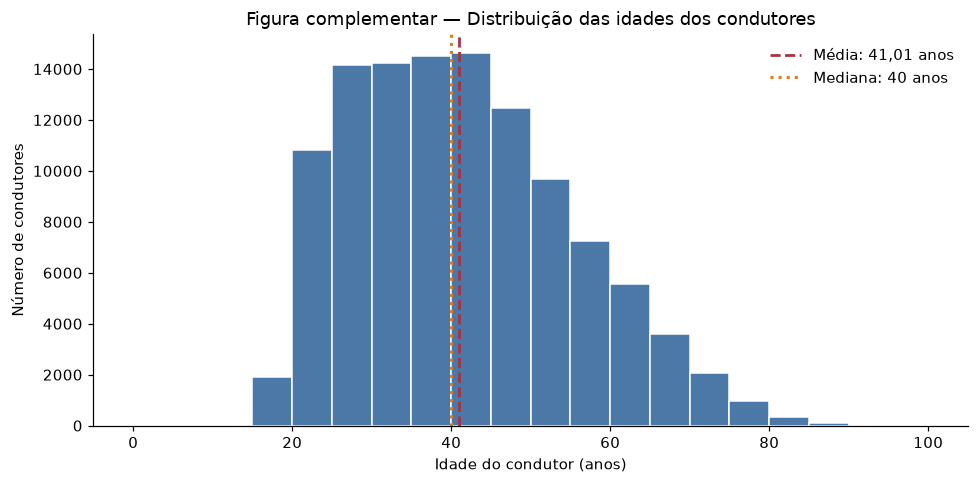

In [39]:
# Incluímos todos os dias do intervalo, inclusive eventuais dias com zero registros.
diario = acidentes.groupby('data_inversa').size().reindex(calendario, fill_value=0)
por_uf = acidentes['uf'].fillna('Não informado').value_counts()
por_br = acidentes['br'].astype('Int64').astype('string').fillna('Não informado').value_counts()

def resumo(serie):
    return pd.Series({'n': len(serie), 'média': serie.mean(), 'mediana': serie.median(),
                      'desvio-padrão': serie.std(ddof=0), 'mínimo': serie.min(),
                      'Q1': serie.quantile(0.25), 'Q3': serie.quantile(0.75),
                      'máximo': serie.max(), 'amplitude': serie.max() - serie.min()})

estatisticas = pd.DataFrame({
    'Acidentes por dia': resumo(diario),
    'Acidentes por UF': resumo(por_uf),
    'Idade dos condutores (anos)': resumo(cond_validos['idade'])
}).T
display(estatisticas.round(2))
print('Desvio-padrão populacional (ddof=0): descreve o conjunto observado.')

gravidade = (acidentes['classificacao_acidente'].fillna('Não informado')
             .value_counts().reindex(ORDEM_CLASSES, fill_value=0).to_frame('acidentes'))
gravidade['percentual'] = 100 * gravidade['acidentes'] / n_acidentes
display(gravidade.round(2))
print(f'Acidentes fatais entre os classificados: {taxa_fatal:.2f}%')

# Distribuição da idade dos condutores com idade conhecida
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(cond_validos['idade'], bins=range(0, 101, 5), color='#4c78a8', edgecolor='white')
ax.axvline(cond_validos['idade'].mean(), color='#a83240', linestyle='--', linewidth=1.8,
           label=f'Média: {cond_validos["idade"].mean():.2f}'.replace('.', ',')+' anos')
ax.axvline(cond_validos['idade'].median(), color='#e07a1f', linestyle=':', linewidth=2,
           label=f'Mediana: {cond_validos["idade"].median():.0f}'.replace('.', ',')+' anos')
ax.set(xlabel='Idade do condutor (anos)', ylabel='Número de condutores',
       title='Figura complementar — Distribuição das idades dos condutores')
ax.legend(frameon=False)
salvar_figura('2A')


**Resposta do grupo — tendência central, dispersão e distribuição.**

Nos 365 dias de 2025, a média foi de **198,71 acidentes por dia**, com mediana de **195** e desvio-padrão de **28,37**. A mediana indica o valor central dos dias ordenados, e o desvio-padrão resume a variação das contagens em torno da média. O mínimo foi 138 e o máximo 285, uma amplitude de 147 acidentes. Os quartis de 177 e 218 mostram que aproximadamente metade dos dias teve contagens nesse intervalo. Média e mediana próximas indicam valores centrais semelhantes, mas não comprovam, sozinhas, que a distribuição seja simétrica.

Entre as 27 UFs, a média de **2.686,26 acidentes** supera a mediana de **1.648**, com desvio-padrão de **2.581,45** e contagens entre 138 e 9.570. A diferença entre média e mediana, junto ao ranking da Pergunta 1, mostra a concentração dos registros em alguns estados. Essas contagens não medem o risco de circular em cada UF.

Entre os **112.336 condutores com idade conhecida**, a média é **41,01 anos**, a mediana 40 e o desvio-padrão 13,82; os quartis são 30 e 50 anos. O histograma mostra maior concentração entre 25 e 50 anos e uma cauda que se estende para idades mais altas. As idades registradas vão de 1 a 100 anos. O mínimo de 1 ano sugere inconsistência entre idade e papel de condutor. Na Pergunta 5, examinamos a influência dos registros abaixo de 12 anos sem alterar a base principal.

A classificação reúne **56.181 acidentes com vítimas feridas (77,46%)**, **11.138 sem vítimas (15,36%)**, **5.209 com vítimas fatais (7,18%)** e um sem classificação. Um acidente fatal pode também envolver feridos, mas aparece somente na categoria fatal dessa distribuição. Nas comparações entre fatais e não fatais, o denominador é 72.528, excluindo o caso desconhecido. Seu percentual aparece como 0,00% na tabela por arredondamento, embora a contagem seja um.

## 3.2 – Visualização e Interpretação dos Dados

### Pergunta 1 — Como a quantidade de acidentes varia entre UFs e rodovias federais?

**Justificativa.** Barras horizontais ordenadas facilitam a comparação das dez maiores contagens por UF e BR. Cada acidente é contado uma vez em cada agrupamento, independentemente da quantidade de pessoas ou tipos associados. Os percentuais usam os 72.529 acidentes como denominador. Os casos sem BR informada entram nesse total e na tabela de qualidade, mas ficam fora do ranking de rodovias conhecidas.

Dez maiores contagens por UF e BR:


,acidentes,percentual
uf,,
MG,9570,13.19
SC,8186,11.29
PR,7630,10.52
RJ,6428,8.86
RS,4899,6.75
SP,4683,6.46
BA,4108,5.66
GO,3196,4.41
PE,3013,4.15


,acidentes,percentual
br,,
101,13014,17.94
116,11021,15.2
40,3502,4.83
381,3496,4.82
153,2789,3.85
163,2519,3.47
364,2264,3.12
277,2157,2.97
262,1769,2.44


Cinco menores contagens por UF:


,acidentes,percentual
uf,,
AM,138,0.19
RR,142,0.20
AP,169,0.23
AC,280,0.39
SE,589,0.81


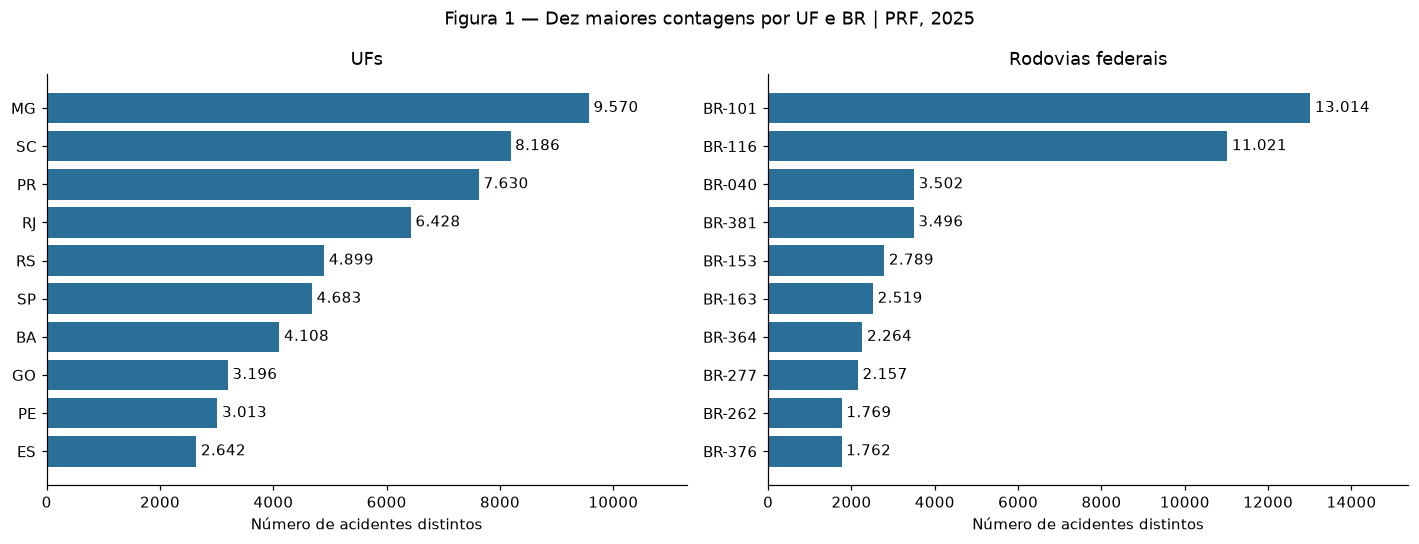

In [40]:
frequencia_uf = por_uf.to_frame('acidentes')
frequencia_uf['percentual'] = 100 * frequencia_uf['acidentes'] / n_acidentes
frequencia_br = por_br.to_frame('acidentes')
frequencia_br['percentual'] = 100 * frequencia_br['acidentes'] / n_acidentes
print('Dez maiores contagens por UF e BR:')
display(frequencia_uf.head(10).round(2))
display(frequencia_br.drop('Não informado', errors='ignore').head(10).round(2))
print('Cinco menores contagens por UF:')
display(frequencia_uf.sort_values('acidentes').head(5).round(2))

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for ax, serie, titulo in [(eixos[0], por_uf, 'UFs'),
                         (eixos[1], por_br.drop('Não informado', errors='ignore'), 'Rodovias federais')]:
    top = serie.head(10).sort_values()
    rotulos = ['BR-' + str(x).zfill(3) for x in top.index] if titulo == 'Rodovias federais' else top.index
    barras = ax.barh(rotulos, top.values, color='#2a6f97')
    ax.bar_label(barras, labels=[f'{int(v):,}'.replace(',', '.') for v in top.values], padding=3, fontsize=10)
    ax.set(title=titulo, xlabel='Número de acidentes distintos')
    ax.margins(x=0.18)
fig.suptitle('Figura 1 — Dez maiores contagens por UF e BR | PRF, 2025')
salvar_figura(1)

**Resposta do grupo — Figura 1.** Minas Gerais registra **9.570 acidentes**, Santa Catarina **8.186** e Paraná **7.630**. No outro extremo, Amazonas tem 138, Roraima 142 e Amapá 169. As cinco UFs com maiores contagens — MG, SC, PR, RJ e RS — concentram **50,62%** dos acidentes. As dez primeiras representam 74,94%, confirmando que as ocorrências não se distribuem uniformemente entre os estados.

Entre as rodovias, a **BR-101 tem 13.014 acidentes** e a **BR-116, 11.021**, seguidas pela BR-040, com 3.502. As duas primeiras reúnem **33,14%** do total; as dez primeiras, 61,07%. Há 167 acidentes sem BR informada, mantidos no denominador geral e contabilizados na tabela de qualidade da seção 3.3, mas fora do ranking de rodovias conhecidas.

Essas diferenças respondem onde se concentra o volume de registros. Não permitem ordenar a segurança das UFs ou das BRs: faltam medidas de exposição, como quantidade de veículos que circulam e distância percorrida. Também não permitem atribuir a concentração a tráfego, extensão ou infraestrutura sem dados adicionais.

### Pergunta 2 — Como as ocorrências se distribuem entre meses, dias da semana e horários?

**Justificativa.** As contagens mostram o volume registrado; a média por dia de calendário permite comparar meses de comprimentos diferentes e dias da semana com 52 ou 53 ocorrências no ano. Essa média corrige apenas o calendário, sem estimar exposição ao trânsito. Por exemplo, a média diária de dezembro é 6.788 ÷ 31 = 218,97 acidentes; a média dos sábados é 11.554 ÷ 52 = 222,19. O painel horário apresenta o total anual de cada faixa de uma hora. O mapa de calor também usa totais anuais e combina dia e hora para localizar concentrações que uma soma mensal esconderia.

Menor contagem por hora:


,acidentes
hora,
2,1160


Quatro maiores contagens por hora:


,acidentes
hora,
18,5398
17,4845
19,4646
7,4583


,acidentes,dias_no_periodo,media_por_dia
mes,,,
1,5528,31,178.32
2,5287,28,188.82
3,5960,31,192.26
4,5786,30,192.87
5,6096,31,196.65
6,6122,30,204.07
7,6238,31,201.23
8,6246,31,201.48
9,6017,30,200.57


,acidentes,dias_no_periodo,media_por_dia
dia_semana,,,
segunda-feira,10285,52,197.79
terça-feira,9062,52,174.27
quarta-feira,9556,53,180.30
quinta-feira,9405,52,180.87
sexta-feira,11197,52,215.33
sábado,11554,52,222.19
domingo,11470,52,220.58


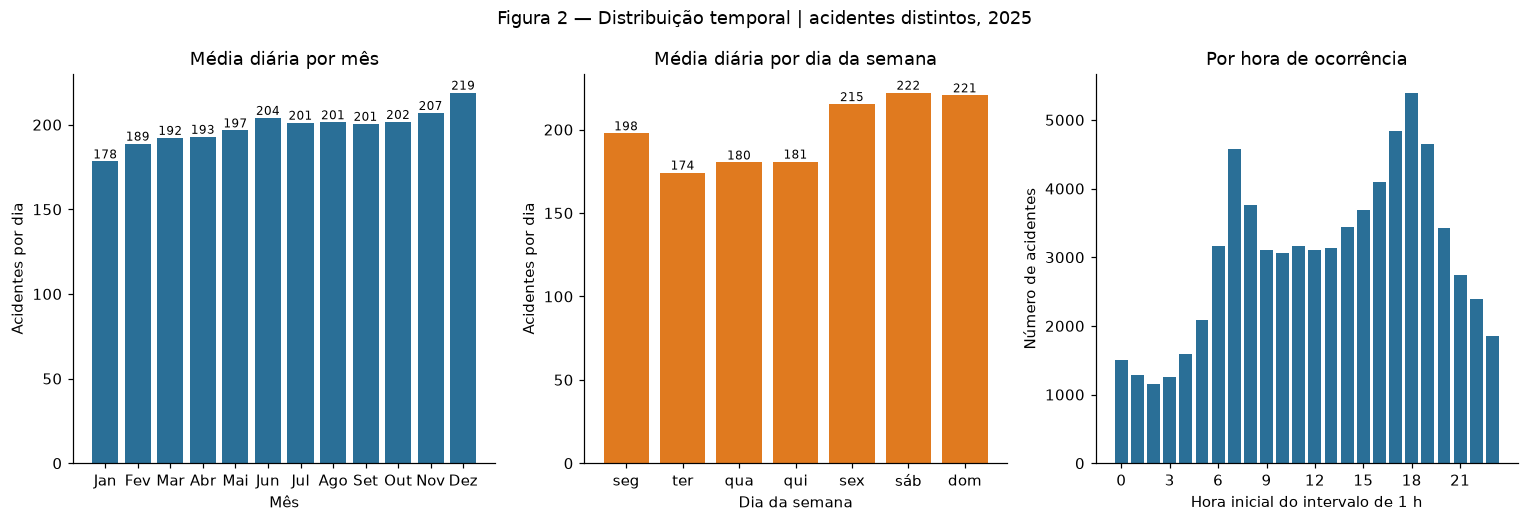

Três maiores células do mapa de calor:


,,acidentes
dia_semana,hora,
sexta-feira,18,878
domingo,19,863
segunda-feira,7,842


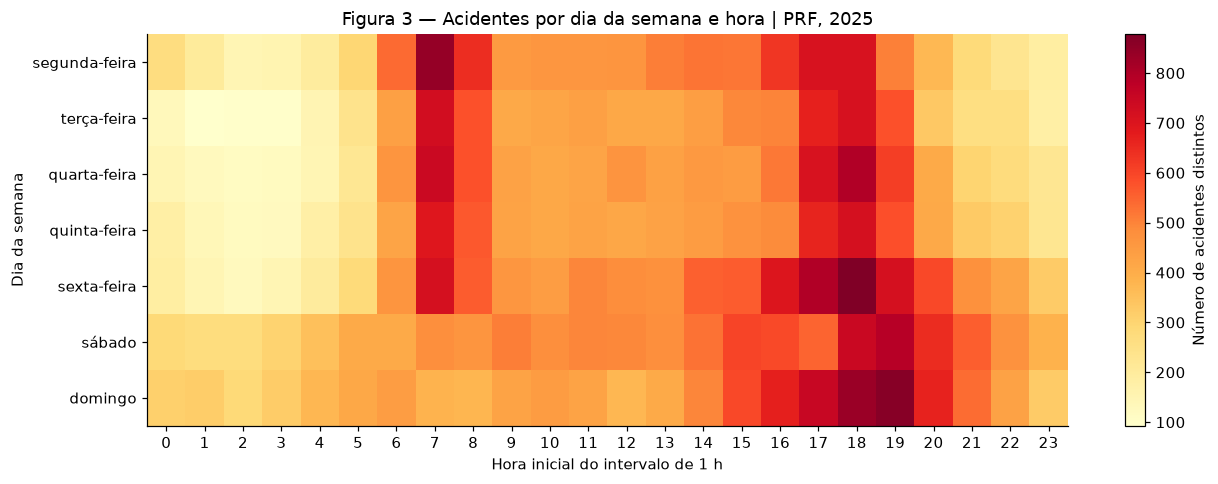

In [41]:
mensal = acidentes.groupby('mes').size().reindex(range(1, 13), fill_value=0).to_frame('acidentes')
mensal['dias_no_periodo'] = pd.Series(calendario.month).value_counts().reindex(mensal.index, fill_value=0)
mensal['media_por_dia'] = mensal['acidentes'] / mensal['dias_no_periodo'].replace(0, np.nan)
semanal = acidentes.groupby('dia_semana').size().reindex(ORDEM_DIAS, fill_value=0).to_frame('acidentes')
semanal['dias_no_periodo'] = [int((calendario.dayofweek == i).sum()) for i in range(7)]
semanal['media_por_dia'] = semanal['acidentes'] / semanal['dias_no_periodo']
por_hora = acidentes.groupby('hora').size().reindex(range(24), fill_value=0)
print('Menor contagem por hora:')
display(por_hora.sort_values(ascending=True).head(1).to_frame('acidentes'))
print("Quatro maiores contagens por hora:")
display(por_hora.sort_values(ascending=False).head(4).to_frame('acidentes'))
display(mensal.round(2))
display(semanal.round(2))

fig, eixos = plt.subplots(1, 3, figsize=(14, 4.8))
eixos[0].bar(mensal.index, mensal['media_por_dia'], color='#2a6f97')
for x, valor in zip(mensal.index, mensal['media_por_dia']):
    eixos[0].text(x, valor, f'{valor:.0f}', ha='center', va='bottom', fontsize=8)
nomes_meses = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
eixos[0].set(xticks=range(1, 13), xticklabels=nomes_meses, xlabel='Mês', ylabel='Acidentes por dia', title='Média diária por mês')
barras_semana = eixos[1].bar([d[:3] for d in ORDEM_DIAS], semanal['media_por_dia'], color='#e07a1f')
for barra, valor in zip(barras_semana, semanal['media_por_dia']):
    eixos[1].text(barra.get_x()+barra.get_width()/2, barra.get_height(), f'{valor:.0f}', ha='center', va='bottom', fontsize=8)
eixos[1].set(xlabel='Dia da semana', ylabel='Acidentes por dia', title='Média diária por dia da semana')
eixos[2].bar(por_hora.index, por_hora.values, color='#2a6f97')
eixos[2].set(xticks=range(0, 24, 3), xlabel='Hora inicial do intervalo de 1 h',
             ylabel='Número de acidentes', title='Por hora de ocorrência')
fig.suptitle('Figura 2 — Distribuição temporal | acidentes distintos, 2025')
salvar_figura(2)

mapa_calor = pd.crosstab(acidentes['dia_semana'], acidentes['hora']).reindex(
    index=ORDEM_DIAS, columns=range(24), fill_value=0)

print('Três maiores células do mapa de calor:')
maiores_celulas = mapa_calor.rename_axis(index='dia_semana', columns='hora').stack().sort_values(ascending=False).head(3)
display(maiores_celulas.rename('acidentes').to_frame())
fig, ax = plt.subplots(figsize=(12, 4.5))
imagem = ax.imshow(mapa_calor, aspect='auto', cmap='YlOrRd')
ax.set(xticks=range(24), yticks=range(7), yticklabels=ORDEM_DIAS,
       xlabel='Hora inicial do intervalo de 1 h', ylabel='Dia da semana',
       title='Figura 3 — Acidentes por dia da semana e hora | PRF, 2025')
fig.colorbar(imagem, ax=ax, label='Número de acidentes distintos')
salvar_figura(3)

**Resposta do grupo — Figuras 2 e 3.** Dezembro apresenta o maior total mensal, **6.788 acidentes**, e fevereiro o menor, **5.287**. A diferença é de 1.501 ocorrências. Ao dividir pelo número de dias de cada mês, dezembro continua com a maior média diária (**218,97 por dia**), mas o mínimo passa a ser janeiro (**178,32 por dia**). Fevereiro registra 188,82 por dia. Portanto, interpretar o menor total de fevereiro como a menor intensidade diária seria incorreto; o ajuste pelo calendário muda essa comparação. Um único ano permite descrever esse padrão, mas não demonstrar sazonalidade recorrente.

Sábado tem **11.554 acidentes**, domingo **11.470** e sexta-feira **11.197**; terça-feira tem o menor total, **9.062**. As médias de acidentes por dia da semana são, respectivamente, **222,19**, **220,58**, **215,33** e **174,27**. A concentração entre sexta e domingo permanece após o ajuste. A quarta-feira ocorre 53 vezes no ano e os demais dias, 52; essa diferença é tratada explicitamente na tabela.

Por horário, o intervalo **18h–18h59** reúne o maior volume, **5.398 acidentes**, seguido de 17h–17h59, com 4.845, e 19h–19h59, com 4.646. O intervalo de 7h também se destaca, com 4.583; o menor total está às 2h, com 1.160.

O mapa de calor detalha essa concentração: **sexta-feira às 18h tem 878 acidentes**, **domingo às 19h, 863**, e **segunda-feira às 7h, 842**. Nos dias úteis, há concentrações de manhã e no fim da tarde; no fim de semana, o pico matinal é menos pronunciado. Cada célula soma todas as ocorrências daquele dia e horário no ano, e não representa um único dia. Os dados localizam esses padrões, mas não medem os motivos dos deslocamentos nem o volume de tráfego que poderia explicá-los.

### Pergunta 3 — Como a proporção de acidentes com vítimas fatais varia entre os tipos de acidente?

**Justificativa.** Calculamos, para cada tipo, o percentual de fatais entre os acidentes com classificação conhecida. As barras ordenadas mostram esse percentual e o número de acidentes usado no cálculo. Um acidente com vários tipos participa de cada grupo correspondente; por isso, as contagens dos grupos não devem ser somadas. A classificação fatal se refere à ocorrência inteira e não identifica qual dos tipos registrados causou a morte.

,acidentes,fatais,pct_fatais
tipo_acidente,,,
Atropelamento de Pedestre,3407,1088,31.93
Colisão frontal,5277,1539,29.16
Derramamento de carga,890,112,12.58
Eventos atípicos,355,41,11.55
Colisão lateral sentido oposto,2447,261,10.67
Saída de leito carroçável,15091,1512,10.02
Capotamento,6004,547,9.11
Colisão com objeto,10460,883,8.44
Queda de ocupante de veículo,20474,1645,8.03


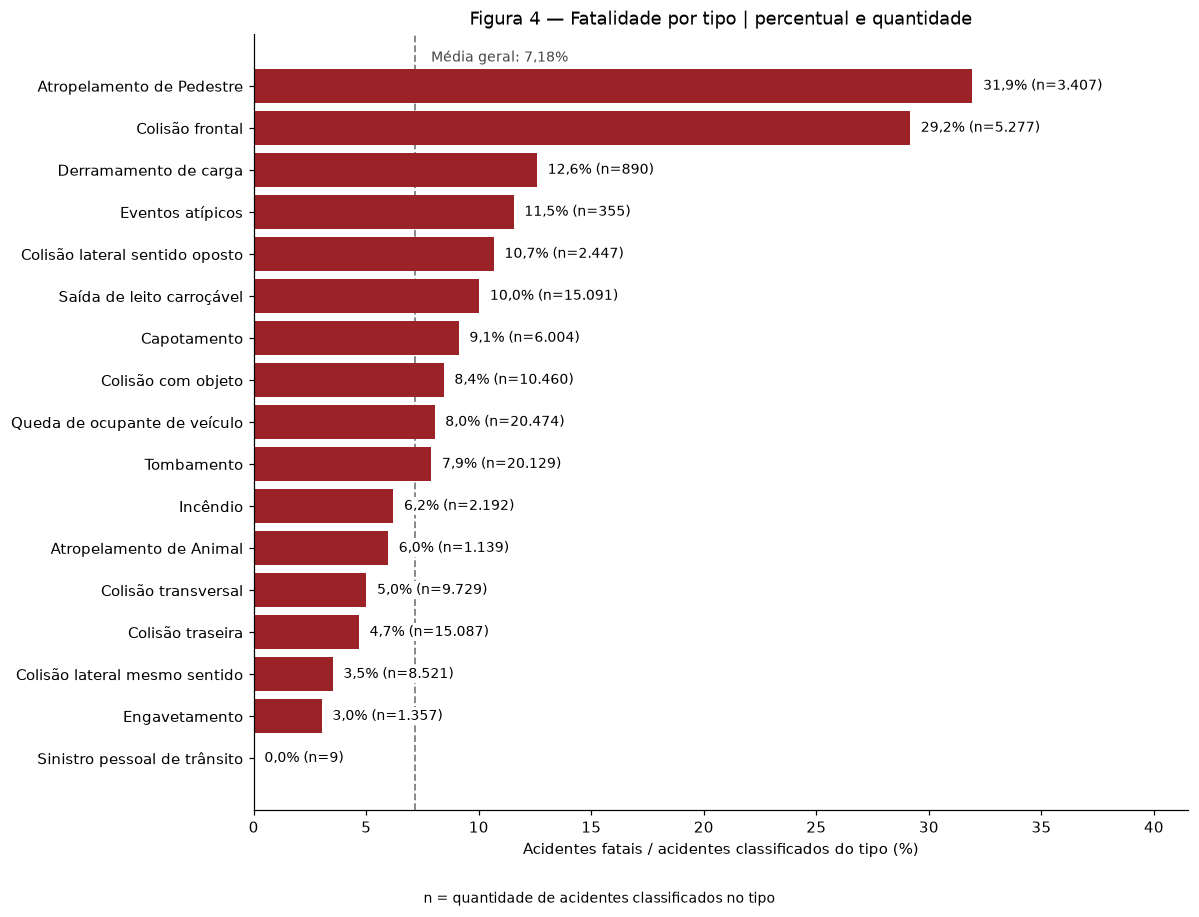

In [42]:
base_tipo = acidente_tipo.merge(classificados[['id', 'fatal']], on='id', validate='many_to_one')
por_tipo = base_tipo.groupby('tipo_acidente')['fatal'].agg(acidentes='size', fatais='sum')
por_tipo['pct_fatais'] = 100 * por_tipo['fatais'] / por_tipo['acidentes']
por_tipo = por_tipo.sort_values('pct_fatais', ascending=False)
display(por_tipo.round(2))

grafico_tipo = por_tipo.sort_values('pct_fatais')
fig, ax = plt.subplots(figsize=(11, 8))
barras = ax.barh(grafico_tipo.index, grafico_tipo['pct_fatais'], color='#9b2226')
rotulos = []
for p, n in zip(grafico_tipo['pct_fatais'], grafico_tipo['acidentes']):
    rotulos.append(f'{p:.1f}'.replace('.', ',') + '% (n=' + f'{n:,}'.replace(',', '.') + ')')
ax.bar_label(barras, labels=rotulos, padding=7, fontsize=9, zorder=3,
                 bbox={'facecolor':'white','edgecolor':'none','pad':1})
label_geral = f'Média geral: {taxa_fatal:.2f}'.replace('.', ',') + '%'
ax.axvline(taxa_fatal, color='gray', linestyle='--', linewidth=1.2, zorder=0)
ax.text(taxa_fatal + 0.7, len(grafico_tipo)-0.5, label_geral,
        color='#444444', fontsize=9, va='bottom')
ax.set(xlabel='Acidentes fatais / acidentes classificados do tipo (%)',
       title='Figura 4 — Fatalidade por tipo | percentual e quantidade')
fig.text(0.5, -0.02, 'n = quantidade de acidentes classificados no tipo', ha='center', va='top', fontsize=9)
ax.margins(x=0.30)
salvar_figura(4)

**Resposta do grupo — Figura 4.** A maior proporção fatal é observada em **atropelamento de pedestre: 1.088 de 3.407 acidentes (31,93%)**, seguida por **colisão frontal: 1.539 de 5.277 (29,16%)**. Ambas superam os **7,18%** do conjunto classificado. Entre tipos com mais de mil registros, engavetamento apresenta 41 fatais em 1.357 acidentes (**3,02%**) e colisão lateral no mesmo sentido, 299 em 8.521 (**3,51%**).

Os tipos mais frequentes não são os de maior proporção fatal. **Queda de ocupante de veículo** aparece em 20.474 acidentes, dos quais 1.645 são fatais (**8,03%**); **tombamento** aparece em 20.129, com 1.588 fatais (**7,89%**). Assim, uma categoria com proporção menor pode reunir mais acidentes fatais em números absolutos do que outra menos frequente.

A tabela preserva **sinistro pessoal de trânsito**, com zero fatais em apenas nove acidentes. Esse resultado não permite concluir que nunca ocorram fatalidades nesse tipo. Eventos atípicos também exigem cautela: são 41 fatais em 355 ocorrências, uma base menor que a dos principais grupos. As comparações descrevem a gravidade entre os acidentes registrados, sem estimar risco por viagem.

### Pergunta 4 — Como a gravidade varia entre condições meteorológicas e fases do dia?

**Justificativa.** Barras de composição de 100% permitem comparar a distribuição da gravidade entre grupos de tamanhos diferentes. Os dois painéis são ordenados pelo percentual fatal, e `n` indica o total de acidentes do grupo. Neve, com apenas um registro, fica somente na tabela completa.

A legenda destaca as três classes de gravidade conhecidas: sem vítimas, com feridos e com fatais. O único acidente sem classificação permanece na tabela e na composição das barras, em cinza, mas não recebe uma entrada na legenda porque sua parcela é quase imperceptível nessa escala. Uma nota abaixo da figura informa sua presença. Esse caso é diferente da linha de clima “Não informado”. Os rótulos vermelhos usam todos os acidentes do grupo como denominador. A tabela também apresenta a proporção fatal apenas entre classificações conhecidas; a diferença causada pelo único caso desconhecido é inferior a 0,01 ponto percentual.

classificacao_acidente,Sem Vítimas,Com Vítimas Feridas,Com Vítimas Fatais,Não informado,total,pct_fatais_classificados
condicao_metereologica,,,,,,
Céu Claro,7159,35797,3418,1,46375,7.37
Nublado,1673,8932,830,0,11435,7.26
Chuva,1053,4983,402,0,6438,6.24
Sol,513,3441,247,0,4201,5.88
Garoa/Chuvisco,411,1867,144,0,2422,5.95
Não informado,206,695,99,0,1000,9.90
Nevoeiro/Neblina,106,387,60,0,553,10.85
Vento,17,78,9,0,104,8.65
Neve,0,1,0,0,1,0.00


classificacao_acidente,Sem Vítimas,Com Vítimas Feridas,Com Vítimas Fatais,Não informado,total,pct_fatais_classificados
fase_dia,,,,,,
Pleno dia,5340,32986,2048,1,40375,5.07
Plena Noite,4542,17717,2522,0,24781,10.18
Anoitecer,567,3106,253,0,3926,6.44
Amanhecer,689,2372,386,0,3447,11.20


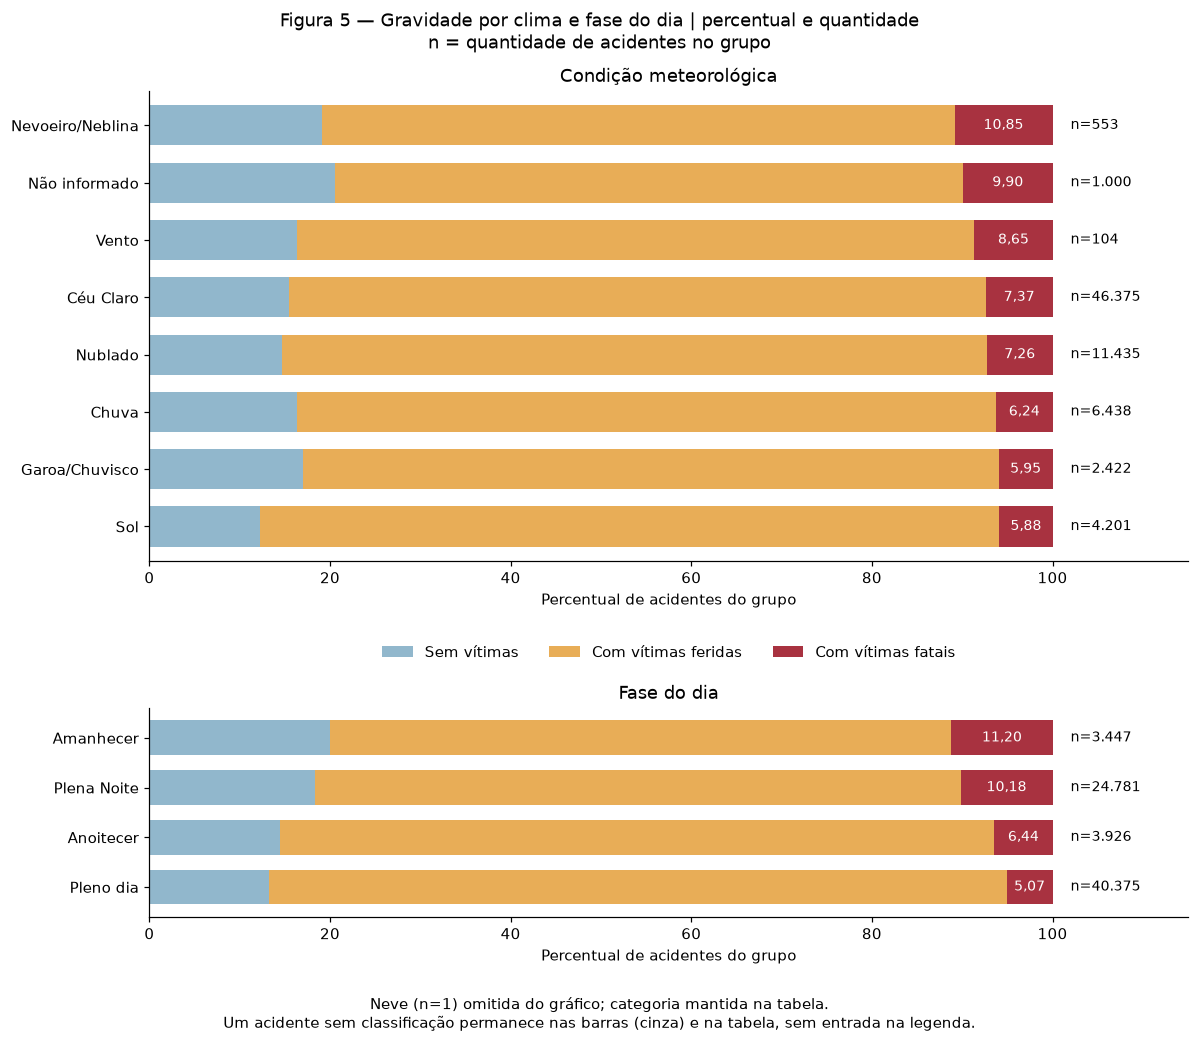

In [43]:
def tabela_gravidade(coluna):
    contagens = pd.crosstab(acidentes[coluna].fillna('Não informado'),
                           acidentes['classificacao_acidente'].fillna('Não informado'))
    contagens = contagens.reindex(columns=ORDEM_CLASSES, fill_value=0)
    contagens = contagens.loc[contagens.sum(axis=1).sort_values(ascending=False).index]
    percentuais = contagens.div(contagens.sum(axis=1), axis=0) * 100
    resumo = contagens.copy()
    resumo['total'] = contagens.sum(axis=1)
    resumo['pct_fatais_classificados'] = 100 * contagens['Com Vítimas Fatais'] / contagens[ORDEM_CLASSES[:3]].sum(axis=1).replace(0, np.nan)
    return resumo, percentuais

grav_clima, pct_clima = tabela_gravidade('condicao_metereologica')
grav_fase, pct_fase = tabela_gravidade('fase_dia')
display(grav_clima.round(2))
display(grav_fase.round(2))

fig, eixos = plt.subplots(2, 1, figsize=(11, 9), gridspec_kw={'height_ratios':[9,4]})
cores = ['#91b7cc', '#e8ad57', '#a83240', '#d4d4d4']
# Neve permanece na tabela completa; apenas o gráfico omite essa categoria (n=1).
# Ordenamos ambos os painéis pelo percentual fatal apresentado nas barras.
clima_grafico = pct_clima.drop(index='Neve', errors='ignore').sort_values(
    'Com Vítimas Fatais', ascending=False)
fase_grafico = pct_fase.sort_values('Com Vítimas Fatais', ascending=False)
for ax, tabela, totais, titulo in [(eixos[0], clima_grafico, grav_clima, 'Condição meteorológica'),
                                  (eixos[1], fase_grafico, grav_fase, 'Fase do dia')]:
    tabela.plot.barh(stacked=True, color=cores, ax=ax, legend=False, width=0.7)
    ax.invert_yaxis()
    for y, (categoria, linha) in enumerate(tabela.iterrows()):
        fatal = linha['Com Vítimas Fatais']
        n = int(totais.loc[categoria, 'total'])
        n_txt = f'{n:,}'.replace(',', '.')
        ax.text(102, y, f'n={n_txt}', va='center', fontsize=9)
        if fatal > 0:
            centro = linha['Sem Vítimas'] + linha['Com Vítimas Feridas'] + fatal/2
            ax.text(centro, y, f'{fatal:.2f}'.replace('.', ','), ha='center', va='center', color='white', fontsize=9)
    ax.set(xlim=(0, 115), xticks=range(0,101,20), xlabel='Percentual de acidentes do grupo', ylabel='', title=titulo)
# A legenda destaca as três classes conhecidas; o único caso ausente é explicado na nota.
rotulos_gravidade = ['Sem vítimas', 'Com vítimas feridas', 'Com vítimas fatais']
eixos[0].legend(eixos[0].containers[:3], rotulos_gravidade, loc='upper center',
                 bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False, fontsize=10)
fig.suptitle('Figura 5 — Gravidade por clima e fase do dia | percentual e quantidade\nn = quantidade de acidentes no grupo', fontsize=12)
fig.text(0.5, -0.015, 'Neve (n=1) omitida do gráfico; categoria mantida na tabela.\n'
         'Um acidente sem classificação permanece nas barras (cinza) e na tabela, sem entrada na legenda.',
         ha='center', va='top', fontsize=10)
salvar_figura(5)

**Resposta do grupo — Figura 5.** Acidentes com vítimas feridas predominam em todas as condições meteorológicas registradas. Em céu claro, representam **77,19%** dos 46.375 acidentes; sob chuva, **77,40%** dos 6.438. As parcelas sem vítimas são 15,44% e 16,36%, respectivamente, e as proporções fatais entre classificados são **7,37%** e **6,24%**.

**Nevoeiro/neblina apresenta 60 fatais em 553 acidentes (10,85%)**, a maior proporção entre as condições meteorológicas conhecidas. Vento registra nove fatais em 104 acidentes (8,65%). Como esses grupos são menores, poucos casos adicionais alterariam mais seus percentuais. Neve tem apenas um acidente, com vítimas feridas, o que não sustenta uma comparação. Os 1.000 acidentes sem condição meteorológica conhecida apresentam 9,90% de fatais.

Por fase do dia, a proporção fatal é **11,20% ao amanhecer (386/3.447)**, **10,18% em plena noite (2.522/24.781)**, **6,44% ao anoitecer (253/3.926)** e **5,07% em pleno dia (2.048/40.374 classificados)**. O total de pleno dia é 40.375, incluindo o caso sem classificação. A proporção noturna é aproximadamente o dobro da diurna.

A composição das outras classes ajuda a interpretar essa diferença: pleno dia tem **81,70%** de acidentes com feridos, contra **71,49%** à noite. A noite apresenta parcelas maiores tanto de fatais quanto de acidentes sem vítimas (**18,33%**, contra **13,23%** de dia). Portanto, a diferença não é um aumento uniforme de todas as categorias com vítimas.

Essas comparações não controlam diferenças de local, tipo de acidente ou tráfego. Elas mostram associações nos registros, sem demonstrar que clima ou luminosidade causem maior gravidade.

### Pergunta 5 — Como a participação de condutores menores de idade varia entre tipos de veículo e UFs?

**Justificativa.** Em cada grupo, calculamos **100 × condutores menores de 18 anos / condutores com idade conhecida**. A unidade é o condutor identificado por `pesid`, incluindo ciclistas. Condutores sem idade ficam fora do denominador e têm sua ausência informada separadamente. Também contamos os acidentes distintos com pelo menos um menor, pois uma ocorrência pode envolver vários condutores.

As tabelas mostram todos os tipos de veículo e UFs. O gráfico apresenta tipos com pelo menos 1.000 idades conhecidas e as dez maiores proporções por UF. Esses recortes facilitam a leitura, sem alterar os cálculos gerais. Os rótulos informam percentuais e denominadores, e a linha tracejada indica a participação geral. A análise de sensibilidade verifica quanto os registros de idades muito baixas influenciam o resultado.

,idade_conhecida,menores,pct_menores,pct_sem_idade
tipo_veiculo,,,,
Outros,54,5,9.26,84.75
Bicicleta,1565,112,7.16,8.96
Carroça-charrete,29,1,3.45,34.09
Trator de rodas,52,1,1.92,8.77
Ciclomotor,318,5,1.57,7.83
Motocicleta,29507,193,0.65,5.12
Motoneta,3167,19,0.60,3.62
Automóvel,40040,50,0.12,10.51
Utilitário,1945,2,0.10,5.21


,idade_conhecida,menores,pct_menores,pct_sem_idade
uf,,,,
TO,1059,16,1.51,6.94
AP,260,3,1.15,9.72
AM,190,2,1.05,6.86
MA,1950,18,0.92,12.95
RO,2382,20,0.84,7.13
PA,1576,12,0.76,19.34
PI,2308,16,0.69,9.91
MS,2343,14,0.60,7.72
ES,4120,22,0.53,9.91


Menores: 402 / 112336 condutores de idade conhecida (0,358%).
Acidentes distintos com pelo menos um condutor menor identificado: 398.


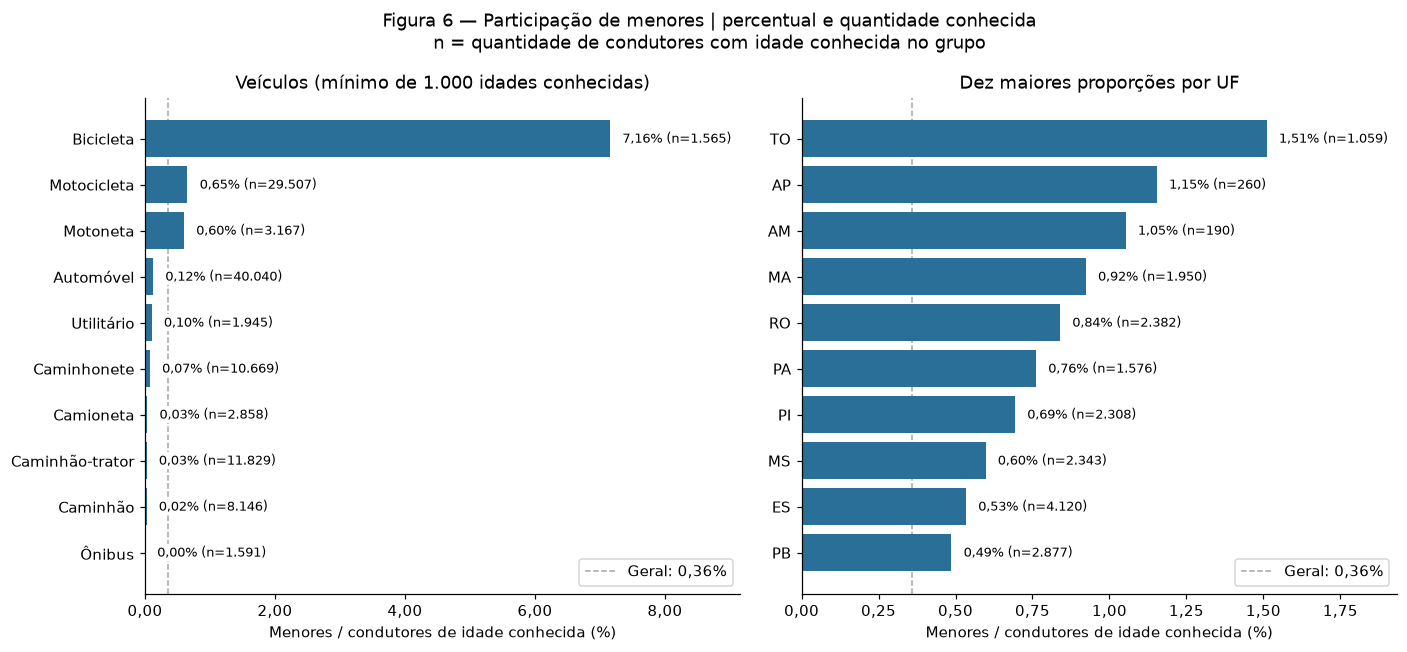

,idade mínima considerada,condutores,menores,pct_menores
0,0,112336,402,0.358
1,12,112323,389,0.346


condutores
idade tipo_veiculo               
1.0   Caminhonete               1
2.0   Motocicleta               1
3.0   Automóvel                 1
      Caminhão-trator           1
4.0   Caminhão-trator           1
7.0   Motocicleta               1
8.0   Bicicleta                 1
10.0  Bicicleta                 3
11.0  Bicicleta                 3

In [44]:
def participacao_menores(coluna):
    base = condutores.copy()
    base[coluna] = base[coluna].fillna('Não informado')
    base['idade_conhecida'] = base['idade'].notna()
    base['menor'] = base['idade'].notna() & base['idade'].lt(18)
    tabela = base.groupby(coluna).agg(condutores=('pesid','size'),
                                     idade_conhecida=('idade_conhecida','sum'),
                                     menores=('menor','sum'))
    tabela['sem_idade'] = tabela['condutores'] - tabela['idade_conhecida']
    tabela['pct_sem_idade'] = 100 * tabela['sem_idade'] / tabela['condutores']
    tabela['pct_menores'] = 100 * tabela['menores'] / tabela['idade_conhecida'].replace(0,np.nan)
    return tabela.sort_values('pct_menores', ascending=False)

menores_veiculo = participacao_menores('tipo_veiculo')
menores_uf = participacao_menores('uf')
colunas_exibidas = ['idade_conhecida','menores','pct_menores','pct_sem_idade']
display(menores_veiculo[colunas_exibidas].round(2))
display(menores_uf[colunas_exibidas].round(2))

n_menores = int(cond_validos['menor'].sum())
pct_menores = 100 * cond_validos['menor'].mean()
acidentes_com_menor = cond_validos.loc[cond_validos['menor'], 'id'].nunique()
print(f'Menores: {n_menores} / {len(cond_validos)} condutores de idade conhecida ({pct_menores:.3f}'.replace('.', ',') + '%).')
print(f'Acidentes distintos com pelo menos um condutor menor identificado: {acidentes_com_menor}.')

fig, eixos = plt.subplots(1,2,figsize=(13,6))
for ax,tabela,titulo in [(eixos[0],menores_veiculo[menores_veiculo['idade_conhecida'] >= 1000],
                          'Veículos (mínimo de 1.000 idades conhecidas)'),
                         (eixos[1],menores_uf.head(10),'Dez maiores proporções por UF')]:
    tabela = tabela.sort_values('pct_menores')
    barras = ax.barh(tabela.index,tabela['pct_menores'],color='#2a6f97')
    rotulos=[]
    for p,n in zip(tabela['pct_menores'],tabela['idade_conhecida']):
        rotulos.append(f'{p:.2f}'.replace('.', ',') + '% (n=' + f'{n:,}'.replace(',', '.') + ')')
    ax.bar_label(barras,labels=rotulos,padding=8,fontsize=8.5,zorder=3,
                 bbox={'facecolor':'white','edgecolor':'none','pad':1})
    label_geral=f'Geral: {pct_menores:.2f}'.replace('.', ',')+'%'
    ax.axvline(pct_menores,color='gray',linestyle='--',linewidth=1.0,alpha=0.7,label=label_geral,zorder=-1)
    ax.set(xlabel='Menores / condutores de idade conhecida (%)',title=titulo)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, pos: f'{valor:.2f}'.replace('.', ',')))
    ax.margins(x=0.28)
    ax.legend(loc='lower right')
fig.suptitle('Figura 6 — Participação de menores | percentual e quantidade conhecida\nn = quantidade de condutores com idade conhecida no grupo', fontsize=12)
salvar_figura(6)

sensibilidade=[]
for limite in [0,12]:
    grupo=cond_validos[cond_validos['idade'] >= limite]
    sensibilidade.append({'idade mínima considerada':limite,'condutores':len(grupo),
                          'menores':int(grupo['menor'].sum()),
                          'pct_menores':100*grupo['menor'].mean()})
display(pd.DataFrame(sensibilidade).round(3))
display(cond_validos.loc[cond_validos['idade'] < 12].groupby(['idade','tipo_veiculo'],dropna=False).size().rename('condutores').to_frame())

**Resposta do grupo — Figura 6.** Há **402 menores em 112.336 condutores com idade conhecida (0,358%)**, envolvidos em **398 acidentes distintos**. Entre os 122.367 condutores identificados, 10.031 estão sem idade válida (**8,20%**) e ficam fora do denominador. A participação é calculada por pessoa; um acidente pode envolver mais de um condutor menor.

Entre tipos com pelo menos mil idades conhecidas, **bicicleta lidera proporcionalmente: 112/1.565 (7,16%)**, seguida por **motocicleta: 193/29.507 (0,65%)** e **motoneta: 19/3.167 (0,60%)**. Automóvel tem 50/40.040 (0,12%). Em números absolutos, motocicletas concentram mais menores: **193 dos 402 (48,01%)**. A categoria Outros, fora do gráfico pelo tamanho da base, tem 5/54 (9,26%), mas 84,75% de seus condutores estão sem idade; por isso, a tabela completa e a cobertura são essenciais para interpretar os percentuais.

As maiores proporções por UF são **TO: 16/1.059 (1,51%)**, **AP: 3/260 (1,15%)** e **AM: 2/190 (1,05%)**. Já os maiores números de menores são SC (50), MG (40) e PR (34), disponíveis na tabela completa. A posição de AP e AM depende de apenas três e dois casos. A ausência de idade também varia por UF, chegando a 19,34% no PA, o que pode afetar as comparações.

Há 13 condutores com idade registrada abaixo de 12 anos, sete associados a bicicletas e seis a veículos motorizados. Sem esses registros, a participação seria **389/112.323 = 0,346%**, próxima dos 0,358% da análise principal. Essa comparação mede a influência das idades baixas, sem modificar a limpeza do RA1 ou validar os demais registros. Os resultados descrevem os envolvidos registrados, não o risco de um menor se acidentar; idades e identificações ausentes limitam a cobertura.

## 3.3 – Amostragem e Representatividade

**Procedimento.** Utilizamos todos os registros pertinentes das tabelas preparadas no RA1, sem sorteio de amostra nem preenchimento de idades por estimativa. Os casos sem classificação são excluídos apenas dos cálculos que exigem distinguir fatal e não fatal. Os recortes visuais não alteram as tabelas completas; a separação de treino e teste pertence somente ao modelo da seção 3.4.

In [45]:
qualidade = pd.DataFrame([
    ['UFs com registro', acidentes['uf'].nunique(), n_acidentes, 'acidentes'],
    ['Sem classificação', acidentes['classificacao_acidente'].isna().sum(), n_acidentes, 'acidentes'],
    ['Sem condição meteorológica', acidentes['condicao_metereologica'].isna().sum(), n_acidentes, 'acidentes'],
    ['Sem BR', acidentes['br'].isna().sum(), n_acidentes, 'acidentes'],
    ['Sem quilometragem', acidentes['km'].isna().sum(), n_acidentes, 'acidentes'],
    ['Sem hora', acidentes['hora'].isna().sum(), n_acidentes, 'acidentes'],
    ['Sem identificação de pessoa', n_sem_pesid, n_linhas, 'linhas da extração'],
    ['Condutores sem idade válida', condutores['idade'].isna().sum(), len(condutores), 'condutores identificados']
], columns=['indicador', 'quantidade', 'denominador', 'unidade'])
qualidade['percentual'] = 100 * qualidade['quantidade'] / qualidade['denominador']
qualidade.loc[qualidade['indicador'].eq('UFs com registro'), 'percentual'] = np.nan
display(qualidade.round(3))
print(f'Dias no intervalo: {len(calendario)}; dias com registros: {(diario > 0).sum()}')

,indicador,quantidade,denominador,unidade,percentual
0,UFs com registro,27,72529,acidentes,NaN
1,Sem classificação,1,72529,acidentes,0.001
2,Sem condição meteorológica,1000,72529,acidentes,1.379
3,Sem BR,167,72529,acidentes,0.230
4,Sem quilometragem,167,72529,acidentes,0.230
5,Sem hora,0,72529,acidentes,0.000
6,Sem identificação de pessoa,56801,584010,linhas da extração,9.726
7,Condutores sem idade válida,10031,122367,condutores identificados,8.197


Dias no intervalo: 365; dias com registros: 365


**Origem e abrangência.** A extração de acidentes da PRF, agrupada por pessoa e por múltiplas causas e tipos, contém **584.010 linhas, 37 colunas, 72.529 acidentes e 177.479 pessoas identificadas**. Cobre os 365 dias de 2025 e as 27 UFs. É adequada para descrever os acidentes registrados em rodovias federais, mas não representa todas as vias brasileiras nem garante que todos os acidentes ocorridos tenham sido registrados.

**Limitações e possíveis vieses.** Há **56.801 linhas sem identificação de pessoa (9,73%)**, que não equivalem necessariamente a pessoas distintas, e **10.031 condutores identificados sem idade válida (8,20%)**. A ausência de idade varia por UF e veículo. Se ela também variar entre menores e adultos, a participação calculada com idades conhecidas poderá diferir da participação entre todos os condutores; não sabemos em qual direção. A análise de sensibilidade da Pergunta 5 examina as idades baixas suspeitas, mas não valida os demais registros.

Também há **1.000 acidentes sem condição meteorológica (1,38%)**, 167 sem BR e 167 sem quilometragem (0,23% em cada campo), um sem classificação e nenhum sem hora válida. Não medimos a cobertura do registro da PRF nem sua possível variação por gravidade. Sem dados de circulação, as contagens não se tornam taxas de risco; com apenas um ano, não podemos confirmar sazonalidade recorrente ou tendências de longo prazo.

## 3.4 – Aplicação de Machine Learning

**Problema preditivo.** Queremos verificar se o contexto geográfico, temporal e meteorológico permite distinguir acidentes com vítimas fatais dos demais acidentes classificados. É uma **classificação binária**, com uma linha por acidente distinto (`id`). O modelo classifica a gravidade entre acidentes registrados; não estima a chance de uma viagem terminar em acidente.

**Entradas e alvo.** O alvo `fatal` vale **1** para `Com Vítimas Fatais` e **0** para `Com Vítimas Feridas` ou `Sem Vítimas`. Excluímos o único acidente sem classificação. As sete entradas são `uf`, `br`, `mes`, `hora`, `dia_semana`, `fase_dia` e `condicao_metereologica`. A classificação original e os indicadores de mortos e feridos ficam fora das entradas porque revelariam o resultado que queremos prever.

Tratamos as entradas como categorias para não impor uma relação numérica a códigos de rodovia ou uma relação linear aos horários. O `OneHotEncoder` cria colunas indicadoras para essas categorias. O `Pipeline` aprende a codificação somente nos dados de treino, inclusive em cada rodada de validação. Ausências recebem “Não informado”, e `handle_unknown='ignore'` permite processar categorias novas no teste. O campo `tipo_acidente` fica restrito à análise descritiva da Pergunta 3: o modelo utiliza variáveis de contexto, e representar esse campo exigiria considerar os vários tipos presentes em **33.348 acidentes**. Essa quantidade é calculada na preparação do RA3: contamos os tipos distintos de cada `id` e somamos os acidentes com mais de um tipo (`n_acidentes_multiplos_tipos`).

**Modelo escolhido.** Usamos regressão logística, que permite uma implementação simples de classificação binária. Comparamos a versão sem pesos com `class_weight='balanced'`, que dá mais peso à classe fatal, menos frequente, durante o treino. Isso não cria registros nem altera o teste. A referência (*baseline*) sempre prevê a classe majoritária e ajuda a avaliar se a acurácia esconde a dificuldade de detectar fatais.

**Treino, validação e teste.** Dividimos os 72.528 acidentes classificados em **58.022 para treino e 14.506 para teste**, aproximadamente 80%/20%. `stratify=y` preserva proporções semelhantes das classes, e `random_state=42` permite reproduzir a divisão. Um mesmo acidente não participa dos dois conjuntos.

O **limiar** é o corte do escore para prever “fatal”: valores maiores ou iguais ao corte recebem essa classe; os demais recebem “não fatal”. Reduzi-lo tende a detectar mais fatais e também a gerar mais falsos positivos. Para escolhê-lo, usamos validação cruzada estratificada de cinco partes dentro do treino: cada parte recebe previsões de um modelo treinado nas outras quatro. Entre os cortes listados no código, selecionamos o maior F1 dessas previsões para cada versão. Os modelos ajustados com todo o treino são então avaliados no teste com os cortes fixados, sem usar o teste para escolhê-los. Os escores não foram calibrados como probabilidades reais; um corte de 0,60 não garante uma probabilidade real de 60%.

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)

FEATURES = ['uf','br','mes','hora','dia_semana','fase_dia','condicao_metereologica']
base_ml = classificados.sort_values('id').set_index('id')
X = base_ml[FEATURES].astype('string').fillna('Não informado')
y = base_ml['fatal'].astype(int)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

modelos = {}
for nome, peso in [('Regressão logística equilibrada','balanced'),
                   ('Regressão logística não equilibrada',None)]:
    modelo = Pipeline([
        ('categorias',OneHotEncoder(handle_unknown='ignore')),
        ('classificador',LogisticRegression(class_weight=peso,max_iter=1000,random_state=42))
    ])
    modelo.fit(X_treino,y_treino)
    modelos[nome] = modelo

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_treino,y_treino)
escore_base = referencia.predict_proba(X_teste)[:,1]
previsao_base = referencia.predict(X_teste)

print(f'Acidentes sem rótulo excluídos: {n_acidentes-len(base_ml)}')
display(pd.DataFrame({'conjunto':['Treino','Teste'],'acidentes':[len(y_treino),len(y_teste)],
                      'fatais':[int(y_treino.sum()),int(y_teste.sum())],
                      'pct_fatais':[100*y_treino.mean(),100*y_teste.mean()]}).round(2))

Acidentes sem rótulo excluídos: 1


,conjunto,acidentes,fatais,pct_fatais
0,Treino,58022,4167,7.18
1,Teste,14506,1042,7.18


### Avaliação e interpretação

Comparamos previsões e classes verdadeiras dos acidentes de teste, considerando **fatal** como classe positiva. Na matriz de confusão, VP e VN são os acertos para fatais e não fatais. FP é um não fatal previsto como fatal; FN é um fatal previsto como não fatal.

| Métrica | Como interpretar neste projeto |
|---|---|
| **Acurácia** | Parcela de todos os acidentes classificados corretamente: `(VP + VN) / total`. Pode ser alta mesmo sem detectar fatais, porque eles são minoria. |
| **Precisão fatal** | Entre os previstos como fatais, quantos realmente são fatais: `VP / (VP + FP)`. Mede a confiabilidade dessas previsões. |
| **Recall fatal** | Entre os realmente fatais, quantos foram identificados: `VP / (VP + FN)`. Mede a cobertura da detecção. |
| **F1 fatal** | Média harmônica de precisão e recall. É baixo quando uma dessas medidas é baixa; usamos F1 para escolher o limiar na validação. |
| **AUC-ROC** | Avalia a capacidade de atribuir escores maiores aos fatais do que aos não fatais. O valor 0,5 indica ausência de discriminação e 1, separação perfeita nesse conjunto. Não é uma porcentagem de acertos. |
| **Average Precision (AP)** | Resume a precisão ao longo dos níveis de recall, sendo útil para avaliar a classe fatal minoritária. Deve ser comparada com a referência na mesma base. |

As quatro primeiras métricas dependem do limiar aplicado. AUC-ROC e AP usam a ordenação dos escores, sem depender de um único corte. A matriz complementa as métricas ao mostrar quantos acidentes foram classificados corretamente e quais erros ocorreram.

Limiar escolhido por validação — Regressão logística equilibrada: 0.60


Limiar escolhido por validação — Regressão logística não equilibrada: 0.10


,modelo,limiar,F1 na validação,precisão na validação,recall na validação
0,Regressão logística equilibrada,0.05,0.1342,0.0719,1.0000
1,Regressão logística equilibrada,0.10,0.1344,0.0720,0.9990
2,Regressão logística equilibrada,0.20,0.1360,0.0730,0.9942
3,Regressão logística equilibrada,0.30,0.1486,0.0808,0.9299
4,Regressão logística equilibrada,0.40,0.1722,0.0967,0.7867
5,Regressão logística equilibrada,0.50,0.1940,0.1160,0.5920
6,Regressão logística equilibrada,0.60,0.2079,0.1449,0.3679
7,Regressão logística equilibrada,0.70,0.1927,0.1918,0.1937
8,Regressão logística não equilibrada,0.05,0.1729,0.0972,0.7807
9,Regressão logística não equilibrada,0.10,0.2068,0.1413,0.3854


,acurácia,precisão fatal,recall fatal,F1 fatal,AUC-ROC,Average Precision (AP)
modelo,,,,,,
Referência: classe majoritária,0.9282,0.0000,0.0000,0.0000,0.5000,0.0718
"Regressão logística equilibrada | limiar validado 0,60",0.8018,0.1441,0.3560,0.2051,0.6652,0.1471
"Regressão logística não equilibrada | limiar validado 0,10",0.7915,0.1409,0.3733,0.2046,0.6654,0.1476


Configurações finais avaliadas no teste:
Regressão logística equilibrada | limiar 0,60 | VP=371, FP=2204, FN=671, VN=11260
Regressão logística não equilibrada | limiar 0,10 | VP=389, FP=2371, FN=653, VN=11093


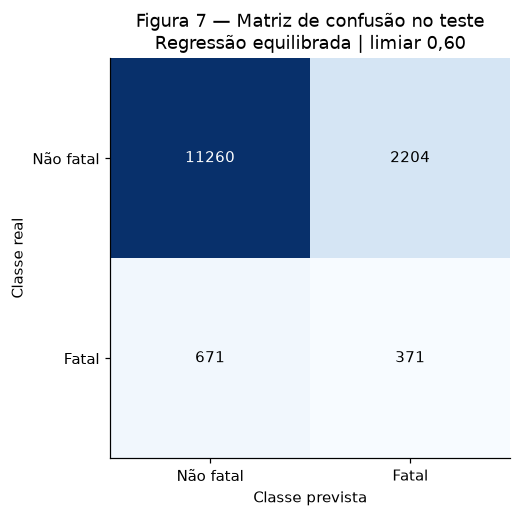

In [47]:
def avaliar(nome, previsto, probabilidades):
    return {'modelo': nome,
            'acurácia': accuracy_score(y_teste, previsto),
            'precisão fatal': precision_score(y_teste, previsto, zero_division=0),
            'recall fatal': recall_score(y_teste, previsto, zero_division=0),
            'F1 fatal': f1_score(y_teste, previsto, zero_division=0),
            'AUC-ROC': roc_auc_score(y_teste, probabilidades),
            'Average Precision (AP)': average_precision_score(y_teste, probabilidades)}

from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

limiares = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
limiares_por_modelo = {}
linhas_validacao = []

for nome, modelo in modelos.items():
    escores_validacao = cross_val_predict(
        clone(modelo), X_treino, y_treino,
        cv=5, method='predict_proba', n_jobs=-1)[:, 1]
    tabela_modelo = pd.DataFrame([
        {'modelo': nome,
         'limiar': limiar,
         'F1 na validação': f1_score(y_treino, escores_validacao >= limiar),
         'precisão na validação': precision_score(y_treino, escores_validacao >= limiar, zero_division=0),
         'recall na validação': recall_score(y_treino, escores_validacao >= limiar, zero_division=0)}
        for limiar in limiares
    ])
    linhas_validacao.append(tabela_modelo)
    melhor_validacao = tabela_modelo.sort_values('F1 na validação', ascending=False).iloc[0]
    limiares_por_modelo[nome] = float(melhor_validacao['limiar'])
    print(f"Limiar escolhido por validação — {nome}: {limiares_por_modelo[nome]:.2f}")

validacao_limite = pd.concat(linhas_validacao, ignore_index=True)
display(validacao_limite.round(4))

linhas_metricas=[]
for nome, modelo in modelos.items():
    escore = modelo.predict_proba(X_teste)[:,1]
    limiar = limiares_por_modelo[nome]
    previsto = escore >= limiar
    linhas_metricas.append(avaliar(
        nome + ' | limiar validado ' + f'{limiar:.2f}'.replace('.', ','), previsto, escore))
linhas_metricas.insert(0, avaliar('Referência: classe majoritária', previsao_base, escore_base))
metricas = pd.DataFrame(linhas_metricas).set_index('modelo')
display(metricas.round(4))

matrizes=[]
for nome, modelo in modelos.items():
    escore = modelo.predict_proba(X_teste)[:,1]
    previsto = escore >= limiares_por_modelo[nome]
    matriz = confusion_matrix(y_teste, previsto, labels=[0,1])
    vn,fp,fn,vp = matriz.ravel()
    matrizes.append((nome,limiares_por_modelo[nome],vp,fp,fn,vn))

print('Configurações finais avaliadas no teste:')
for nome, limiar, vp, fp, fn, vn in matrizes:
    print(f'{nome} | limiar ' + f'{limiar:.2f}'.replace('.', ',') + f' | VP={vp}, FP={fp}, FN={fn}, VN={vn}')

nome_melhor = 'Regressão logística equilibrada'
escore_melhor = modelos[nome_melhor].predict_proba(X_teste)[:,1]
limiar_melhor = limiares_por_modelo[nome_melhor]
previsao_melhor = escore_melhor >= limiar_melhor
matriz = confusion_matrix(y_teste, previsao_melhor, labels=[0,1])
vn,fp,fn,vp = matriz.ravel()

fig, ax = plt.subplots(figsize=(5.5,4.8))
ax.imshow(matriz,cmap='Blues')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Não fatal','Fatal'],
       yticklabels=['Não fatal','Fatal'],xlabel='Classe prevista',ylabel='Classe real',
       title='Figura 7 — Matriz de confusão no teste\nRegressão equilibrada | limiar ' + f'{limiar_melhor:.2f}'.replace('.', ',') )
for i in range(2):
    for j in range(2):
        ax.text(j,i,str(matriz[i,j]),ha='center',va='center',
                color='white' if matriz[i,j] > matriz.max()/2 else 'black')
salvar_figura(7)

**Resposta do grupo — desempenho e limitações.** A validação selecionou o limiar **0,60** para a regressão equilibrada (F1 de validação 0,2079) e **0,10** para a não equilibrada (0,2068). A Figura 7 apresenta a versão equilibrada por seu maior F1 na validação.

No teste, a versão equilibrada obteve **80,18% de acurácia, 14,41% de precisão fatal, 35,60% de recall e F1 de 0,2051**. Dos 1.042 acidentes fatais, identificou **371** e deixou passar **671**. Também classificou **2.204 não fatais como fatais**. Em termos práticos, reconhece aproximadamente 36 de cada 100 fatais, mas apenas 14 de cada 100 previsões de fatalidade estão corretas. A maioria dos fatais continua sem identificação, e há muitos falsos positivos.

A versão não equilibrada detectou **389 fatais**, com **2.371 falsos positivos** e **653 falsos negativos**. Seu recall foi **37,33%**, a precisão **14,09%** e o F1 **0,2046**. Ela detecta um pouco mais de fatais, mas gera mais falsos positivos. Como os F1 são muito próximos, a comparação não mostra uma vantagem clara de uma versão.

A referência de classe majoritária alcança **92,82% de acurácia**, mas nunca prevê fatal e tem recall e F1 iguais a zero. Por isso, a acurácia isolada daria uma impressão enganosa de desempenho. Precisão, recall e F1 mostram se o modelo consegue detectar a classe de interesse e a que custo em erros.

As duas regressões têm **AUC-ROC próxima de 0,665**, acima da referência de 0,5, mas com separação limitada entre as classes. Seus valores de **AP, próximos de 0,147**, superam a referência de 0,072. Isso indica que os escores ajudam a ordenar os casos, embora os resultados ainda sejam insuficientes para justificar uso operacional direto. Os valores completos estão na tabela de métricas.

A avaliação usa uma divisão aleatória da mesma extração de 2025 e não verifica desempenho em anos futuros ou em outras vias. O modelo sugere alguma capacidade de classificação com as variáveis disponíveis, mas seria necessária validação com dados posteriores e definição dos custos de falsos positivos e negativos antes de considerar uma aplicação prática.

## 3.5 – Conclusões do RA3

**Conclusões do grupo.** Os **72.529 acidentes registrados em 2025** apresentaram média de **198,71 por dia**, mediana de 195 e desvio-padrão de 28,37. A dispersão diária e as diferenças entre UFs mostram que o volume de registros varia no tempo e no território.

As análises responderam às cinco perguntas do RA1:

1. **UFs e rodovias:** MG, SC e PR concentram as maiores contagens. BR-101 e BR-116 reúnem **33,14%** dos acidentes.
2. **Meses, dias e horários:** dezembro tem a maior média diária (**218,97**); as ocorrências se concentram entre sexta-feira e domingo e atingem o maior total horário entre **18h e 18h59**.
3. **Tipo de acidente:** atropelamento de pedestre (**31,93%**) e colisão frontal (**29,16%**) apresentam as maiores proporções fatais, acima dos tipos mais frequentes.
4. **Clima e fase do dia:** nevoeiro/neblina tem proporção fatal de **10,85%**, com base menor que céu claro. Por fase do dia, destacam-se amanhecer (**11,20%**) e plena noite (**10,18%**), acima de pleno dia (**5,07%**).
5. **Condutores menores:** representam **0,358%** dos condutores com idade conhecida. Entre os veículos exibidos, bicicletas têm a maior participação relativa, enquanto motocicletas reúnem mais menores em números absolutos. TO lidera proporcionalmente entre as UFs.

**Machine Learning.** As duas regressões tiveram desempenho semelhante e limitado. A versão equilibrada alcançou F1 de **0,2051**: identificou aproximadamente 36% dos fatais, com apenas 14% de acertos entre suas previsões de fatalidade. As variáveis de contexto oferecem alguma informação preditiva, mas os erros impedem recomendar uso operacional direto.

**Alcance dos resultados.** O trabalho caracteriza onde e quando os acidentes registrados se concentram e como sua gravidade e a participação de menores variam. Faltam dados de exposição ao trânsito, há idades ausentes e grupos pequenos, e o recorte cobre somente um ano de rodovias federais. Assim, os resultados não medem risco por viagem, não demonstram causalidade e não garantem generalização. Melhorar a cobertura dos dados e avaliar o modelo em outro período são passos necessários para avançar.